# DMET904 – Milestone 1: Formula 1 Podium Prediction

**Task.** For every driver entering a Formula 1 race, predict whether he finishes on the podium (`positionOrder <= 3`) using only information available after qualifying and before the race starts. Unit of analysis: one driver in one race.


**Notebook map.** 1 Data loading · 2 EDA before cleaning · 3 Cleaning (sentinels, typing, grain, keys) · 4 EDA after cleaning · 5 Data-engineering questions Q1–Q3 · Requirement 3 features & preprocessing · Requirement 4 models · Requirement 5 ablation · Requirement 6 XAI · Inference function. The notebook runs top to bottom with Run All.

**Prediction cutoff used to judge every field:** after qualifying, before the race. Results, points, status, laps, pit stops and post-race standings are post-race information. They are used only to *define the target* (`podium = positionOrder <= 3`) or to *describe outcomes* (Q3), never as model features.


# 1. Data loading
All 14 CSVs are read with `na_values=["\\N"]`, so the placeholder `\N` becomes a real missing value at load time (otherwise numeric columns are read as text). `raw` keeps the original tables; all cleaning happens on the copies in `df` (raw data stays immutable, as required).

In [1]:
!pip install -q shap lime

In [2]:
import pandas as pd
import numpy as np
import glob, os

# Find the folder that contains results.csv
RAW = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "results.csv" in files:
        RAW = root
print("Using folder:", RAW)

# Load every CSV; treat the text \N as missing
raw = {}
for path in glob.glob(f"{RAW}/*.csv"):
    name = os.path.basename(path).replace(".csv", "")
    raw[name] = pd.read_csv(path, na_values=["\\N"])

# Clean copies; the raw data stays untouched
df = {name: table.copy() for name, table in raw.items()}

# Table names and sizes
for name, table in sorted(df.items()):
    print(f"{name:25s} {table.shape[0]:>7} rows  {table.shape[1]:>3} columns")

Using folder: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
circuits                       77 rows    9 columns
constructor_results         12625 rows    5 columns
constructor_standings       13391 rows    7 columns
constructors                  212 rows    5 columns
driver_standings            34863 rows    7 columns
drivers                       861 rows    9 columns
lap_times                  589081 rows    6 columns
pit_stops                   11371 rows    7 columns
qualifying                  10494 rows    9 columns
races                        1125 rows   18 columns
results                     26759 rows   18 columns
seasons                        75 rows    2 columns
sprint_results                360 rows   16 columns
status                        139 rows    2 columns


# 2. EDA before cleaning
Looks at (a) which columns of `results` have missing values and (b) how the data drifts across seasons: field size, podium rate per row, and how many races have qualifying data. These plots motivate later choices (restricting some questions to recent seasons; the podium base rate differs by era).

In [3]:
# 1. The first rows of results
display(df["results"].head())

# 2. What fraction of each column is missing? (sorted, highest first)
missing = df["results"].isna().mean().sort_values(ascending=False)
print((missing * 100).round(1))


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


time               71.3
milliseconds       71.3
fastestLapSpeed    69.2
fastestLap         69.2
fastestLapTime     69.2
rank               68.2
position           40.9
number              0.0
raceId              0.0
resultId            0.0
points              0.0
positionOrder       0.0
positionText        0.0
grid                0.0
driverId            0.0
constructorId       0.0
laps                0.0
statusId            0.0
dtype: float64


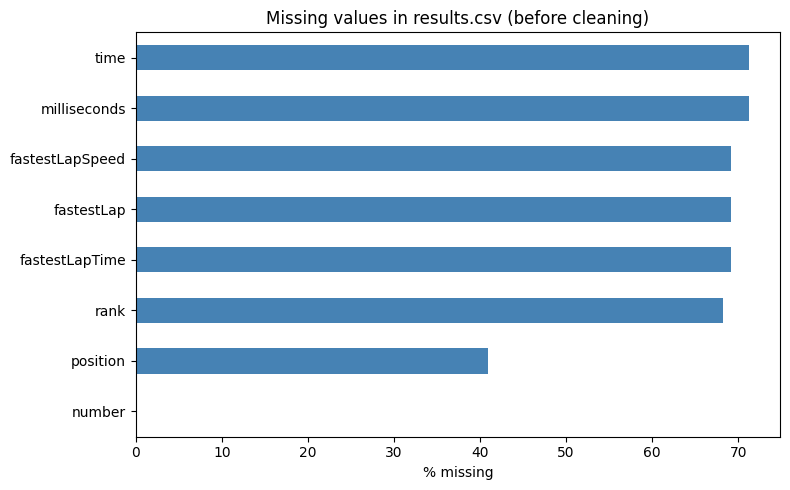

In [4]:
import matplotlib.pyplot as plt

missing_pct = missing[missing > 0] * 100
missing_pct.plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.xlabel("% missing")
plt.title("Missing values in results.csv (before cleaning)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

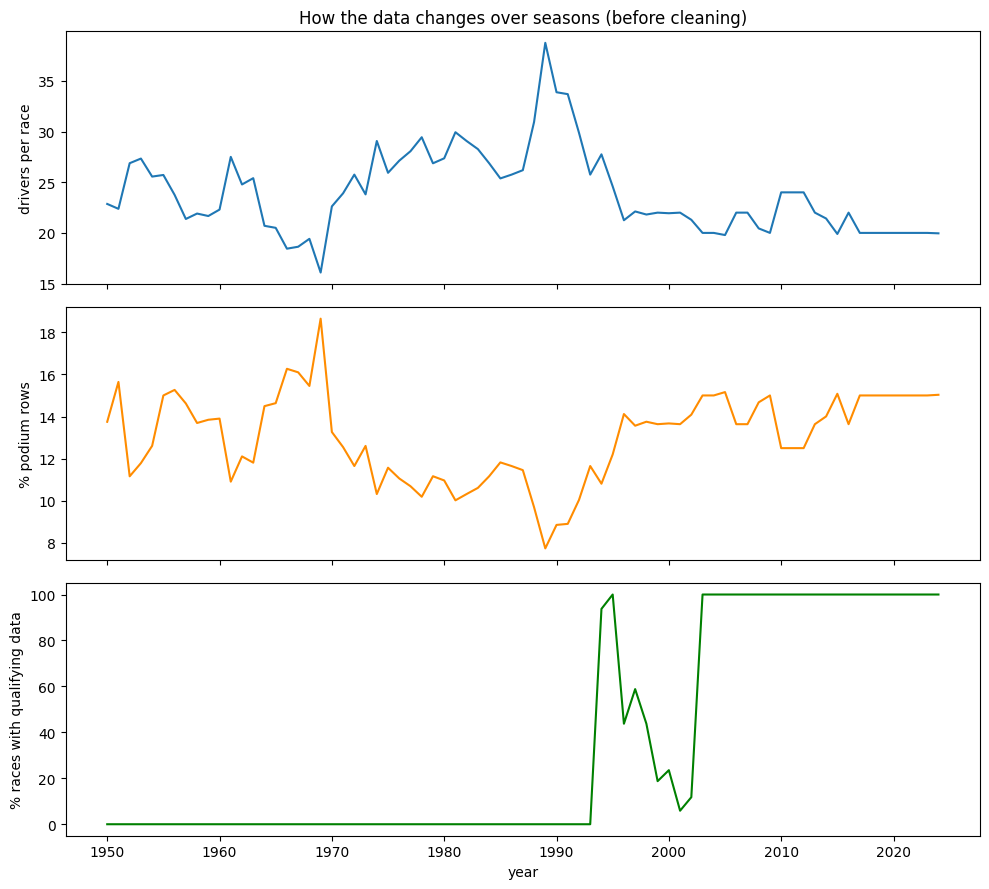

In [5]:
races = df["races"][["raceId", "year"]]
res = df["results"].merge(races, on="raceId")

# a) drivers per race, by season
drivers_per_race = res.groupby(["year", "raceId"]).size().groupby("year").mean()

# b) podium rate per row, by season (target = positionOrder <= 3)
podium_rate = (res["positionOrder"] <= 3).groupby(res["year"]).mean() * 100

# c) share of races that have qualifying data, by season
q = df["qualifying"].merge(races, on="raceId")
races_per_year = races.groupby("year").size()
coverage = (q.groupby("year")["raceId"].nunique() / races_per_year).reindex(races_per_year.index).fillna(0) * 100

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
drivers_per_race.plot(ax=axes[0]); axes[0].set_ylabel("drivers per race")
podium_rate.plot(ax=axes[1], color="darkorange"); axes[1].set_ylabel("% podium rows")
coverage.plot(ax=axes[2], color="green"); axes[2].set_ylabel("% races with qualifying data")
axes[0].set_title("How the data changes over seasons (before cleaning)")
plt.tight_layout()
plt.show()

# 3. Cleaning
## 3.1 Semantic typing
Dates become real dates, and lap-time strings (`1:27.452`) become seconds. `results.time` is deliberately *not* converted: only the winner has a race time, everyone else has a gap such as `+5.478`.

In [6]:
def to_seconds(s):
    """'1:27.452' -> 87.452 ; '27.452' -> 27.452 ; missing/garbage -> NaN"""
    if pd.isna(s):
        return np.nan
    try:
        parts = str(s).split(":")
        return sum(float(p) * 60**i for i, p in enumerate(reversed(parts)))
    except ValueError:
        return np.nan

# Dates -> real datetime objects
for col in df["races"].columns:
    if col == "date" or col.endswith("_date"):
        df["races"][col] = pd.to_datetime(df["races"][col], errors="coerce")
df["drivers"]["dob"] = pd.to_datetime(df["drivers"]["dob"], errors="coerce")

# Lap-time strings -> seconds
for col in ["q1", "q2", "q3"]:
    df["qualifying"][col + "_sec"] = df["qualifying"][col].apply(to_seconds)
df["results"]["fastestLapTime_sec"] = df["results"]["fastestLapTime"].apply(to_seconds)
df["lap_times"]["time_sec"] = df["lap_times"]["time"].apply(to_seconds)
df["pit_stops"]["duration_sec"] = df["pit_stops"]["duration"].apply(to_seconds)

# Numeric columns that may have been read as text
for col in ["rank", "fastestLapSpeed"]:
    df["results"][col] = pd.to_numeric(df["results"][col], errors="coerce")

# Check
print(df["races"]["date"].dtype, df["qualifying"]["q1_sec"].describe(), sep="\n")

datetime64[ns]
count    10338.000000
mean        88.531251
std         15.392958
min         53.904000
25%         78.773500
50%         87.141000
75%         95.909500
max       1002.640000
Name: q1_sec, dtype: float64


qualifying.q1_sec: n= 10338  min=   53.9  max=  1002.6  values > 200 s: 1
qualifying.q2_sec: n=  5847  min=   53.6  max=   132.5  values > 200 s: 0
qualifying.q3_sec: n=  3629  min=   53.4  max=   129.8  values > 200 s: 0
results.fastestLapTime_sec: n=  8252  min=   55.4  max=   202.3  values > 200 s: 1


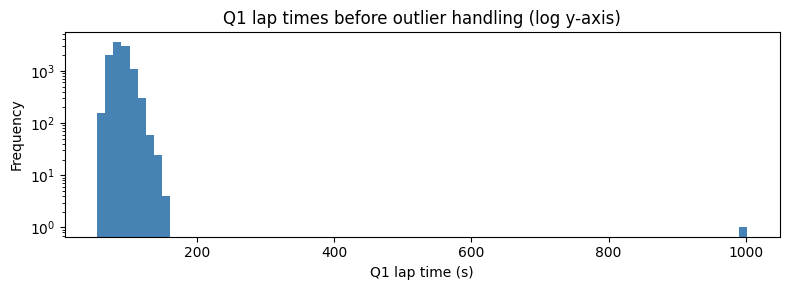

,year,name,driverId,q1,q2,q3
0,1995,Japanese Grand Prix,87,16:42.640,NaN,NaN


In [7]:
# Plausibility audit of lap times (a modern F1 lap takes roughly 55-150 s)
for name, col in [("qualifying","q1_sec"), ("qualifying","q2_sec"), ("qualifying","q3_sec"), ("results","fastestLapTime_sec")]:
    s = df[name][col].dropna()
    print(f"{name}.{col}: n={len(s):>6}  min={s.min():7.1f}  max={s.max():8.1f}  values > 200 s: {(s > 200).sum()}")

fig, ax = plt.subplots(figsize=(8, 3))
df["qualifying"]["q1_sec"].plot(kind="hist", bins=80, ax=ax, color="steelblue", logy=True)
ax.set_xlabel("Q1 lap time (s)")
ax.set_title("Q1 lap times before outlier handling (log y-axis)")
plt.tight_layout()
plt.show()

# Anything above 200 s is not a plausible qualifying lap -> treat as a data error (set to NaN, rows are kept)
LAP_MAX = 200
bad = df["qualifying"][df["qualifying"][["q1_sec", "q2_sec", "q3_sec"]].gt(LAP_MAX).any(axis=1)]
display(bad.merge(df["races"][["raceId", "year", "name"]], on="raceId")[["year", "name", "driverId", "q1", "q2", "q3"]])
for col in ["q1_sec", "q2_sec", "q3_sec"]:
    df["qualifying"].loc[df["qualifying"][col] > LAP_MAX, col] = np.nan

## 3.2 Text-label hygiene
Hidden whitespace and inconsistent labels silently break joins and lookups (e.g. the nationality `'Argentinian '` with a trailing space, and circuits labelled both `USA` and `United States`, which hid home races in Q2). We audit every text column, strip whitespace, and standardise `United States` to `USA`.

In [8]:
TEXT_TYPES = ["object", "string"]

ws_report = []
for t, tbl in df.items():
    for c in tbl.select_dtypes(include=TEXT_TYPES):
        s = tbl[c].dropna().astype(str)
        n = int((s != s.str.strip()).sum())
        if n:
            ws_report.append({"table": t, "column": c, "values_with_leading_or_trailing_spaces": n})
ws_report = pd.DataFrame(ws_report)
display(ws_report if len(ws_report) else "No leading/trailing whitespace found")

for t, tbl in df.items():
    for c in tbl.select_dtypes(include=TEXT_TYPES):
        tbl[c] = tbl[c].apply(lambda v: v.strip() if isinstance(v, str) else v)

print("Circuit countries before standardising:", sorted(df["circuits"]["country"].dropna().unique()))
df["circuits"]["country"] = df["circuits"]["country"].replace({"United States": "USA"})

,table,column,values_with_leading_or_trailing_spaces
0,drivers,nationality,1


Circuit countries before standardising: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


## 3.3 Grain: exactly one row per (raceId, driverId)
Each row is one prediction ("will this driver podium in this race?"), so (raceId, driverId) must be unique. Duplicates come mostly from shared drives in the 1950s, but the audit below shows a few later cases too (1958–1964, and one 1978 driver listed twice as a non-qualifier).

**Rule:** (1) if exactly one of the duplicate rows has a real grid slot (`grid > 0`), keep it; (2) otherwise keep the row with the best `positionOrder`; (3) then the lowest `resultId` (deterministic).

**What the diagnostic found:** in this dataset all 85 duplicate pairs fell to step 2. In every pair either both rows or neither row had a grid slot, so step 1 never decided anything, and in practice the rule is "keep the best finish". The brief allows this choice, but it has a limitation (next cell group).

In [9]:
# Keep an untouched snapshot for the before/after comparison
results_before = df["results"].copy()

key = ["raceId", "driverId"]
dup_mask = df["results"].duplicated(key, keep=False)   # keep=False marks ALL rows of a duplicate group
dups = df["results"][dup_mask].merge(df["races"][["raceId", "year", "name"]], on="raceId")

print("Rows involved in duplicates:", dup_mask.sum())
print("Distinct (race, driver) pairs affected:", dups.drop_duplicates(key).shape[0])
print("\nDuplicates by year:")
print(dups.drop_duplicates(key)["year"].value_counts().sort_index())

# Look at a few examples
cols = ["raceId", "year", "name", "driverId", "constructorId", "grid", "positionOrder", "points", "statusId"]
display(dups.sort_values(key)[cols].head(12))

Rows involved in duplicates: 176
Distinct (race, driver) pairs affected: 85

Duplicates by year:
year
1950     4
1951     4
1952     3
1953    14
1954    16
1955    15
1956    12
1957     8
1958     3
1960     1
1961     2
1962     1
1964     1
1978     1
Name: count, dtype: int64


,raceId,year,name,driverId,constructorId,grid,positionOrder,points,statusId
0,540,1978,Italian Grand Prix,229,54,0,26,0.0,81
1,540,1978,Italian Grand Prix,229,57,0,29,0.0,97
2,717,1964,United States Grand Prix,373,172,1,7,0.0,60
175,717,1964,United States Grand Prix,373,172,1,12,0.0,98
3,733,1962,British Grand Prix,465,172,0,22,0.0,54
4,733,1962,British Grand Prix,465,97,0,25,0.0,54
5,742,1961,British Grand Prix,475,102,20,19,0.0,2
6,742,1961,British Grand Prix,475,172,5,21,0.0,23
7,745,1961,United States Grand Prix,418,172,11,17,0.0,6
174,745,1961,United States Grand Prix,418,172,15,11,0.0,18


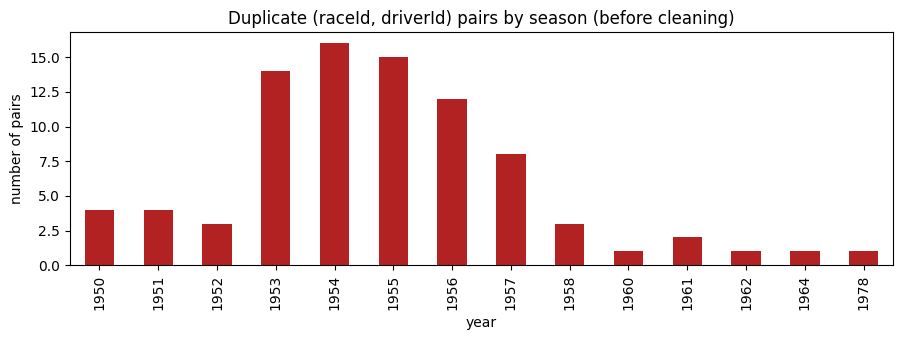

In [10]:
# Plot: when do duplicates happen?
dups.drop_duplicates(key)["year"].value_counts().sort_index().plot(kind="bar", figsize=(9, 3.5), color="firebrick")
plt.title("Duplicate (raceId, driverId) pairs by season (before cleaning)")
plt.ylabel("number of pairs")
plt.tight_layout()
plt.show()

In [11]:
r = df["results"].copy()
r["_has_grid"] = (r["grid"] > 0).astype(int)

# Sort so the row we want to keep comes first within each (raceId, driverId)
r = r.sort_values(
    ["raceId", "driverId", "_has_grid", "positionOrder", "resultId"],
    ascending=[True, True, False, True, True],
)

r_clean = r.drop_duplicates(key, keep="first").drop(columns="_has_grid")

# Log what we removed (for the report)
removed = r[~r.index.isin(r_clean.index)]
print(f"Rows before: {len(results_before)}  | after: {len(r_clean)}  | removed: {len(removed)}")

# The check that matters: grain is now unique
assert not r_clean.duplicated(key).any(), "Still duplicates!"
print("Grain check passed: (raceId, driverId) is unique.")

df["results"] = r_clean.sort_values("resultId").reset_index(drop=True)

Rows before: 26759  | after: 26668  | removed: 91
Grain check passed: (raceId, driverId) is unique.


In [12]:
# How was each duplicate pair decided? (evidence for the rule, and an honest look at its weak step)
d = results_before[results_before.duplicated(key, keep=False)].copy()
d["has_grid"] = (d["grid"] > 0).astype(int)
per_pair = d.groupby(key).agg(rows=("resultId", "size"), rows_with_grid=("has_grid", "sum"))
per_pair["decided_by"] = np.where(per_pair["rows_with_grid"] == 1,
                                  "step 1: exactly one row has a grid slot",
                                  "step 2: tie -> best positionOrder")
print("Pairs:", len(per_pair), "| rows per pair:", per_pair["rows"].value_counts().to_dict())
print(per_pair["decided_by"].value_counts())

Pairs: 85 | rows per pair: {2: 79, 3: 6}
decided_by
step 2: tie -> best positionOrder    85
Name: count, dtype: int64


In [13]:
# Sensitivity: what if we had kept the car the driver STARTED in (lowest non-zero grid) instead of the best finish?
alt = results_before.copy()
alt["_g"] = alt["grid"].where(alt["grid"] > 0, 999)          # grid 0 counts as 'no slot' (worst)
alt = alt.sort_values(key + ["_g", "resultId"]).drop_duplicates(key, keep="first")

cmp = (df["results"][key + ["resultId", "positionOrder"]]
       .merge(alt[key + ["resultId", "positionOrder"]], on=key, suffixes=("_kept", "_alt"))
       .merge(df["races"][["raceId", "year"]], on="raceId"))
diff_row = cmp[cmp["resultId_kept"] != cmp["resultId_alt"]]
diff_label = cmp[(cmp["positionOrder_kept"] <= 3) != (cmp["positionOrder_alt"] <= 3)]
print(f"Pairs where the alternative rule keeps a different row: {len(diff_row)} of {len(per_pair)}")
print(f"Of those, rows whose podium label would differ: {len(diff_label)} | seasons: {sorted(diff_label['year'].unique())}")

Pairs where the alternative rule keeps a different row: 56 of 85
Of those, rows whose podium label would differ: 17 | seasons: [np.int64(1950), np.int64(1951), np.int64(1953), np.int64(1954), np.int64(1956), np.int64(1957), np.int64(1960)]


**Limitation of the rule:** because step 2 uses `positionOrder` (post-race information) to choose the row, the kept row can come from a car the driver took over mid-race. Example: raceId 746 (1960 Argentine GP), driver 475 has a grid-1 row that finished 17th and a grid-8 row that finished 3rd; we keep the 3rd-place row, so its `grid` belongs to a different car than the one he started in. This concerns the 91 removed rows (0.34% of 26,759), all in 1950–1978: Q1 and Q3 only use 2006+ and 2014+ data, so they are unaffected, and Q2 is affected at most marginally. The cell above tests the alternative rule 'keep the car he started in (lowest non-zero grid)' and counts how many podium labels would change.

## 3.4 Primary and foreign keys
Primary keys must be unique and non-null; foreign keys must exist in their parent table (no orphans).

In [14]:
pks = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "sprint_results": ["resultId"], "qualifying": ["qualifyId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "driver_standings": ["driverStandingsId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
}

pk_report = []
for t, cols in pks.items():
    tbl = df[t]
    pk_report.append({
        "table": t, "pk": "+".join(cols), "rows": len(tbl),
        "null_in_pk": int(tbl[cols].isna().any(axis=1).sum()),
        "duplicate_pk": int(tbl.duplicated(cols).sum()),
    })
pk_report = pd.DataFrame(pk_report)
display(pk_report)

,table,pk,rows,null_in_pk,duplicate_pk
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,drivers,driverId,861,0,0
3,races,raceId,1125,0,0
4,seasons,year,75,0,0
5,status,statusId,139,0,0
6,results,resultId,26668,0,0
7,sprint_results,resultId,360,0,0
8,qualifying,qualifyId,10494,0,0
9,constructor_results,constructorResultsId,12625,0,0


In [15]:
# (child table, fk column, parent table, parent key)
fks = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
]

fk_report = []
for child, col, parent, pcol in fks:
    vals = df[child][col].dropna()
    orphans = ~vals.isin(df[parent][pcol])
    fk_report.append({
        "child": child, "fk": col, "parent": parent,
        "null_fk": int(df[child][col].isna().sum()),
        "orphans": int(orphans.sum()),
    })
fk_report = pd.DataFrame(fk_report)
display(fk_report)

,child,fk,parent,null_fk,orphans
0,races,circuitId,circuits,0,0
1,races,year,seasons,0,0
2,results,raceId,races,0,0
3,results,driverId,drivers,0,0
4,results,constructorId,constructors,0,0
5,results,statusId,status,0,0
6,sprint_results,raceId,races,0,0
7,sprint_results,driverId,drivers,0,0
8,sprint_results,constructorId,constructors,0,0
9,sprint_results,statusId,status,0,0


In [16]:
print("qualifying duplicate (raceId, driverId):", df["qualifying"].duplicated(key).sum())

qualifying duplicate (raceId, driverId): 0


# 4. EDA after cleaning (impact of the cleaning)
Four checks: (1) the `\N` placeholders became real missing values; (2) column data types became numeric where they should; (3) the duplicate fix only touched old seasons; (4) the podium rate per season is essentially unchanged, i.e. the grain fix did not distort the target. Races in the 1950s whose podium count is not exactly 3 are expected, because shared-drive rows were dropped.

,table,\N strings (before),NaN after reading with na_values,match
0,circuits,0,0,True
1,constructor_results,12608,12608,True
2,constructor_standings,0,0,True
3,constructors,0,0,True
4,driver_standings,0,0,True
5,drivers,1559,1559,True
6,lap_times,0,0,True
7,pit_stops,0,0,True
8,qualifying,11600,11668,False
9,races,11349,11349,True


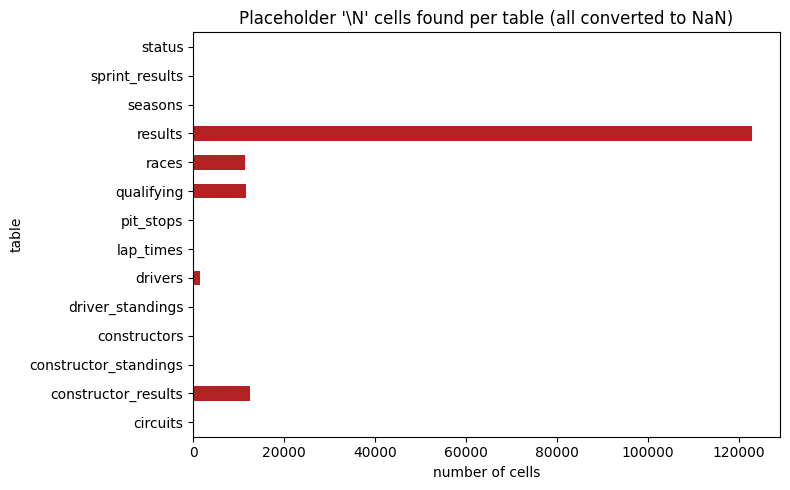

In [17]:
rows = []
for path in sorted(glob.glob(f"{RAW}/*.csv")):
    name = os.path.basename(path)[:-4]
    naive = pd.read_csv(path, dtype=str, keep_default_na=False)   # no cleaning at all
    n_before = int((naive == "\\N").sum().sum())
    n_after = int(raw[name].isna().sum().sum())                   # same data, read with na_values
    rows.append({"table": name, "\\N strings (before)": n_before,
                 "NaN after reading with na_values": n_after, "match": n_before == n_after})
sentinel_report = pd.DataFrame(rows)
display(sentinel_report)

sentinel_report.set_index("table")["\\N strings (before)"].plot(
    kind="barh", figsize=(8, 5), color="firebrick")
plt.title("Placeholder '\\N' cells found per table (all converted to NaN)")
plt.xlabel("number of cells")
plt.tight_layout()
plt.show()

In [18]:
# The match column above is False for qualifying: find the cells pandas read as NaN although they are not '\\N'
naive_q = pd.read_csv(f"{RAW}/qualifying.csv", dtype=str, keep_default_na=False)
extra = raw["qualifying"].isna() & (naive_q != "\\N")
print("Extra NaN cells per column:", extra.sum()[extra.sum() > 0].to_dict())
for col in extra.columns[extra.any()]:
    print(col, "-> literal values in the file:", naive_q.loc[extra[col], col].value_counts().to_dict())

Extra NaN cells per column: {'q2': 22, 'q3': 46}
q2 -> literal values in the file: {'': 22}
q3 -> literal values in the file: {'': 46}


In [19]:
naive_res = pd.read_csv(f"{RAW}/results.csv")   # no \\N handling
dtype_cmp = pd.DataFrame({
    "before (raw read)": naive_res.dtypes.astype(str),
    "after (cleaned)": df["results"][naive_res.columns].dtypes.astype(str),
})
dtype_cmp["changed"] = dtype_cmp["before (raw read)"] != dtype_cmp["after (cleaned)"]
display(dtype_cmp)

,before (raw read),after (cleaned),changed
resultId,int64,int64,False
raceId,int64,int64,False
driverId,int64,int64,False
constructorId,int64,int64,False
number,object,float64,True
grid,int64,int64,False
position,object,float64,True
positionText,object,object,False
positionOrder,int64,int64,False
points,float64,float64,False


,rows_before,rows_after,removed
year,,,
1950,160,156,4
1951,179,175,4
1952,215,212,3
1953,246,230,16
1954,230,213,17
1955,180,162,18
1956,190,178,12
1957,171,163,8
1958,241,238,3


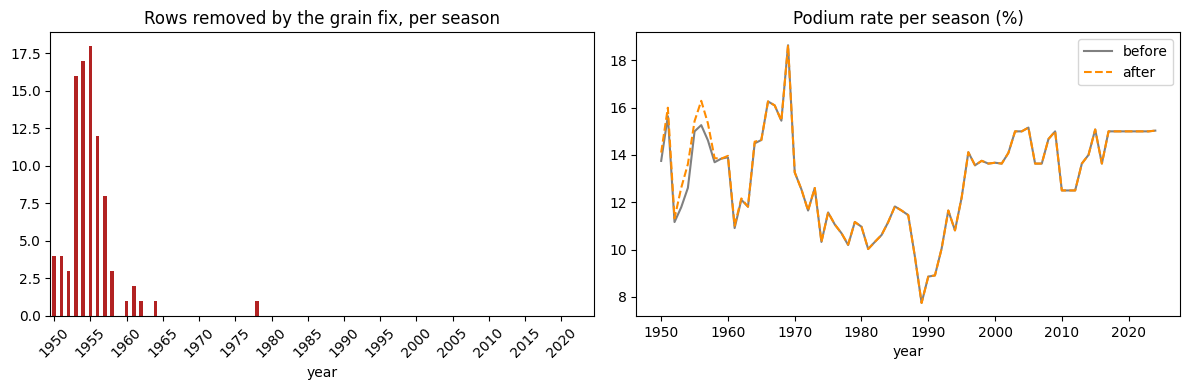

In [20]:
races = df["races"][["raceId", "year"]]
before = results_before.merge(races, on="raceId")
after = df["results"].merge(races, on="raceId")

compare = pd.DataFrame({
    "rows_before": before.groupby("year").size(),
    "rows_after": after.groupby("year").size(),
}).fillna(0)
compare["removed"] = compare["rows_before"] - compare["rows_after"]
display(compare[compare["removed"] > 0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
compare["removed"].plot(kind="bar", ax=axes[0], color="firebrick")
axes[0].set_title("Rows removed by the grain fix, per season")
axes[0].set_xticks(range(0, len(compare), 5))
axes[0].set_xticklabels(compare.index[::5], rotation=45)

pod_b = (before["positionOrder"] <= 3).groupby(before["year"]).mean() * 100
pod_a = (after["positionOrder"] <= 3).groupby(after["year"]).mean() * 100
pod_b.plot(ax=axes[1], label="before", color="gray")
pod_a.plot(ax=axes[1], label="after", color="darkorange", linestyle="--")
axes[1].set_title("Podium rate per season (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [21]:
base = df["results"].merge(
    df["races"][["raceId", "year", "round", "circuitId", "name", "date"]],
    on="raceId", how="left", validate="many_to_one",
)
base["podium"] = (base["positionOrder"] <= 3).astype(int)

# Sanity checks
assert len(base) == len(df["results"])              # the join didn't add or lose rows
assert not base.duplicated(["raceId", "driverId"]).any()
assert base["positionOrder"].notna().all()          # target is defined for every row
print("Rows:", len(base), "| overall podium rate:", round(base["podium"].mean() * 100, 1), "%")

# A race should have exactly 3 podium rows. Where is that not true?
podium_per_race = base.groupby("raceId")["podium"].sum()
odd = podium_per_race[podium_per_race != 3]
print("Races where podium rows != 3:", len(odd))
display(base[base["raceId"].isin(odd.index)].groupby("year").raceId.nunique().rename("races"))

Rows: 26668 | overall podium rate: 12.7 %
Races where podium rows != 3: 18


year
1950    1
1951    3
1953    2
1954    2
1955    3
1956    5
1957    1
1960    1
Name: races, dtype: int64

In [22]:
cleaning_log = pd.DataFrame([
    ["Sentinel \\N", "Read all CSVs with na_values=['\\\\N']", "Text columns became numeric; placeholders became real NaN"],
    ["Dates", "pd.to_datetime on races and drivers dates", "Enables sorting by time and leakage-safe 'past races' logic"],
    ["Lap times", "'m:ss.xxx' converted to seconds (_sec columns)", "Times become numeric and comparable"],
    ["Implausible lap times", "Qualifying laps > 200 s set to NaN (rows kept); one value found: 1995 Japanese GP, Q1 = '16:42.640'", "A 1000 s 'lap' is a data error; found by the plausibility audit"],
    ["Text labels", "Stripped whitespace in all text columns; 'United States' -> 'USA' in circuits.country", "'Argentinian ' and USA/United States mismatches hid home races in Q2"],
    ["Duplicate grain", "Kept row with grid>0, then best positionOrder, then lowest resultId", "One row per (raceId, driverId); matches the pre-race cutoff; all 85 pairs were decided by the best-positionOrder tie-break, which uses post-race information (see 3.3)"],
    ["Keys", "PK unique and non-null, FK orphan checks on all tables", "Joins are safe"],
    ["grid = 0", "Kept in the modeling table; Q1 uses grid in {1,2} only; Q2 keeps it as its own 'no slot' category", "Pit-lane starters and unrecorded slots can still podium, so they are not discarded"],
    ["Raw data", "All work done on copies (df); raw dict untouched", "Required by the brief"],
], columns=["issue", "what we did", "why / effect"])
pd.set_option("display.max_colwidth", None)
display(cleaning_log)

,issue,what we did,why / effect
0,Sentinel \N,Read all CSVs with na_values=['\\N'],Text columns became numeric; placeholders became real NaN
1,Dates,pd.to_datetime on races and drivers dates,Enables sorting by time and leakage-safe 'past races' logic
2,Lap times,'m:ss.xxx' converted to seconds (_sec columns),Times become numeric and comparable
3,Implausible lap times,"Qualifying laps > 200 s set to NaN (rows kept); one value found: 1995 Japanese GP, Q1 = '16:42.640'",A 1000 s 'lap' is a data error; found by the plausibility audit
4,Text labels,Stripped whitespace in all text columns; 'United States' -> 'USA' in circuits.country,'Argentinian ' and USA/United States mismatches hid home races in Q2
5,Duplicate grain,"Kept row with grid>0, then best positionOrder, then lowest resultId","One row per (raceId, driverId); matches the pre-race cutoff; all 85 pairs were decided by the best-positionOrder tie-break, which uses post-race information (see 3.3)"
6,Keys,"PK unique and non-null, FK orphan checks on all tables",Joins are safe
7,grid = 0,"Kept in the modeling table; Q1 uses grid in {1,2} only; Q2 keeps it as its own 'no slot' category","Pit-lane starters and unrecorded slots can still podium, so they are not discarded"
8,Raw data,All work done on copies (df); raw dict untouched,Required by the brief



# 5. ***Q1:Which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014 hybrid era? Distinguish qualifying position from grid(which can differ due to penalties).***


In [23]:
START_YEAR, SPLIT_YEAR = 2006, 2014
ERA1, ERA2 = "2006–2013", "2014–2024"

qual = (df["qualifying"][["raceId", "driverId", "position"]]
        .rename(columns={"position": "qual_pos"}))

q1 = (df["results"][["raceId", "driverId", "constructorId", "grid", "positionOrder"]]
      .merge(df["races"][["raceId", "year", "circuitId"]], on="raceId")
      .merge(df["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"}),
             on="circuitId")
      .merge(qual, on=["raceId", "driverId"], how="left", validate="one_to_one"))

q1 = q1[q1["year"] >= START_YEAR].copy()
q1["podium"] = (q1["positionOrder"] <= 3).astype(int)
q1["era"] = np.where(q1["year"] < SPLIT_YEAR, ERA1, ERA2)

# Missingness: how many rows have no qualifying position?
miss = q1["qual_pos"].isna().groupby(q1["year"]).mean() * 100
print("Rows:", len(q1), "| missing qual_pos:", int(q1["qual_pos"].isna().sum()))
print(miss[miss > 0].round(1))

# Use the SAME rows for both definitions, so they are comparable
q1 = q1[q1["qual_pos"].notna()].copy()

q1["front_qual"] = q1["qual_pos"] <= 2
q1["front_grid"] = q1["grid"].isin([1, 2])      # NOT grid <= 2 (grid 0 = pit lane)

# How often do the two definitions disagree?
display(pd.crosstab(q1["front_qual"], q1["front_grid"],
                    rownames=["front row by QUALIFYING"], colnames=["front row by GRID"]))

Rows: 7914 | missing qual_pos: 24
year
2011    0.9
2012    0.8
2014    0.5
2015    1.1
2016    1.1
2017    0.5
2019    0.5
2021    0.2
Name: qual_pos, dtype: float64


front row by GRID,False,True
front row by QUALIFYING,,
False,7107,33
True,35,715


In [24]:
MIN_FR = 12   # minimum front-row starts per circuit per era

def conversion(frame, flag):
    fr = frame[frame[flag]]
    t = (fr.groupby(["era", "circuit"])
           .agg(front_row_starts=("podium", "size"), podiums=("podium", "sum"))
           .reset_index())
    t["rate_%"] = (t["podiums"] / t["front_row_starts"] * 100).round(1)
    return t[t["front_row_starts"] >= MIN_FR]

res_qual = conversion(q1, "front_qual")
res_grid = conversion(q1, "front_grid")

# Overall rate per era (context for the circuit numbers)
for name, flag in [("qualifying", "front_qual"), ("grid", "front_grid")]:
    print(name, q1[q1[flag]].groupby("era")["podium"].mean().mul(100).round(1).to_dict())

# Top circuits per era
for name, t in [("QUALIFYING-based", res_qual), ("GRID-based", res_grid)]:
    for era in [ERA1, ERA2]:
        print(f"\n=== {name}, {era} (min {MIN_FR} front-row starts) ===")
        display(t[t["era"] == era].sort_values("rate_%", ascending=False)
                .drop(columns="era").head(10).reset_index(drop=True))

qualifying {'2006–2013': 69.0, '2014–2024': 73.7}
grid {'2006–2013': 69.7, '2014–2024': 76.0}

=== QUALIFYING-based, 2006–2013 (min 12 front-row starts) ===


,circuit,front_row_starts,podiums,rate_%
0,Istanbul Park,12,10,83.3
1,Suzuka Circuit,12,10,83.3
2,Circuit de Spa-Francorchamps,14,11,78.6
3,Silverstone Circuit,16,12,75.0
4,Autodromo Nazionale di Monza,16,12,75.0
5,Circuit de Monaco,16,12,75.0
6,Shanghai International Circuit,16,11,68.8
7,Bahrain International Circuit,14,9,64.3
8,Sepang International Circuit,16,10,62.5
9,Albert Park Grand Prix Circuit,16,10,62.5



=== QUALIFYING-based, 2014–2024 (min 12 front-row starts) ===


,circuit,front_row_starts,podiums,rate_%
0,Suzuka Circuit,18,16,88.9
1,Circuit de Monaco,20,17,85.0
2,Circuit de Spa-Francorchamps,22,18,81.8
3,Yas Marina Circuit,22,18,81.8
4,Circuit de Barcelona-Catalunya,22,18,81.8
5,Sochi Autodrom,16,13,81.2
6,Shanghai International Circuit,14,11,78.6
7,Silverstone Circuit,24,18,75.0
8,Circuit of the Americas,20,15,75.0
9,Autodromo Nazionale di Monza,22,16,72.7



=== GRID-based, 2006–2013 (min 12 front-row starts) ===


,circuit,front_row_starts,podiums,rate_%
0,Istanbul Park,12,10,83.3
1,Suzuka Circuit,12,10,83.3
2,Circuit de Monaco,16,13,81.2
3,Circuit de Spa-Francorchamps,14,11,78.6
4,Silverstone Circuit,16,12,75.0
5,Autodromo Nazionale di Monza,16,12,75.0
6,Circuit de Barcelona-Catalunya,16,11,68.8
7,Bahrain International Circuit,14,9,64.3
8,Shanghai International Circuit,16,10,62.5
9,Albert Park Grand Prix Circuit,16,10,62.5



=== GRID-based, 2014–2024 (min 12 front-row starts) ===


,circuit,front_row_starts,podiums,rate_%
0,Suzuka Circuit,18,16,88.9
1,Yas Marina Circuit,22,19,86.4
2,Circuit de Monaco,20,17,85.0
3,Circuit de Spa-Francorchamps,22,18,81.8
4,Circuit de Barcelona-Catalunya,22,18,81.8
5,Sochi Autodrom,16,13,81.2
6,Circuit of the Americas,20,16,80.0
7,Autódromo José Carlos Pace,19,15,78.9
8,Shanghai International Circuit,14,11,78.6
9,Circuit Gilles Villeneuve,18,14,77.8


qualifying-based: 13 circuits in both eras, Spearman rank correlation = 0.81
grid-based: 13 circuits in both eras, Spearman rank correlation = 0.50


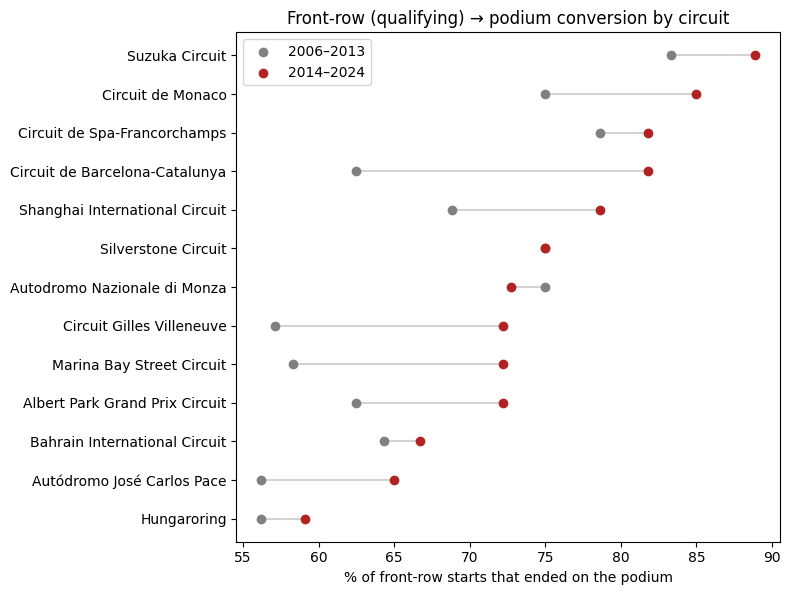

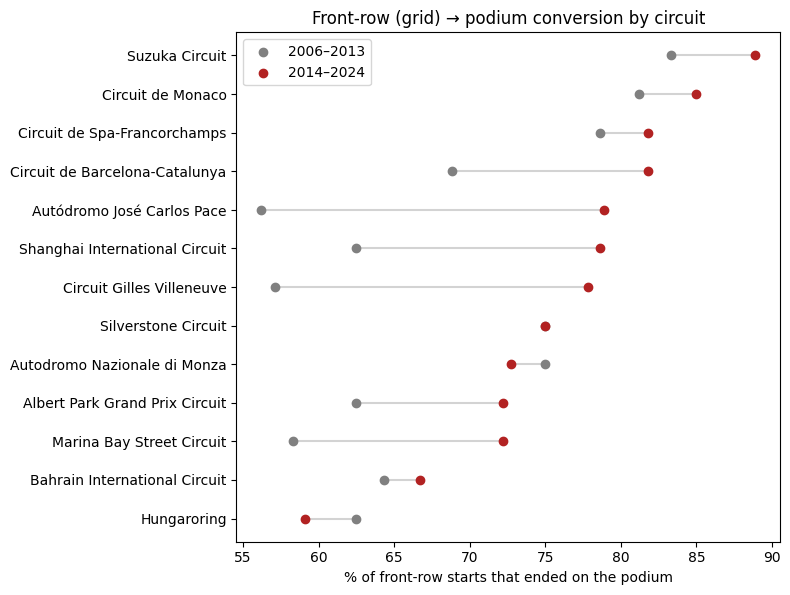

In [25]:
def to_wide(t):
    return t.pivot(index="circuit", columns="era",
                   values=["rate_%", "front_row_starts"]).dropna()

for name, t in [("qualifying", res_qual), ("grid", res_grid)]:
    w = to_wide(t)
    rho = w[("rate_%", ERA1)].corr(w[("rate_%", ERA2)], method="spearman")
    print(f"{name}-based: {len(w)} circuits in both eras, Spearman rank correlation = {rho:.2f}")

def dumbbell(t, title):
    w = to_wide(t)
    pre, post = w[("rate_%", ERA1)], w[("rate_%", ERA2)]
    order = post.sort_values().index
    y = range(len(order))
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(order) + 1.5))
    for i, c in enumerate(order):
        ax.plot([pre[c], post[c]], [i, i], color="lightgray", zorder=1)
    ax.scatter(pre[order], y, color="gray", label=ERA1, zorder=2)
    ax.scatter(post[order], y, color="firebrick", label=ERA2, zorder=2)
    ax.set_yticks(list(y))
    ax.set_yticklabels(order)
    ax.set_xlabel("% of front-row starts that ended on the podium")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

dumbbell(res_qual, "Front-row (qualifying) → podium conversion by circuit")
dumbbell(res_grid, "Front-row (grid) → podium conversion by circuit")

In [26]:
w = to_wide(res_qual)
print(w["front_row_starts"].describe().round(1))

era    2006–2013  2014–2024
count       13.0       13.0
mean        14.9       20.2
std          1.6        2.9
min         12.0       14.0
25%         14.0       18.0
50%         16.0       20.0
75%         16.0       22.0
max         16.0       24.0


In [27]:
# How uncertain are the rank correlations? Bootstrap over the 13 circuits
# (rough: it ignores the noise inside each circuit's own rate)
rng = np.random.default_rng(42)

def rho_ci(t, n=2000):
    w_ = to_wide(t)
    a, b = w_[("rate_%", ERA1)].values, w_[("rate_%", ERA2)].values
    rhos = []
    for _ in range(n):
        idx = rng.integers(0, len(a), len(a))
        if np.unique(a[idx]).size < 2 or np.unique(b[idx]).size < 2:
            continue
        rhos.append(pd.Series(a[idx]).corr(pd.Series(b[idx]), method="spearman"))
    return np.percentile(rhos, [2.5, 97.5]).round(2)

print("Spearman 95% bootstrap interval, qualifying-based:", rho_ci(res_qual))
print("Spearman 95% bootstrap interval, grid-based:      ", rho_ci(res_grid))

# Where do the qualifying-vs-grid disagreements come from?
dis = q1[q1["front_qual"] != q1["front_grid"]]
print("\nDisagreements by season:")
print(dis.groupby("year").size().to_string())

Spearman 95% bootstrap interval, qualifying-based: [0.4  0.96]
Spearman 95% bootstrap interval, grid-based:       [-0.16  0.9 ]

Disagreements by season:
year
2007     2
2010     2
2011     2
2012     6
2016     6
2017     5
2018     2
2019     6
2020     2
2021    12
2022    10
2023     9
2024     4


**Q1 answer.** Restricting to 2006–2024 (consistent three-part qualifying; the 24 rows, 0.3%, with no qualifying position are dropped from both definitions) and requiring at least 12 front-row starts per circuit per era: by qualifying position, Suzuka and Istanbul Park tie for first in 2006–2013 (83.3%, 10 podiums from 12 front-row starts), then Spa (78.6%) and Silverstone, Monza and Monaco (75%). In 2014–2024 Suzuka is first (88.9%, 16 of 18), followed by Monaco (85%) and Spa, Yas Marina and Barcelona (81.8%). Istanbul Park has no 2014–2024 entry above the threshold, so among the 13 circuits present in both eras Suzuka leads both times, Monaco rises from 75% to 85%, and Hungaroring is at or near the bottom in both (see dumbbell plots). Overall front-row conversion rose from 69% to 74% (qualifying-based) and from 70% to 76% (grid-based), so most circuits move up together. The qualifying-based ranking is fairly stable (Spearman 0.81 over 13 circuits) and the grid-based one is more reshuffled (0.50); but with only 13 circuits and 12–24 front-row starts each (one podium = 4–8 points), these correlations are imprecise: the 95% bootstrap intervals are 0.40–0.96 (qualifying-based) and −0.16–0.90 (grid-based), which overlap widely, so the apparent difference in stability between the two definitions is not statistically reliable, and neighbouring circuits cannot be separated.

**Qualifying vs grid:** the definitions disagree for 68 of 7,890 rows (0.9%), (penalties and pit-lane starts are the expected causes; we did not break them down). They are most frequent in 2021–2023 (31 of the 68); we did not test why. **Grain:** one row per driver per race, aggregated by circuit and era. **Missingness:** as above. **Cutoff:** qualifying and grid position are both known before the race, so both are valid pre-race information; only the podium outcome is post-race. **Limitations:** small samples; only circuits in both eras can be compared (circuits such as Istanbul Park or Yas Marina have too few front-row starts in one era and drop out); a circuit's rate also reflects which team was dominant there, so it is not a pure property of the track.


# ***Q2:Do drivers podium more often when racing at a circuit in their home country thanelsewhere, after controlling for starting position (i.e., comparing drivers whostarted from similar grid positions, so the effect isn’t just because home drivershappen to qualify better)?***


In [28]:
# Clean text labels (document this in your cleaning_log)
df["drivers"]["nationality"] = df["drivers"]["nationality"].str.strip()
df["circuits"]["country"] = (df["circuits"]["country"].str.strip()
                             .replace({"United States": "USA"}))

NAT_TO_COUNTRY = {
    "British": ["UK"], "American": ["USA"], "American-Italian": ["USA", "Italy"],
    "Argentine": ["Argentina"], "Argentinian": ["Argentina"],
    "Argentine-Italian": ["Argentina", "Italy"],
    "Australian": ["Australia"], "Austrian": ["Austria"], "Belgian": ["Belgium"],
    "Brazilian": ["Brazil"], "Canadian": ["Canada"], "Chinese": ["China"],
    "Dutch": ["Netherlands"], "East German": ["Germany"], "French": ["France"],
    "German": ["Germany"], "Hungarian": ["Hungary"], "Indian": ["India"],
    "Italian": ["Italy"], "Japanese": ["Japan"], "Malaysian": ["Malaysia"],
    "Mexican": ["Mexico"], "Monegasque": ["Monaco"], "Portuguese": ["Portugal"],
    "Russian": ["Russia"], "South African": ["South Africa"], "Spanish": ["Spain"],
    "Swedish": ["Sweden"], "Swiss": ["Switzerland"],
}

nats = set(df["drivers"]["nationality"].dropna().unique())
countries = set(df["circuits"]["country"].dropna().unique())
targets = {c for v in NAT_TO_COUNTRY.values() for c in v}

print("Nationalities not in map (should all be 'no home GP'):")
print(sorted(nats - set(NAT_TO_COUNTRY)))
print("\nMapped countries missing from circuits (should be empty):")
print(sorted(targets - countries))
print("\nCircuit countries nobody maps to:")
print(sorted(countries - targets))

Nationalities not in map (should all be 'no home GP'):
['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']

Mapped countries missing from circuits (should be empty):
[]

Circuit countries nobody maps to:
['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']


In [29]:
q2 = (df["results"][["raceId", "driverId", "constructorId", "grid", "positionOrder"]]
      .merge(df["races"][["raceId", "year", "circuitId"]], on="raceId")
      .merge(df["circuits"][["circuitId", "name", "country"]]
             .rename(columns={"name": "circuit", "country": "circuit_country"}), on="circuitId")
      .merge(df["drivers"][["driverId", "nationality"]], on="driverId", validate="many_to_one"))
n0 = len(q2)

# Exclude the Indy 500 years (1950-1960 only; Indianapolis hosted the US GP 2000-2007)
indy = q2["circuit"].str.contains("Indianapolis", na=False) & (q2["year"] <= 1960)
q2 = q2[~indy]
n1 = len(q2)

home_lists = q2["nationality"].map(NAT_TO_COUNTRY)
q2["is_home"] = [int(isinstance(h, list) and c in h)
                 for h, c in zip(home_lists, q2["circuit_country"])]

# Keep rows with a real grid slot (grid=0 means pit-lane start / no start)
q2 = q2[q2["grid"] >= 1].copy()
q2["podium"] = (q2["positionOrder"] <= 3).astype(int)

q2["grid_bin"] = pd.cut(q2["grid"], [0, 1, 2, 3, 5, 8, 12, 100],
                        labels=["1", "2", "3", "4-5", "6-8", "9-12", "13+"])
q2["era"] = pd.cut(q2["year"], [1949, 1969, 1989, 2005, 2013, 2024],
                   labels=["1950-69", "1970-89", "1990-2005", "2006-13", "2014-24"])

print(f"Rows: {n0} -> {n1} after Indy 500 -> {len(q2)} after dropping grid=0 ({n1 - len(q2)} dropped)")
print(f"Home rows: {int(q2['is_home'].sum())} ({q2['is_home'].mean() * 100:.1f}%)  | before the fix: 1943")
print(q2.groupby("era", observed=True)["is_home"].agg(["sum", "mean"]).round(3))

print("\nRaw podium rate (%):", q2.groupby("is_home")["podium"].mean().mul(100).round(1).to_dict())
print("Mean grid slot:     ", q2.groupby("is_home")["grid"].mean().round(2).to_dict())

Rows: 26668 -> 26287 after Indy 500 -> 24652 after dropping grid=0 (1635 dropped)
Home rows: 1944 (7.9%)  | before the fix: 1943
           sum   mean
era                  
1950-69    620  0.183
1970-89    603  0.082
1990-2005  424  0.070
2006-13    153  0.047
2014-24    144  0.032

Raw podium rate (%): {0: 13.8, 1: 11.8}
Mean grid slot:      {0: 11.71, 1: 12.73}


,n_away,n_home,rate_away,rate_home,diff_pp
grid_bin,,,,,
1,1032,81,0.647,0.605,-4.235
2,1032,75,0.562,0.560,-0.202
3,1042,73,0.458,0.548,9.017
4-5,2082,144,0.295,0.347,5.183
6-8,3100,237,0.140,0.118,-2.218
9-12,4115,347,0.054,0.052,-0.232
13+,10305,987,0.013,0.003,-0.967


Grid-adjusted home advantage (percentage points): -0.3


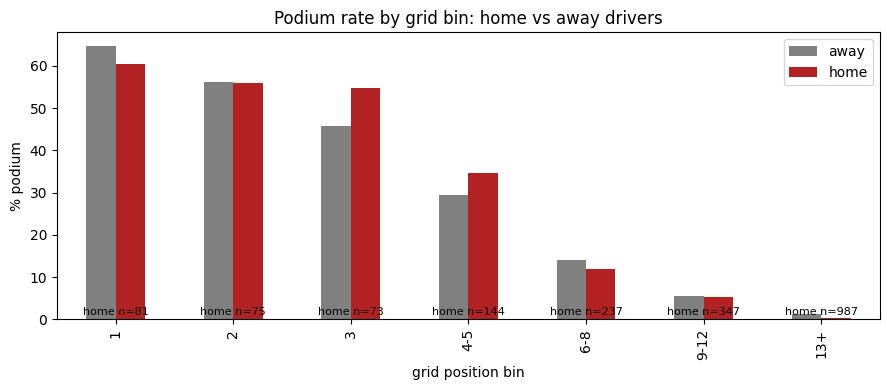

In [30]:
g = (q2.groupby(["grid_bin", "is_home"], observed=True)["podium"]
       .agg(n="size", rate="mean").unstack("is_home"))
g.columns = [f"{a}_{'home' if b else 'away'}" for a, b in g.columns]
g["diff_pp"] = (g["rate_home"] - g["rate_away"]) * 100
display(g.round(3))

w = g["n_home"] / g["n_home"].sum()
print("Grid-adjusted home advantage (percentage points):", round((g["diff_pp"] * w).sum(), 1))

ax = (g[["rate_away", "rate_home"]] * 100).plot(kind="bar", figsize=(9, 4),
                                                  color=["gray", "firebrick"])
ax.set_ylabel("% podium")
ax.set_xlabel("grid position bin")
ax.set_title("Podium rate by grid bin: home vs away drivers")
ax.legend(["away", "home"])
for i, nh in enumerate(g["n_home"]):
    ax.annotate(f"home n={int(nh)}", (i, 1), ha="center", fontsize=8)
plt.tight_layout()
plt.show()

,model,odds_ratio,ci_low,ci_high,p_value
0,1. no control,0.840,0.706,0.998,0.048
1,2. + grid bins,0.966,0.799,1.168,0.724
2,3. + grid bins + era,0.956,0.782,1.169,0.661


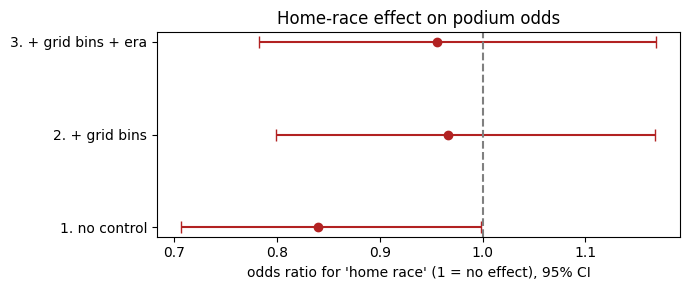

In [31]:
import statsmodels.formula.api as smf

def fit(formula):
    return smf.logit(formula, data=q2).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": q2["driverId"]})

models = {
    "1. no control":        fit("podium ~ is_home"),
    "2. + grid bins":       fit("podium ~ is_home + C(grid_bin)"),
    "3. + grid bins + era": fit("podium ~ is_home + C(grid_bin) + C(era)"),
}

rows = []
for name, m in models.items():
    ci = m.conf_int().loc["is_home"]
    rows.append({"model": name, "odds_ratio": np.exp(m.params["is_home"]),
                 "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                 "p_value": m.pvalues["is_home"]})
or_tbl = pd.DataFrame(rows).round(3)
display(or_tbl)

fig, ax = plt.subplots(figsize=(7, 3))
y = range(len(or_tbl))
ax.errorbar(or_tbl["odds_ratio"], y,
            xerr=[or_tbl["odds_ratio"] - or_tbl["ci_low"], or_tbl["ci_high"] - or_tbl["odds_ratio"]],
            fmt="o", color="firebrick", capsize=4)
ax.axvline(1, color="gray", linestyle="--")
ax.set_yticks(list(y)); ax.set_yticklabels(or_tbl["model"])
ax.set_xlabel("odds ratio for 'home race' (1 = no effect), 95% CI")
ax.set_title("Home-race effect on podium odds")
plt.tight_layout()
plt.show()


**Q2 answer. Drivers did not podium more often at home once starting position is controlled for. Without any control, home drivers actually podiumed slightly less often (11.8% vs 13.8%; odds ratio 0.84, 95% CI 0.71–1.00). Home drivers also started further back on average (mean grid 12.7 vs 11.7), and home rows are concentrated in the early eras (18% of rows in 1950–69 vs 3% in 2014–24), when many one-off local drivers entered their home race. After controlling for grid position (bins 1, 2, 3, 4–5, 6–8, 9–12, 13+) the odds ratio is 0.97 (0.80–1.17, p = 0.72), and adding era gives 0.96 (0.78–1.17, p = 0.66). Within-bin differences have no consistent direction (from +9 to −4 percentage points) and rest on 73–347 home rows per bin. We therefore find no detectable home-race effect, but the interval is compatible with anything from roughly 20% lower to 17% higher odds, so we cannot rule out a modest effect either way.Grain: one row per driver per race; home = driver nationality mapped to circuit country. Missingness and exclusions: Indy 500 1950–60 excluded (381 rows); grid = 0 dropped (1,635 rows, pit-lane starts and non-starts, which cannot sit on the grid scale); nationalities with no home Grand Prix (Finnish, Danish, Irish, etc.) are never "home". Text-label fixes (a trailing space in 'Argentinian ' and 'United States' vs 'USA') added one home row. Cutoff: grid, nationality and circuit are known before the race; only the podium outcome is post-race. Limitations: nationality is only a proxy for home support; few home rows in the modern era (144 since 2014); we controlled for grid and era but not car strength, so the result is an association and not a causal estimate of crowd effects.******



# ***Q3:Which constructors have the highest mechanical-retirement rate in 2014–2021 vs.2022–2024?***


In [32]:
import re

MECH_CLEAR = [
    "Engine","Gearbox","Transmission","Clutch","Hydraulics","Electrical","Radiator","Suspension",
    "Brakes","Differential","Overheating","Mechanical","Driveshaft","Fuel pressure","Water pressure",
    "Throttle","Steering","Technical","Electronics","Exhaust","Oil leak","Water leak","Fuel pump",
    "Track rod","Oil pressure","Engine fire","Heat shield fire","Pneumatics","Wheel bearing",
    "Fuel system","Oil line","Launch control","Power loss","Vibrations","Drivetrain","Ignition",
    "Chassis","Battery","Halfshaft","Crankshaft","Alternator","Oil pump","Fuel leak","Injection",
    "Distributor","Turbo","CV joint","Water pump","Spark plugs","Fuel pipe","Oil pipe","Axle",
    "Water pipe","Magneto","Supercharger","Engine misfire","Power Unit","ERS","Brake duct",
    "Cooling system",
]
BORDERLINE = [   # often caused by contact/debris, or not clearly a component failure
    "Front wing","Broken wing","Rear wing","Undertray","Tyre","Puncture","Tyre puncture",
    "Wheel","Wheel rim","Wheel nut","Driver Seat","Seat","Safety belt","Handling","Stalled",
    "Fire","Fuel","Out of fuel",
]
NON_MECH = [
    "Accident","Collision","Spun off","Collision damage","Damage","Debris","Retired","Refuelling",
    "Fuel rig","Physical","Injured","Injury","Driver unwell","Eye injury","Illness","Fatal accident",
    "Safety","Safety concerns","Not restarted","Not classified","Disqualified","Excluded","Underweight",
]
NOT_A_START = ["107% Rule","Did not qualify","Did not prequalify","Withdrew"]

def classify(s):
    if s in NOT_A_START: return "not_a_start"
    if s == "Finished" or re.fullmatch(r"\+\d+ Laps?", s): return "finished"
    if s in MECH_CLEAR: return "mechanical"
    if s in BORDERLINE: return "borderline"
    if s in NON_MECH: return "non_mechanical"
    return "UNMAPPED"

status_map = df["status"].copy()
status_map["category"] = status_map["status"].map(classify)

# Safety check: every one of the 139 statuses must be mapped
print(status_map["category"].value_counts())
unmapped = status_map[status_map["category"] == "UNMAPPED"]
assert unmapped.empty, f"Unmapped statuses:\n{unmapped}"

category
mechanical        60
finished          34
non_mechanical    23
borderline        18
not_a_start        4
Name: count, dtype: int64


In [33]:
q3 = (df["results"][["raceId","driverId","constructorId","statusId"]]
      .merge(df["races"][["raceId","year"]], on="raceId")
      .merge(status_map[["statusId","status","category"]], on="statusId")
      .merge(df["constructors"][["constructorId","name"]].rename(columns={"name":"constructor"}),
             on="constructorId"))

print("Latest season in data:", q3["year"].max())   # should be 2024

q3 = q3[q3["year"].between(2014, 2024)].copy()
q3["era"] = np.where(q3["year"] <= 2021, "2014–2021", "2022–2024")

# Only real race starts count in the denominator
starts = q3[q3["category"] != "not_a_start"].copy()
starts["mech_strict"] = (starts["category"] == "mechanical").astype(int)
starts["mech_broad"] = starts["category"].isin(["mechanical", "borderline"]).astype(int)

MIN_STARTS = 40   # avoid tiny samples dominating the ranking
tbl = (starts.groupby(["era", "constructorId", "constructor"])
       .agg(starts=("driverId", "size"),
            mech_strict=("mech_strict", "sum"),
            mech_broad=("mech_broad", "sum"))
       .reset_index())
tbl["rate_strict_%"] = (tbl["mech_strict"] / tbl["starts"] * 100).round(2)
tbl["rate_broad_%"] = (tbl["mech_broad"] / tbl["starts"] * 100).round(2)
tbl = tbl[tbl["starts"] >= MIN_STARTS].sort_values(["era", "rate_strict_%"], ascending=[True, False])

for era in ["2014–2021", "2022–2024"]:
    print(f"\n=== {era} (min {MIN_STARTS} starts) ===")
    display(tbl[tbl["era"] == era][["constructor","starts","mech_strict","rate_strict_%","rate_broad_%"]].reset_index(drop=True))

Latest season in data: 2024

=== 2014–2021 (min 40 starts) ===


,constructor,starts,mech_strict,rate_strict_%,rate_broad_%
0,Lotus F1,75,13,17.33,20.00
1,Toro Rosso,242,39,16.12,16.53
2,McLaren,318,44,13.84,14.47
3,Renault,200,27,13.50,15.00
4,Sauber,200,22,11.00,11.50
5,Red Bull,319,34,10.66,11.29
6,AlphaTauri,78,8,10.26,10.26
7,Racing Point,76,7,9.21,10.53
8,Haas F1 Team,241,18,7.47,9.54
9,Williams,319,23,7.21,8.15



=== 2022–2024 (min 40 starts) ===


,constructor,starts,mech_strict,rate_strict_%,rate_broad_%
0,Alfa Romeo,88,11,12.50,12.50
1,Alpine F1 Team,136,15,11.03,11.03
2,AlphaTauri,88,6,6.82,7.95
3,Ferrari,136,8,5.88,6.62
4,Williams,134,7,5.22,5.97
5,Haas F1 Team,135,6,4.44,5.19
6,Mercedes,136,6,4.41,4.41
7,RB F1 Team,48,2,4.17,4.17
8,Aston Martin,133,5,3.76,5.26
9,McLaren,136,5,3.68,3.68


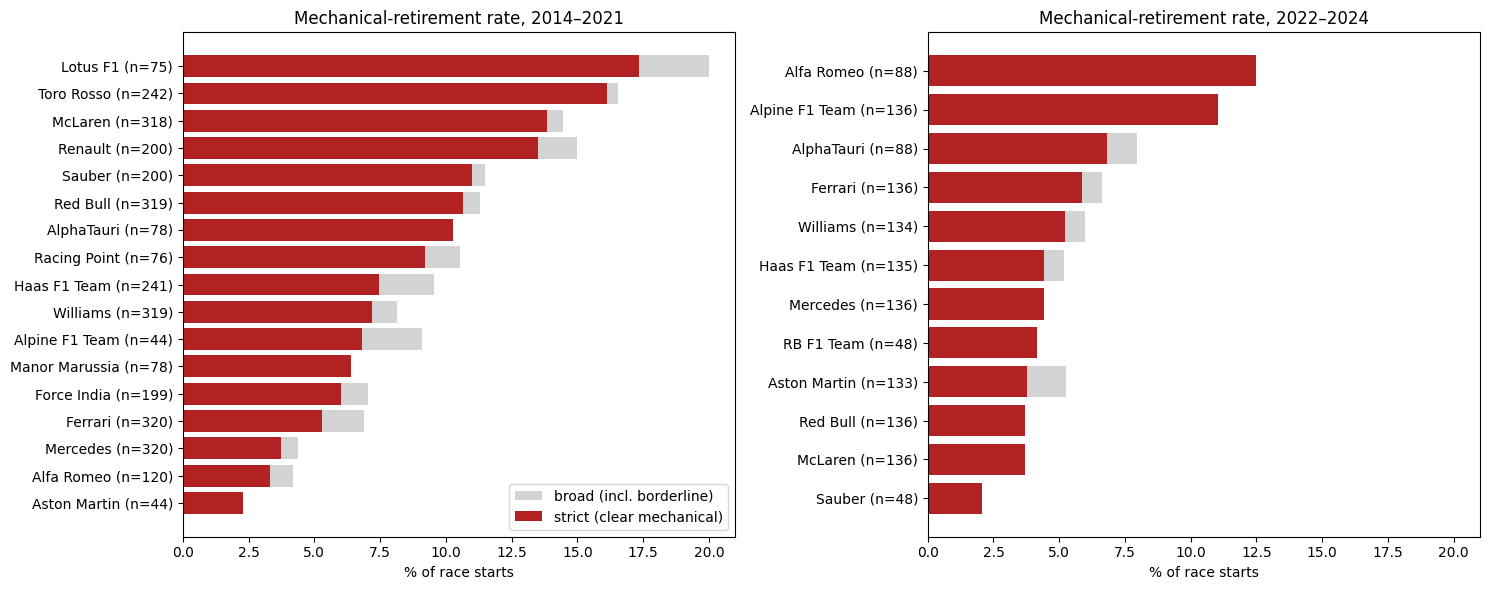

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, era in zip(axes, ["2014–2021", "2022–2024"]):
    t = tbl[tbl["era"] == era].sort_values("rate_strict_%")
    labels = t["constructor"] + " (n=" + t["starts"].astype(str) + ")"
    ax.barh(labels, t["rate_broad_%"], color="lightgray", label="broad (incl. borderline)")
    ax.barh(labels, t["rate_strict_%"], color="firebrick", label="strict (clear mechanical)")
    ax.set_title(f"Mechanical-retirement rate, {era}")
    ax.set_xlabel("% of race starts")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()


**Q3 answer. Using a strict definition (clear component failures only; crashes, driver errors, disqualifications, and non-starts excluded), the constructors with the highest mechanical-retirement rate were Lotus F1 (~17%) and Toro Rosso (~16%) in 2014–2021, and Alfa Romeo (~12.5%) and Alpine (~11%) in 2022–2024. The ranking changed substantially between eras, while Mercedes was among the most reliable in 2014–2021 (3.8%, third lowest) and mid-table in 2022–2024 (about 4.4%). Engine and power-unit failures are the leading cause overall. Including borderline statuses (wing damage, punctures) barely changes the ranking, so the result is robust to that judgment call.Grain: one row per driver per race start. Missingness: statusId is complete; all 139 statuses are mapped (see status_map); non-starts (DNQ, DNPQ, 107% rule, withdrawn) are excluded from the denominator. Cutoff: status is post-race information, so it is used here for description only, never as a model feature. Limitations: constructor renames split team history; 2022–2024 has few races, so differences of 1–2 points between teams are within noise; the borderline group is a judgment call.**


# Requirement 3: Feature Selection & Engineering
## Section A: Which rows enter the modeling table?
Before choosing a row policy we audit three things: what `grid == 0` means, how many rows are non-starters, and how qualifying coverage varies by season.

In [35]:
audit = base.merge(status_map[["statusId", "status", "category"]], on="statusId", how="left")

g0 = audit[audit["grid"] == 0]
print(f"grid == 0 rows: {len(g0)} of {len(audit)} ({len(g0)/len(audit)*100:.1f}%)")
print("\nWhat happened to the grid == 0 drivers (status category):")
display(g0["category"].value_counts())

# By era: non-starters vs real starters (pit-lane / back-of-grid starts)
era_bins = pd.cut(g0["year"], [1949, 1969, 1989, 2005, 2013, 2024],
                  labels=["1950-69", "1970-89", "1990-2005", "2006-13", "2014-24"])
display(g0.groupby(era_bins, observed=True)["category"].value_counts().unstack(fill_value=0))

grid == 0 rows: 1635 of 26668 (6.1%)

What happened to the grid == 0 drivers (status category):


category
not_a_start       1507
finished            56
non_mechanical      53
mechanical          18
borderline           1
Name: count, dtype: int64

category,borderline,finished,mechanical,non_mechanical,not_a_start
year,,,,,
1950-69,0,0,6,6,252
1970-89,0,0,1,23,897
1990-2005,0,0,0,15,349
2006-13,0,0,0,1,6
2014-24,1,56,11,8,3


In the F1 data, grid = 0 is ambiguous. It can mean the driver started from the pit lane, or that they never started at all (DNQ, withdrew).The above cell takes all rows with grid == 0 and checks each one’s status category.


* not_a_start means the driver never raced.
* Anything else (finished, mechanical, ...) means they raced from the pit lane.


Result: 1,507 of the 1,635 are real non-starters, and 128 are real starters.

Total non-start rows: 1610


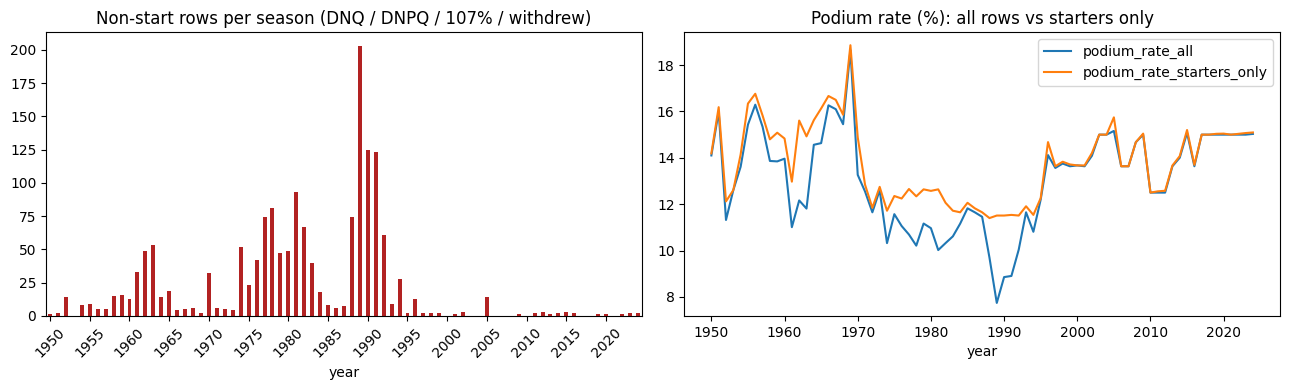

In [36]:
audit["non_start"] = audit["category"] == "not_a_start"

by_year = audit.groupby("year").agg(
    rows=("podium", "size"),
    non_starts=("non_start", "sum"),
    podium_rate_all=("podium", "mean"),
)
by_year["podium_rate_starters_only"] = audit[~audit["non_start"]].groupby("year")["podium"].mean()
print("Total non-start rows:", int(audit["non_start"].sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_year["non_starts"].plot(kind="bar", ax=axes[0], color="firebrick")
axes[0].set_title("Non-start rows per season (DNQ / DNPQ / 107% / withdrew)")
axes[0].set_xticks(range(0, len(by_year), 5)); axes[0].set_xticklabels(by_year.index[::5], rotation=45)

(by_year[["podium_rate_all", "podium_rate_starters_only"]] * 100).plot(ax=axes[1])
axes[1].set_title("Podium rate (%): all rows vs starters only")
plt.tight_layout(); plt.show()

The cells above answer the question, how do non-starters affect the data?

It counts non-start rows per season and compares the podium rate with them against starters only. This tells you whether keeping them distorts the target. It does: before the mid-1990s they pull the podium rate down (7.8% vs 11.5% in 1989), because they inflate the number of rows without adding podiums.

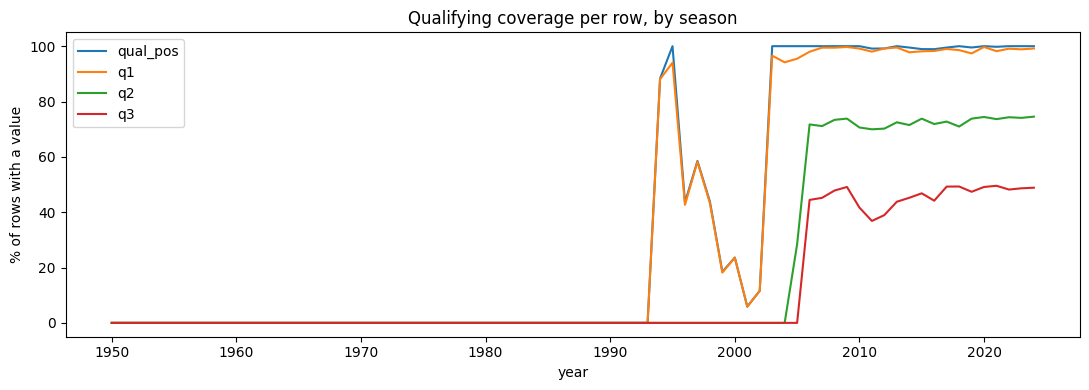

,qual_pos,q1,q2,q3
year,,,,
1994,88.3,88.1,0.0,0.0
1995,100.0,94.0,0.0,0.0
1996,43.5,42.6,0.0,0.0
2002,11.6,11.6,0.0,0.0
2003,100.0,96.6,0.0,0.0
2005,100.0,95.5,28.5,0.0
2006,100.0,98.0,71.7,44.4
2010,100.0,99.1,70.6,41.7
2015,98.9,98.1,73.8,46.8


In [37]:
cov = base.merge(
    df["qualifying"][["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]]
      .rename(columns={"position": "qual_pos"}),
    on=["raceId", "driverId"], how="left", validate="one_to_one")

cov_by_year = cov.groupby("year").agg(
    qual_pos=("qual_pos", lambda s: s.notna().mean() * 100),
    q1=("q1_sec", lambda s: s.notna().mean() * 100),
    q2=("q2_sec", lambda s: s.notna().mean() * 100),
    q3=("q3_sec", lambda s: s.notna().mean() * 100),
)
ax = cov_by_year.plot(figsize=(11, 4))
ax.set_ylabel("% of rows with a value"); ax.set_title("Qualifying coverage per row, by season")
plt.tight_layout(); plt.show()
display(cov_by_year[cov_by_year.index.isin([1994, 1995, 1996, 2002, 2003, 2005, 2006, 2010, 2015, 2024])].round(1))

The cell above answers the question, for each season, what share of the driver-race rows actually has qualifying data?

It joins base with qualifying.csv, so every race row is kept and any row with no qualifying record gets NaN. It then computes the % of non-missing values per season for qual_pos, q1_sec, q2_sec and q3_sec, and plots them.

The result shows qualifying data is absent before 1994, unreliable until 2002, and complete from 2003 (qual_pos) and 2006 (q1-q3). That decides which years you can use for training.

In [38]:
chk = audit[(audit["category"] == "not_a_start") & (audit["grid"] > 0)]
print("non-start rows with grid > 0:", len(chk))
display(chk["status"].value_counts())
display(chk["year"].value_counts().sort_index().head(15))
print("podium=1 among all non-start rows:", int(audit.loc[audit["category"] == "not_a_start", "podium"].sum()))

non-start rows with grid > 0: 103


status
Withdrew           84
Did not qualify    12
107% Rule           7
Name: count, dtype: int64

year
1950    1
1951    2
1952    2
1954    7
1955    2
1962    2
1964    2
1965    1
1969    2
1970    2
1972    1
1973    4
1974    3
1975    5
1976    4
Name: count, dtype: int64

podium=1 among all non-start rows: 0


**Non-starters with a grid slot.** 103 non-start rows (84 Withdrew, 12 DNQ, 7 107% rule) carry a positive grid value but never raced. None is a podium finisher. Non-starters are therefore identified by status category rather than by grid == 0, which would both miss these rows and wrongly remove real pit-lane starters.

In [39]:
scope = base.merge(status_map[["statusId", "status", "category"]],
                   on="statusId", how="left", validate="many_to_one")
scope = scope.merge(df["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}),
                    on="circuitId", how="left", validate="many_to_one")
steps = [("after grain fix (base)", len(scope))]

# Rule 1: Indianapolis 500, 1950-1960
indy = scope["circuit"].str.contains("Indianapolis", na=False) & (scope["year"] <= 1960)
scope = scope[~indy]
steps.append(("minus Indy 500 (1950-60)", len(scope)))

# Rule 2: non-starters (no race outcome)
scope = scope[scope["category"] != "not_a_start"]
steps.append(("minus non-starters", len(scope)))

# Rule 3: keep pit-lane starters, flag them
scope["is_pit_lane_start"] = (scope["grid"] == 0).astype(int)
scope = scope.reset_index(drop=True)

assert not scope.duplicated(["raceId", "driverId"]).any()
scope_log = pd.DataFrame(steps, columns=["step", "rows"])
scope_log["removed"] = -scope_log["rows"].diff().fillna(0).astype(int)
display(scope_log)

print("Pit-lane starters kept:", int(scope["is_pit_lane_start"].sum()))
print("Podium rate:", round(scope["podium"].mean() * 100, 2), "%")
pp = scope.groupby("raceId")["podium"].sum()
print("Races where podium rows != 3:", int((pp != 3).sum()))

,step,rows,removed
0,after grain fix (base),26668,0
1,minus Indy 500 (1950-60),26287,381
2,minus non-starters,24677,1610


Pit-lane starters kept: 128
Podium rate: 13.61 %
Races where podium rows != 3: 15


**Row-scope result.** Starting from the de-duplicated results table (26,668 rows), we remove the Indy 500 1950-60 (381 rows) and non-starters identified by status category (1,610 rows), leaving 24,677 rows. Real starters with grid == 0 (128 rows) are kept and flagged with is_pit_lane_start. The podium rate among starters is 13.6%. 15 races do not have exactly three podium rows (see A6).

In [40]:
pp = scope.groupby("raceId")["podium"].sum()
odd = pp[pp != 3].rename("podium_rows").reset_index()
odd = odd.merge(df["races"][["raceId", "year", "name"]], on="raceId")
display(odd.sort_values("year"))

# Did the duplicate fix remove rows with positionOrder <= 3?
removed_ids = set(results_before["resultId"]) - set(df["results"]["resultId"])
lost = results_before[results_before["resultId"].isin(removed_ids)
                      & (results_before["positionOrder"] <= 3)]
print("Rows removed by the grain fix that had positionOrder <= 3:", len(lost))
display(lost.merge(df["races"][["raceId", "year", "name"]], on="raceId")
            [["year", "name", "driverId", "grid", "positionOrder"]].sort_values("year"))

,raceId,podium_rows,year,name
14,839,4,1950,Italian Grand Prix
12,828,5,1951,French Grand Prix
13,831,4,1951,Italian Grand Prix
11,810,4,1953,Dutch Grand Prix
10,806,4,1954,Italian Grand Prix
9,804,4,1954,German Grand Prix
7,792,5,1955,Argentine Grand Prix
8,793,4,1955,Monaco Grand Prix
2,784,4,1956,Argentine Grand Prix
4,787,4,1956,Belgian Grand Prix


Rows removed by the grain fix that had positionOrder <= 3: 2


,year,name,driverId,grid,positionOrder
0,1955,Argentine Grand Prix,642,5,3
1,1955,Argentine Grand Prix,427,5,3


In [41]:
odd_ids = odd["raceId"]
chk = scope[scope["raceId"].isin(odd_ids) & (scope["podium"] == 1)]
display(chk.merge(df["races"][["raceId", "name"]], on="raceId", suffixes=("", "_race"))
           [["year", "name_race", "driverId", "constructorId", "grid", "positionOrder"]]
           .sort_values(["year", "name_race", "positionOrder"]).head(30))

,year,name_race,driverId,constructorId,grid,positionOrder
41,1950,Italian Grand Prix,642,51,3,1
42,1950,Italian Grand Prix,802,6,6,2
44,1950,Italian Grand Prix,647,6,6,2
43,1950,Italian Grand Prix,786,51,5,3
35,1951,French Grand Prix,786,51,7,1
45,1951,French Grand Prix,579,51,7,1
36,1951,French Grand Prix,647,6,6,2
46,1951,French Grand Prix,498,6,6,2
37,1951,French Grand Prix,633,6,4,3
38,1951,Italian Grand Prix,647,6,3,1


**Races with more than 3 podium rows.** 15 races, all between 1950 and 1960, have 4-5 rows with positionOrder <= 3, probably because shared drives credit the same finishing position to more than one driver. Each is a distinct (raceId, driverId) pair, so grain is unaffected. The grain fix removed only 2 podium-ranked rows (both 1955 Argentine GP). The target keeps the brief’s definition (positionOrder <= 3). All of these races fall before any training window we will consider, so there is no modeling impact.

## Section B: Feature construction
`feat` holds only identifiers, the target and features known after qualifying and before the race. Outcome columns (`points`, `position*`, `status`, `laps`, `time`, `milliseconds`, `fastestLap*`, `rank`) stay in `scope` and are used only as **past** history for form features.

In [42]:
ID_COLS = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date"]
TARGET = "podium"

feat = scope[ID_COLS + [TARGET, "grid", "is_pit_lane_start"]].copy()
print(feat.shape)

(24677, 10)


In [43]:
# --- qualifying table: best lap and gap to pole computed on ALL qualifiers ---
qq = df["qualifying"][["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]].copy()
qq["q_best_sec"] = qq[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
qq["pole_sec"] = qq.groupby("raceId")["q_best_sec"].transform("min")
qq["gap_to_pole_pct"] = (qq["q_best_sec"] - qq["pole_sec"]) / qq["pole_sec"] * 100
qq = qq.rename(columns={"position": "qual_pos"})

feat = feat.merge(
    qq[["raceId", "driverId", "qual_pos", "q2_sec", "q3_sec", "gap_to_pole_pct"]],
    on=["raceId", "driverId"], how="left", validate="one_to_one")
assert len(feat) == len(scope)

# --- grid features ---
race_max_grid = feat.groupby("raceId")["grid"].transform("max")
feat["grid_adj"] = np.where(feat["grid"] == 0, race_max_grid + 1, feat["grid"])
feat["front_row"] = (feat["grid_adj"] <= 2).astype(int)
feat["grid_minus_qual"] = feat["grid_adj"] - feat["qual_pos"]   # > 0: started behind where they qualified
feat["grid_penalty_places"] = feat["grid_minus_qual"].clip(lower=0)

# --- reached Q2 / Q3 (only meaningful in the knockout format, 2006+) ---
ok = (feat["year"] >= 2006) & feat["qual_pos"].notna()
feat["reached_q2"] = np.where(ok, feat["q2_sec"].notna().astype(float), np.nan)
feat["reached_q3"] = np.where(ok, feat["q3_sec"].notna().astype(float), np.nan)
feat = feat.drop(columns=["q2_sec", "q3_sec", "grid"])

FEATURE_GROUPS = {
    "grid": ["grid_adj", "is_pit_lane_start", "front_row", "grid_minus_qual", "grid_penalty_places"],
    "qualifying": ["qual_pos", "gap_to_pole_pct", "reached_q2", "reached_q3"],
}

# --- checks ---
assert not feat.duplicated(["raceId", "driverId"]).any()
cols = sum(FEATURE_GROUPS.values(), [])
era = np.where(feat["year"] >= 2006, "2006+", np.where(feat["year"] >= 2003, "2003-05", "pre-2003"))
print("% non-missing by era:")
display((feat[cols].notna().groupby(era).mean() * 100).round(1).T)
print("\ngrid_minus_qual distribution, 2006+:")
display(feat.loc[feat["year"] >= 2006, "grid_minus_qual"].value_counts().sort_index().head(15))
display(feat.loc[feat["year"] >= 2006, ["grid_adj", "qual_pos", "gap_to_pole_pct"]].describe().round(2))

% non-missing by era:


,2003-05,2006+,pre-2003
grid_adj,100.0,100.0,100.0
is_pit_lane_start,100.0,100.0,100.0
front_row,100.0,100.0,100.0
grid_minus_qual,100.0,99.7,9.8
grid_penalty_places,100.0,99.7,9.8
qual_pos,100.0,99.7,9.8
gap_to_pole_pct,95.3,98.8,9.6
reached_q2,0.0,99.7,0.0
reached_q3,0.0,99.7,0.0



grid_minus_qual distribution, 2006+:


grid_minus_qual
-8.0       2
-7.0       4
-6.0      10
-5.0      16
-4.0      39
-3.0      84
-2.0     266
-1.0    1325
 0.0    5585
 1.0      66
 2.0      77
 3.0      94
 4.0      67
 5.0     107
 6.0      20
Name: count, dtype: int64

,grid_adj,qual_pos,gap_to_pole_pct
count,7893.00,7870.00,7795.00
mean,11.11,11.07,2.26
std,6.19,6.16,2.57
min,1.00,1.00,0.00
25%,6.00,6.00,0.83
50%,11.00,11.00,1.72
75%,16.00,16.00,2.85
max,24.00,24.00,45.60


**Grid and qualifying features.** qual_pos is complete from 2003; q2/q3 are structurally missing (knockout elimination) and are encoded as reached_q2/q3 from 2006 onward. grid_adj replaces grid = 0 (pit lane) with the race’s last slot + 1, with is_pit_lane_start kept as a flag. grid_minus_qual is 0 for 71% of 2006+ rows; positive values mark penalised drivers, negative values mark drivers promoted by others’ penalties, so grid_penalty_places isolates a driver’s own penalty. gap_to_pole_pct is comparable across circuits but has a heavy tail (max 45.6%), handled in the preprocessing section.

In [44]:
drv = df["drivers"][["driverId", "dob", "nationality"]]
circ = df["circuits"][["circuitId", "country"]].rename(columns={"country": "circuit_country"})
feat = (feat.merge(drv, on="driverId", how="left", validate="many_to_one")
            .merge(circ, on="circuitId", how="left", validate="many_to_one"))

feat["driver_age"] = (feat["date"] - feat["dob"]).dt.days / 365.25
home_lists = feat["nationality"].map(NAT_TO_COUNTRY)
feat["is_home"] = [int(isinstance(h, list) and c in h) for h, c in zip(home_lists, feat["circuit_country"])]
feat = feat.drop(columns=["dob", "nationality", "circuit_country"])

FEATURE_GROUPS["context"] = ["driver_age", "is_home", "round"]

assert len(feat) == len(scope) and not feat.duplicated(["raceId", "driverId"]).any()
display(feat[FEATURE_GROUPS["context"]].describe().round(2))
print("Home rows:", int(feat["is_home"].sum()), "| missing age:", int(feat["driver_age"].isna().sum()))

,driver_age,is_home,round
count,24677.00,24677.00,24677.00
mean,29.91,0.08,8.68
std,5.24,0.27,5.09
min,17.45,0.00,1.00
25%,26.07,0.00,4.00
50%,29.36,0.00,8.00
75%,33.24,0.00,13.00
max,56.77,1.00,24.00


Home rows: 1942 | missing age: 0


**Context features.** driver_age is computed from date of birth and the race date, is_home reuses the Q2 nationality-to-country mapping (1,942 rows, about 8%), and round is the race’s position in the season calendar. All three are fixed before the race. is_home is kept as a candidate only: Q2 found no detectable home effect once grid position is controlled for, so Section D decides whether it stays. circuitId and year are not included yet, because circuit needs an encoding choice and year would put the test years outside the training range.

In [45]:
N_FORM = 5   # form window in races (previous 5 races, spanning seasons)

hist = scope[["raceId", "driverId", "constructorId", "year", "date",
              "podium", "positionOrder", "category"]].copy()
hist["dnf"] = (hist["category"] != "finished").astype(int)
hist["mech_dnf"] = (hist["category"] == "mechanical").astype(int)

def past_roll(s, n):
    """Mean of the previous n values. shift(1) first, so the current race is never included."""
    return s.shift(1).rolling(n, min_periods=1).mean()

def build_form(hist, n=N_FORM):
    h = hist.sort_values(["driverId", "date", "raceId"]).copy()
    g = h.groupby("driverId")
    h["drv_podium_rate"]   = g["podium"].transform(lambda s: past_roll(s, n))
    h["drv_avg_finish"]    = g["positionOrder"].transform(lambda s: past_roll(s, n))
    h["drv_dnf_rate"]      = g["dnf"].transform(lambda s: past_roll(s, n))
    h["drv_starts_before"] = g.cumcount()          # number of earlier starts; 0 = debut

    # constructor: one row per (team, race) FIRST, then shift
    c = (hist.groupby(["constructorId", "raceId", "date"], as_index=False)
             .agg(podium=("podium", "mean"), finish=("positionOrder", "mean"),
                  mech=("mech_dnf", "mean")))
    c = c.sort_values(["constructorId", "date", "raceId"])
    gc = c.groupby("constructorId")
    c["con_podium_rate"]   = gc["podium"].transform(lambda s: past_roll(s, n))
    c["con_avg_finish"]    = gc["finish"].transform(lambda s: past_roll(s, n))
    c["con_mech_dnf_rate"] = gc["mech"].transform(lambda s: past_roll(s, n))

    drv_cols = ["drv_podium_rate", "drv_avg_finish", "drv_dnf_rate", "drv_starts_before"]
    con_cols = ["con_podium_rate", "con_avg_finish", "con_mech_dnf_rate"]
    out = h[["raceId", "driverId", "constructorId"] + drv_cols].merge(
        c[["constructorId", "raceId"] + con_cols],
        on=["constructorId", "raceId"], how="left", validate="many_to_one")
    return out.drop(columns="constructorId")

form = build_form(hist)
feat = feat.merge(form, on=["raceId", "driverId"], how="left", validate="one_to_one")
assert len(feat) == len(scope) and not feat.duplicated(["raceId", "driverId"]).any()

FEATURE_GROUPS["driver_form"] = ["drv_podium_rate", "drv_avg_finish", "drv_dnf_rate", "drv_starts_before"]
FEATURE_GROUPS["constructor_form"] = ["con_podium_rate", "con_avg_finish", "con_mech_dnf_rate"]

In [46]:
r = hist.loc[hist["year"] == 2015, "raceId"].iloc[40]       # any mid-history race
h2 = hist.copy()
m = h2["raceId"] == r
h2.loc[m, "podium"] = 1 - h2.loc[m, "podium"]
h2.loc[m, "positionOrder"] = 99
h2.loc[m, "dnf"] = 1 - h2.loc[m, "dnf"]
h2.loc[m, "mech_dnf"] = 1 - h2.loc[m, "mech_dnf"]
form2 = build_form(h2)

keys = ["raceId", "driverId"]
a, b = form.set_index(keys).sort_index(), form2.set_index(keys).sort_index()
in_r = a.index.get_level_values("raceId") == r
assert a[in_r].equals(b[in_r]), "LEAK: a race's own result changed its own features"
assert not a.equals(b), "Test is not sensitive: later races did not change"
print("Leakage test passed: own race unchanged, later races changed.")

Leakage test passed: own race unchanged, later races changed.


In [47]:
fcols = FEATURE_GROUPS["driver_form"] + FEATURE_GROUPS["constructor_form"]
display(feat[fcols].describe().round(2))
print("Missing:\n", feat[fcols].isna().sum())

# Eyeball one driver's debut: the first row must be NaN, the second must equal race 1's result
lh = df["drivers"].query("forename == 'Lewis' and surname == 'Hamilton'")["driverId"].iloc[0]
display(feat[feat["driverId"] == lh].sort_values("date")
        [["date", "podium", "drv_podium_rate", "drv_avg_finish", "drv_starts_before", "con_podium_rate"]].head(8))

,drv_podium_rate,drv_avg_finish,drv_dnf_rate,drv_starts_before,con_podium_rate,con_avg_finish,con_mech_dnf_rate
count,23991.00,23991.00,23991.00,24677.00,24412.00,24412.00,24412.00
mean,0.14,11.67,0.39,68.10,0.14,11.68,0.25
std,0.24,4.44,0.29,68.99,0.20,3.91,0.21
min,0.00,1.00,0.00,0.00,0.00,1.50,0.00
25%,0.00,8.60,0.20,15.00,0.00,8.93,0.10
50%,0.00,12.00,0.40,45.00,0.00,11.90,0.20
75%,0.20,14.80,0.60,100.00,0.20,14.40,0.40
max,1.00,31.00,1.00,401.00,1.00,26.00,1.00


Missing:
 drv_podium_rate      686
drv_avg_finish       686
drv_dnf_rate         686
drv_starts_before      0
con_podium_rate      265
con_avg_finish       265
con_mech_dnf_rate    265
dtype: int64


,date,podium,drv_podium_rate,drv_avg_finish,drv_starts_before,con_podium_rate
370,2007-03-18,1,NaN,NaN,0,0.1
391,2007-04-08,1,1.0,3.000000,1,0.3
413,2007-04-15,1,1.0,2.500000,2,0.4
435,2007-05-13,1,1.0,2.333333,3,0.5
457,2007-05-27,1,1.0,2.250000,4,0.7
478,2007-06-10,1,1.0,2.200000,5,0.9
500,2007-06-17,1,1.0,1.800000,6,0.8
524,2007-07-01,1,1.0,1.600000,7,0.8


**Form features (leakage-safe).** Driver form (podium rate, average finish, DNF rate over the previous 5 starts, plus drv_starts_before) and constructor form (podium share, average finish and mechanical-DNF rate over the team’s previous 5 races) are computed with shift(1) before the rolling window, so a race never enters its own features. Constructor form is aggregated to one row per (team, race) before shifting, so a teammate’s result from the same weekend cannot leak in. Windows span seasons. Debuts (686 driver rows, 265 constructor rows) are NaN and handled in the preprocessing section. A controlled test (rewriting one race’s outcomes and recomputing) confirmed that the race’s own features did not change while later races’ features did. Limitations: a constructor rename resets its history, and a returning driver’s window may span a long gap.

In [48]:
assert "drv_points_before" not in feat.columns, "B4 already ran on this feat: re-run B0 first"

rr = df["races"][["raceId", "year", "round"]]

def standings_before(st, entity, prefix):
    s = (st.merge(rr, on="raceId")[[entity, "year", "round", "points", "position"]]
           .rename(columns={"points": f"{prefix}_points_before", "position": f"{prefix}_pos_before"})
           .sort_values("round"))
    left = feat[["raceId", entity, "year", "round"]].sort_values("round")
    out = pd.merge_asof(left, s, on="round", by=[entity, "year"], allow_exact_matches=False)
    return out.drop(columns=["year", "round"]).drop_duplicates(["raceId", entity])

drv_st = standings_before(df["driver_standings"], "driverId", "drv")
con_st = standings_before(df["constructor_standings"], "constructorId", "con")

feat = feat.merge(drv_st, on=["raceId", "driverId"], how="left", validate="one_to_one")
feat = feat.merge(con_st, on=["raceId", "constructorId"], how="left", validate="many_to_one")
assert len(feat) == len(scope) and not feat.duplicated(["raceId", "driverId"]).any()

# No earlier standings row in the season = nothing scored yet -> 0 points (position stays NaN)
feat[["drv_points_before", "con_points_before"]] = feat[["drv_points_before", "con_points_before"]].fillna(0)

# Points scales changed over time (e.g. 10 -> 25 for a win in 2010): also give points relative to the leader
leader = feat.groupby("raceId")["drv_points_before"].transform("max")
feat["drv_pts_frac_leader"] = np.where(leader > 0, feat["drv_points_before"] / leader, 0.0)

FEATURE_GROUPS["standings"] = ["drv_points_before", "drv_pos_before", "drv_pts_frac_leader",
                               "con_points_before", "con_pos_before"]

# --- checks ---
print("Round 1, driver points before (must be only 0):",
      feat.loc[feat["round"] == 1, "drv_points_before"].unique())

ad = df["races"].query("year == 2021 and name == 'Abu Dhabi Grand Prix'")["raceId"].iloc[0]
display(feat[feat["raceId"] == ad].nlargest(3, "drv_points_before")
        [["driverId", "drv_points_before", "drv_pos_before", "drv_pts_frac_leader"]]
        .merge(df["drivers"][["driverId", "surname"]], on="driverId"))

display(feat[FEATURE_GROUPS["standings"]].describe().round(2))
print("Missing:\n", feat[FEATURE_GROUPS["standings"]].isna().sum())

Round 1, driver points before (must be only 0): [0.]


,driverId,drv_points_before,drv_pos_before,drv_pts_frac_leader,surname
0,830,369.5,1.0,1.000000,Verstappen
1,1,369.5,2.0,1.000000,Hamilton
2,822,218.0,3.0,0.589986,Bottas


,drv_points_before,drv_pos_before,drv_pts_frac_leader,con_points_before,con_pos_before
count,24677.00,21764.00,24677.00,24677.00,21763.00
mean,18.13,12.85,0.19,36.61,6.10
std,42.05,8.95,0.28,81.34,3.63
min,0.00,1.00,0.00,0.00,1.00
25%,0.00,6.00,0.00,0.00,3.00
50%,3.00,12.00,0.05,8.00,6.00
75%,16.00,18.00,0.27,33.00,9.00
max,549.00,102.00,1.00,822.00,20.00


Missing:
 drv_points_before         0
drv_pos_before         2913
drv_pts_frac_leader       0
con_points_before         0
con_pos_before         2914
dtype: int64


In [49]:
assert "con_pos_calc" not in feat.columns, "Already ran: re-run B0-B4 first"

# One row per (race, team) before ranking, otherwise a team's two cars would count twice
cp = feat[["raceId", "constructorId", "round", "con_points_before"]].drop_duplicates(["raceId", "constructorId"])
cp["con_pos_calc"] = (cp.groupby("raceId")["con_points_before"]
                        .rank(method="min", ascending=False)
                        .where(cp["round"] > 1))          # round 1: nothing to rank yet, keep NaN
feat = feat.merge(cp[["raceId", "constructorId", "con_pos_calc"]],
                  on=["raceId", "constructorId"], how="left", validate="many_to_one")

# Check 1: how often does the recomputed rank equal the dataset's rank (modern era, rank available)?
mm = feat[(feat["year"] >= 2006) & feat["con_pos_before"].notna()]
print("Agreement 2006+ (excluding McLaren 2007):",
      round((mm["con_pos_calc"] == mm["con_pos_before"]).mean() * 100, 1), "%")

# Check 2: McLaren 2007 now has a sensible rank
mc = feat[(feat["year"] == 2007)].merge(df["constructors"][["constructorId", "name"]], on="constructorId")
display(mc[mc["name"] == "McLaren"].groupby("round")[["con_points_before", "con_pos_calc"]].first())

feat["con_pos_before"] = feat["con_pos_calc"]
feat = feat.drop(columns="con_pos_calc")

Agreement 2006+ (excluding McLaren 2007): 86.1 %


,con_points_before,con_pos_calc
round,,
1,0.0,NaN
2,14.0,1.0
3,32.0,1.0
4,44.0,1.0
5,58.0,1.0
6,76.0,1.0
7,88.0,1.0
8,106.0,1.0
9,114.0,1.0


In [50]:
orig = (standings_before(df["constructor_standings"], "constructorId", "con")
        [["raceId", "constructorId", "con_pos_before"]]
        .rename(columns={"con_pos_before": "orig_pos"}))

d = (feat.merge(orig, on=["raceId", "constructorId"], how="left")
         .merge(df["constructors"][["constructorId", "name"]], on="constructorId"))
d = d[(d["year"] >= 2006) & d["orig_pos"].notna() & d["con_pos_before"].notna()
      & ~((d["year"] == 2007) & (d["name"] == "McLaren"))]
d = d.drop_duplicates(["raceId", "constructorId"])          # one row per team per race

d["tied"] = d.duplicated(["raceId", "con_points_before"], keep=False)
d["match"] = d["con_pos_before"] == d["orig_pos"]
print("Overall agreement (one row per team-race):", round(d["match"].mean() * 100, 1), "%")
display(d.groupby("tied")["match"].agg(rows="size", agreement="mean").round(3))
print("Largest disagreement among untied rows:",
      (d.loc[~d["tied"], "con_pos_before"] - d.loc[~d["tied"], "orig_pos"]).abs().max())

Overall agreement (one row per team-race): 86.5 %


,rows,agreement
tied,,
False,3112,0.962
True,618,0.374


Largest disagreement among untied rows: 1.0


**Standings before the race**. Driver and constructor points and ranks come from the standings table, but only from the latest round strictly before the current one in the same season (merge_asof with allow_exact_matches=False), because the standings stored under a race’s own raceId include that race’s result. Round-1 rows have 0 points and no rank. drv_pts_frac_leader (points divided by the leader’s points) makes the feature comparable across points systems. Check: before the 2021 Abu Dhabi GP, Verstappen and Hamilton are both on 369.5 points. Limitation: constructor standings begin in 1958, and early driver standings are incomplete, so these features are only reliable in the modern era.

In [51]:
FORBIDDEN = {"points", "position", "positionText", "positionOrder", "statusId", "status", "category",
             "laps", "time", "milliseconds", "fastestLap", "fastestLapTime", "fastestLapSpeed",
             "fastestLapTime_sec", "rank"}
all_feats = sum(FEATURE_GROUPS.values(), [])
assert not (set(all_feats) & FORBIDDEN), "Forbidden column in features"
assert TARGET not in all_feats
print({k: len(v) for k, v in FEATURE_GROUPS.items()}, "| total features:", len(all_feats))

{'grid': 5, 'qualifying': 4, 'context': 3, 'driver_form': 4, 'constructor_form': 3, 'standings': 5} | total features: 24


In [52]:
m = feat[feat["year"] >= 2003]
print("2003+ rows:", len(m))
print("missing drv_pos_before by round:",
      m.loc[m["drv_pos_before"].isna(), "round"].value_counts().sort_index().to_dict())
print("rows before 1958 (no constructor standings exist):", int((feat["year"] < 1958).sum()))

2003+ rows: 8935
missing drv_pos_before by round: {1: 455, 2: 53, 3: 18, 4: 9, 5: 3, 6: 2, 7: 3, 8: 1, 9: 1, 10: 5, 11: 6, 12: 7, 13: 10, 14: 5, 15: 5, 16: 9, 17: 2, 18: 1, 19: 2, 24: 1}
rows before 1958 (no constructor standings exist): 1163


**Section B summary**. feat has 24,677 rows (one per driver per race start) and 24 pre-race features in six groups stored in FEATURE_GROUPS (grid 5, qualifying 4, context 3, driver form 4, constructor form 3, standings 5). Outcome columns are excluded and a guard cell enforces it. Missing values are left unfilled; imputation is part of preprocessing (Section E), fitted on training data only.

# Section C: Feature evidence
Every feature group is checked against the target: does the podium rate change across the feature's range? Evidence uses 2006-2019 only (consistent qualifying format, and no validation/test years, so feature decisions never see them). Bars show the podium rate per bin with 95% confidence intervals; labels show the number of rows.

In [53]:
EV = feat[(feat["year"] >= 2006) & (feat["year"] <= 2019)].copy()
print("Evidence rows:", len(EV), "| podium rate:", round(EV[TARGET].mean() * 100, 1), "%")

SIGNAL = {}   # feature -> spread of podium rate across bins (percentage points)

def rate_by_bin(frame, col, bins, labels):
    b = pd.cut(frame[col], bins=bins, labels=labels, include_lowest=True)
    t = frame.groupby(b, observed=True)[TARGET].agg(n="size", rate="mean")
    t["ci"] = 1.96 * np.sqrt(t["rate"] * (1 - t["rate"]) / t["n"])
    ok = t[t["n"] >= 50]
    SIGNAL[col] = (ok["rate"].max() - ok["rate"].min()) * 100 if len(ok) else np.nan
    return t

def plot_rate(ax, t, title):
    ax.bar(range(len(t)), t["rate"] * 100, yerr=t["ci"] * 100, capsize=3, color="steelblue")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([f"{i}\nn={n}" for i, n in zip(t.index.astype(str), t["n"])], fontsize=7)
    ax.set_ylabel("% podium")
    ax.set_title(title, fontsize=10)

def panels(specs, ncols=3, frame=EV):
    nrows = -(-len(specs) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.8 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (col, bins, labels, title) in zip(axes, specs):
        plot_rate(ax, rate_by_bin(frame, col, bins, labels), title)
    for ax in axes[len(specs):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

YN = ([-0.5, 0.5, 1.5], ["no", "yes"])

Evidence rows: 5760 | podium rate: 14.0 %


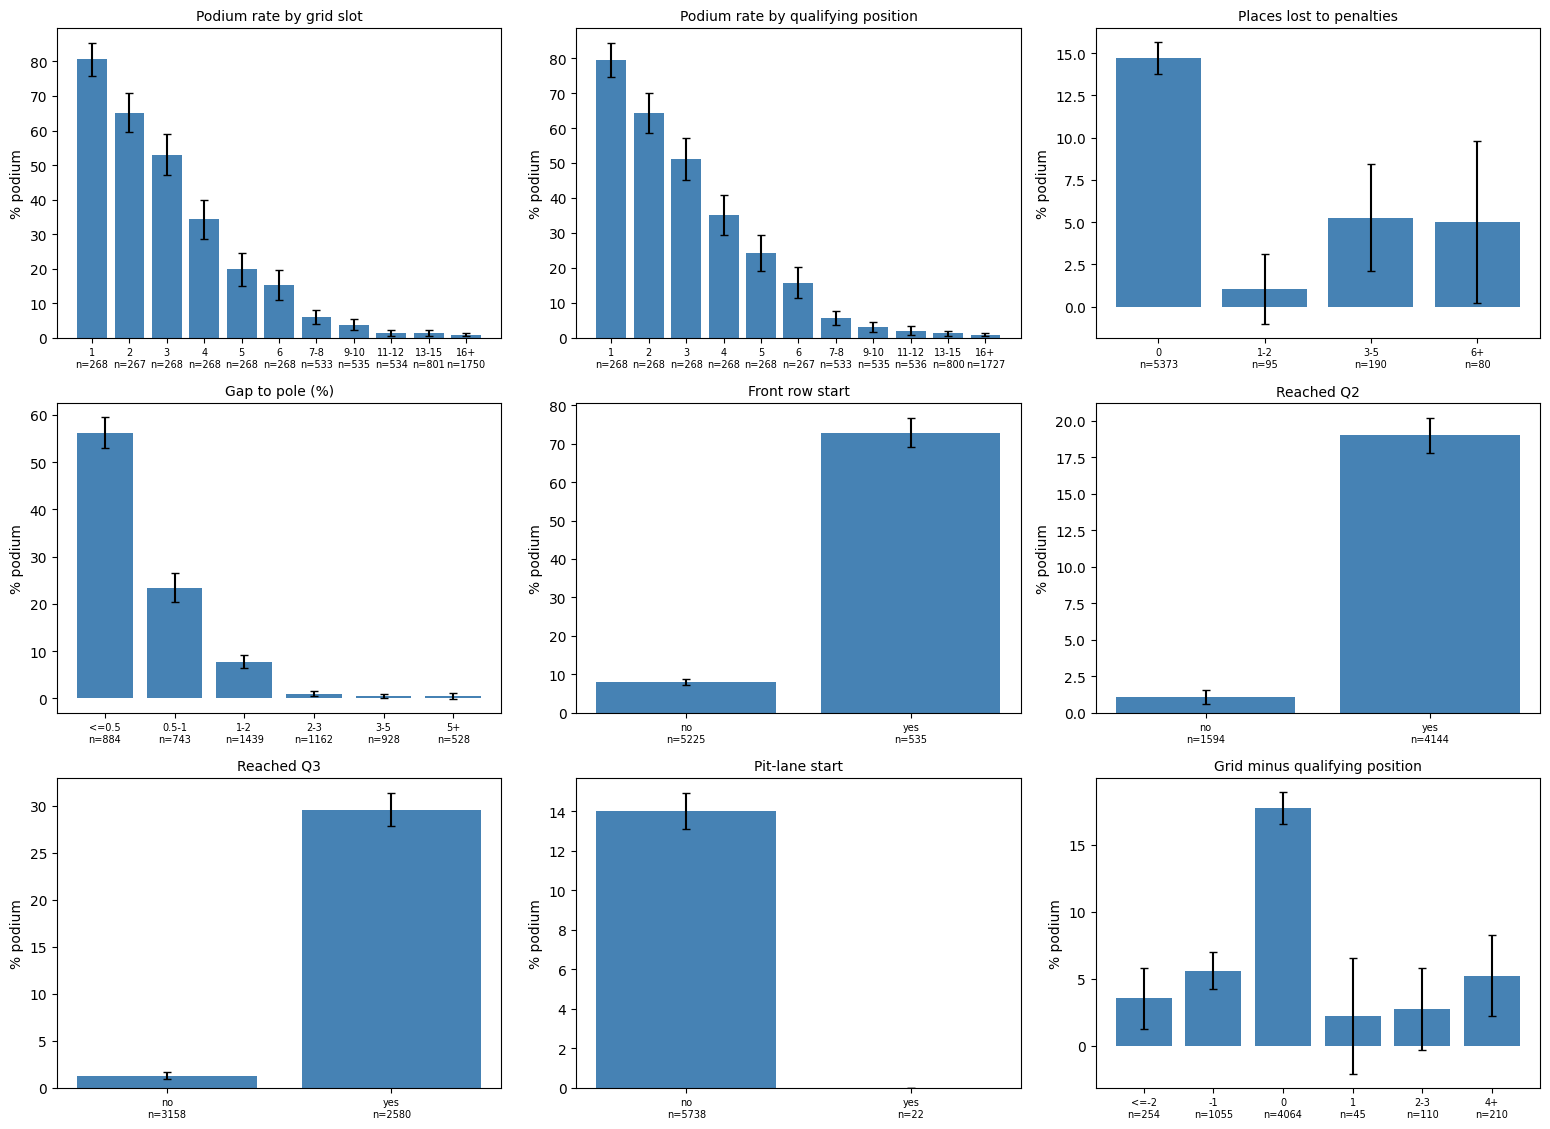

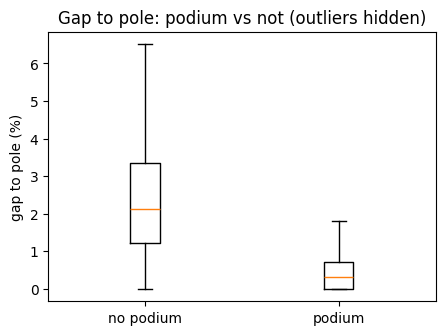

Median gap to pole: {0: 2.12, 1: 0.32}


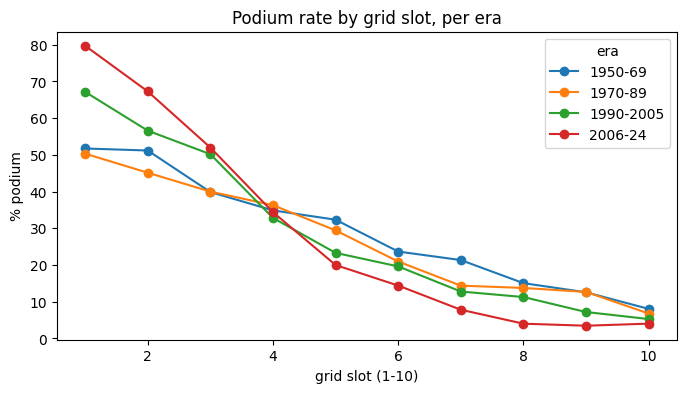

In [54]:
G = [0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 30]
GL = ["1", "2", "3", "4", "5", "6", "7-8", "9-10", "11-12", "13-15", "16+"]

panels([
    ("grid_adj", G, GL, "Podium rate by grid slot"),
    ("qual_pos", G, GL, "Podium rate by qualifying position"),
    ("grid_penalty_places", [-1, 0, 2, 5, 100], ["0", "1-2", "3-5", "6+"], "Places lost to penalties"),
    ("gap_to_pole_pct", [-0.01, 0.5, 1, 2, 3, 5, 100], ["<=0.5", "0.5-1", "1-2", "2-3", "3-5", "5+"], "Gap to pole (%)"),
    ("front_row", *YN, "Front row start"),
    ("reached_q2", *YN, "Reached Q2"),
    ("reached_q3", *YN, "Reached Q3"),
    ("is_pit_lane_start", *YN, "Pit-lane start"),
    ("grid_minus_qual", [-30, -2, -1, 0, 1, 3, 30], ["<=-2", "-1", "0", "1", "2-3", "4+"], "Grid minus qualifying position"),
])

# Gap to pole: podium vs non-podium
g = EV.dropna(subset=["gap_to_pole_pct"])
data = [g.loc[g[TARGET] == 0, "gap_to_pole_pct"], g.loc[g[TARGET] == 1, "gap_to_pole_pct"]]
plt.figure(figsize=(5, 3.5))
plt.boxplot(data, showfliers=False)
plt.xticks([1, 2], ["no podium", "podium"])
plt.ylabel("gap to pole (%)")
plt.title("Gap to pole: podium vs not (outliers hidden)")
plt.show()
print("Median gap to pole:", g.groupby(TARGET)["gap_to_pole_pct"].median().round(2).to_dict())

# Why a training window matters: the grid curve across eras (all years)
sub = feat[feat["grid_adj"] <= 10].copy()
sub["era"] = pd.cut(sub["year"], [1949, 1969, 1989, 2005, 2024],
                    labels=["1950-69", "1970-89", "1990-2005", "2006-24"])
(sub.groupby(["grid_adj", "era"], observed=True)[TARGET].mean().unstack() * 100).plot(
    marker="o", figsize=(8, 4))
plt.ylabel("% podium"); plt.xlabel("grid slot (1-10)")
plt.title("Podium rate by grid slot, per era")
plt.show()

**Grid and qualifying**. Podium rate falls steeply with grid slot (about 81% from pole, 34% from P4, about 1% from P16 and beyond) and with gap to pole (median 0.32% for podium rows vs 2.12% for non-podium). qual_pos is nearly identical to grid_adj and front_row is a coarser version of both. Penalty features (grid_minus_qual, grid_penalty_places) show a weak, non-monotonic pattern because their reference bin is dominated by front-runners. is_pit_lane_start is inconclusive (22 rows in this window). Per-era curves show the front of the grid converting more strongly after 2006, which motivates the training-window experiment.

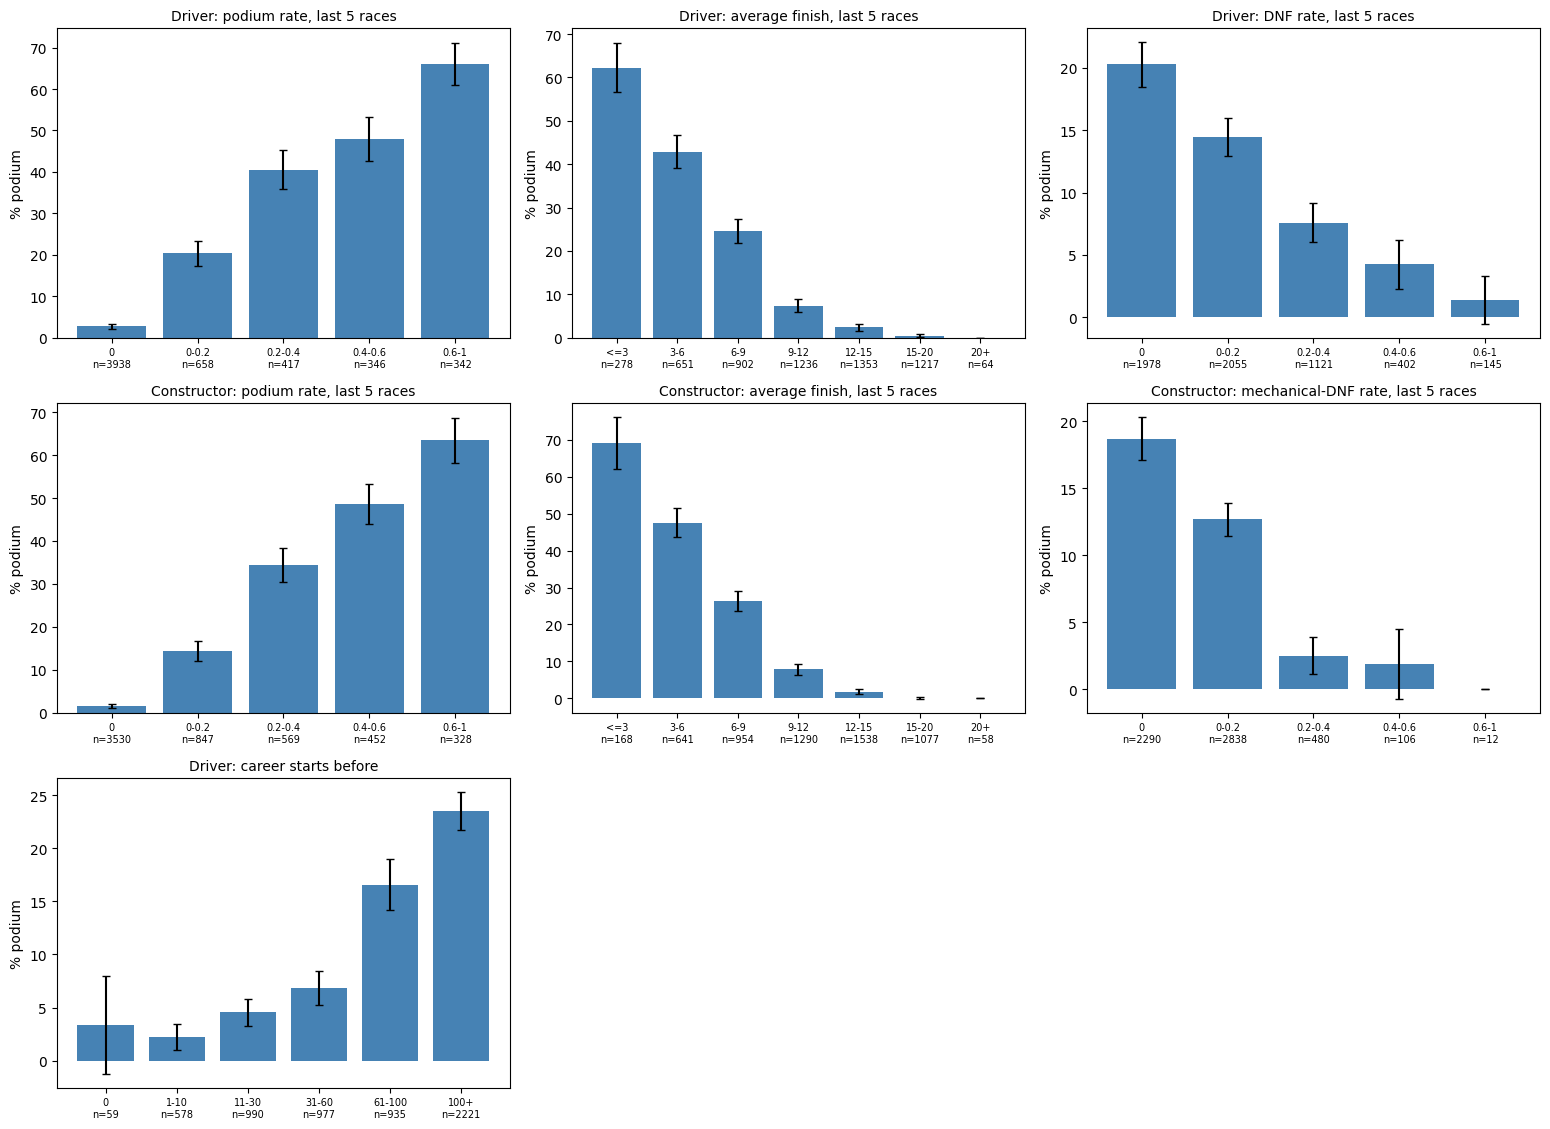

In [55]:
R = [-0.01, 0, 0.2, 0.4, 0.6, 1.0]
RL = ["0", "0-0.2", "0.2-0.4", "0.4-0.6", "0.6-1"]
F = [0, 3, 6, 9, 12, 15, 20, 40]
FL = ["<=3", "3-6", "6-9", "9-12", "12-15", "15-20", "20+"]

panels([
    ("drv_podium_rate", R, RL, "Driver: podium rate, last 5 races"),
    ("drv_avg_finish", F, FL, "Driver: average finish, last 5 races"),
    ("drv_dnf_rate", R, RL, "Driver: DNF rate, last 5 races"),
    ("con_podium_rate", R, RL, "Constructor: podium rate, last 5 races"),
    ("con_avg_finish", F, FL, "Constructor: average finish, last 5 races"),
    ("con_mech_dnf_rate", R, RL, "Constructor: mechanical-DNF rate, last 5 races"),
    ("drv_starts_before", [-1, 0, 10, 30, 60, 100, 500], ["0", "1-10", "11-30", "31-60", "61-100", "100+"], "Driver: career starts before"),
])

**Form**. All form features show a monotonic relationship with the podium rate: podium rate rises from 3% to 66% across driver podium-rate bins and from 1.5% to 63% across constructor bins; average finish falls from about 60% podium to about 0%. DNF and mechanical-DNF rates fall with podium chance, and career starts rise with it; both are probably proxies for car and seat quality. These are associations, not causes.

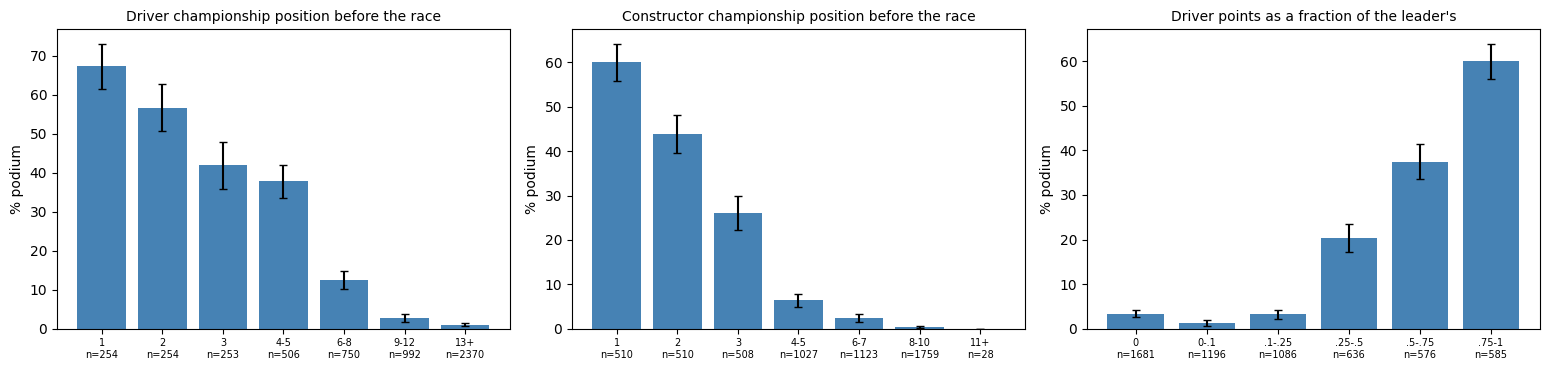

In [56]:
panels([
    ("drv_pos_before", [0, 1, 2, 3, 5, 8, 12, 30], ["1", "2", "3", "4-5", "6-8", "9-12", "13+"],
     "Driver championship position before the race"),
    ("con_pos_before", [0, 1, 2, 3, 5, 7, 10, 20], ["1", "2", "3", "4-5", "6-7", "8-10", "11+"],
     "Constructor championship position before the race"),
    ("drv_pts_frac_leader", [-0.01, 0, 0.1, 0.25, 0.5, 0.75, 1.0], ["0", "0-.1", ".1-.25", ".25-.5", ".5-.75", ".75-1"],
     "Driver points as a fraction of the leader's"),
])

In [57]:
m = feat[feat["year"] == 2007].merge(df["constructors"][["constructorId", "name"]], on="constructorId")
display(m[m["name"] == "McLaren"].groupby("round")[["con_points_before", "con_pos_before"]].first())

,con_points_before,con_pos_before
round,,
1,0.0,NaN
2,14.0,1.0
3,32.0,1.0
4,44.0,1.0
5,58.0,1.0
6,76.0,1.0
7,88.0,1.0
8,106.0,1.0
9,114.0,1.0


**Standings**. Championship position and points share before the race track the podium rate closely (driver P1: about 67%, P13+: about 1%; constructor P1: about 60%, P2: 44%, P3: 26%, P8+: under 1%). An earlier version of the constructor plot showed a spurious bump at ranks 11+ (23 podium rows, 22 of them McLaren 2007), because the dataset’s own rank was frozen at 11 for that team-season. The constructor rank is now recomputed from points before the race (see the fix after B4).

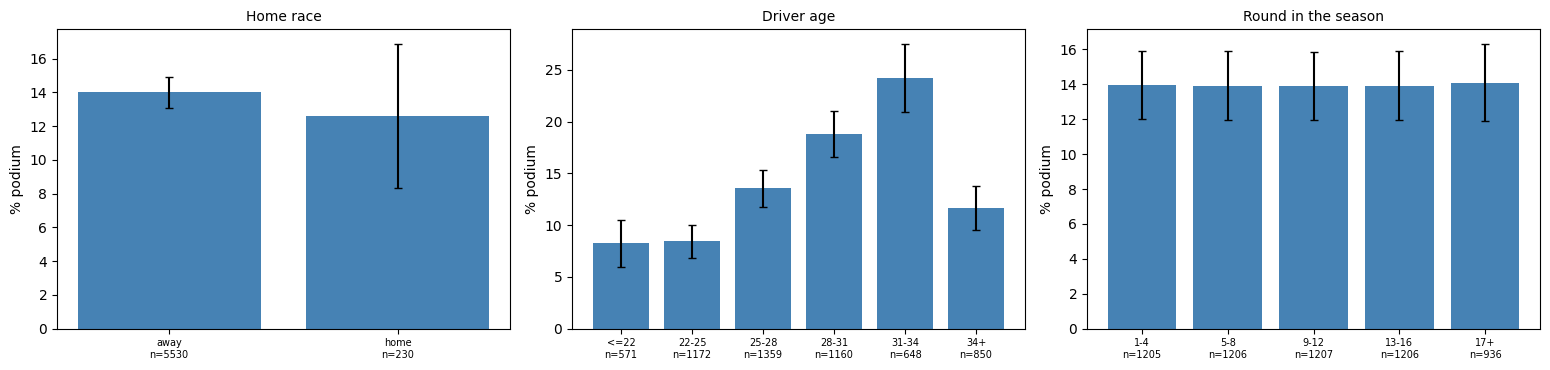

In [58]:
panels([
    ("is_home", [-0.5, 0.5, 1.5], ["away", "home"], "Home race"),
    ("driver_age", [0, 22, 25, 28, 31, 34, 60], ["<=22", "22-25", "25-28", "28-31", "31-34", "34+"], "Driver age"),
    ("round", [0, 4, 8, 12, 16, 30], ["1-4", "5-8", "9-12", "13-16", "17+"], "Round in the season"),
])

**Why the rank was recomputed.** The dataset’s constructor rank is frozen at 11 for McLaren 2007. The team was stripped of all its constructors’ points in the spy scandal (drivers kept theirs), so the dataset’s rank does not reflect on-track strength. The rank is recomputed from accumulated points before each race

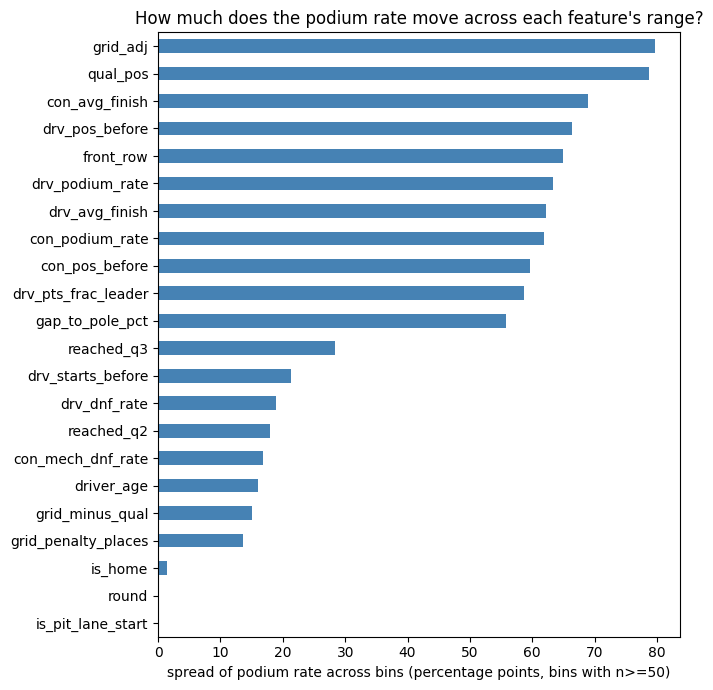

,spread_pp
grid_adj,79.7
qual_pos,78.7
con_avg_finish,69.0
drv_pos_before,66.3
front_row,65.0
drv_podium_rate,63.4
drv_avg_finish,62.2
con_podium_rate,61.8
con_pos_before,59.6
drv_pts_frac_leader,58.7


In [59]:
sig = pd.Series(SIGNAL).sort_values(ascending=False).round(1)
sig.plot(kind="barh", figsize=(7, 7), color="steelblue")
plt.gca().invert_yaxis()
plt.xlabel("spread of podium rate across bins (percentage points, bins with n>=50)")
plt.title("How much does the podium rate move across each feature's range?")
plt.tight_layout(); plt.show()
display(sig.to_frame("spread_pp"))

**Context and ranking**. round shows no relationship (flat at about 14%) and is_home shows no detectable effect (14% vs 12.5%, wide interval), consistent with Q2, so both are dropped. driver_age shows a non-linear pattern (peak at 31-34) and is kept as a candidate. The spread ranking is led by grid, qualifying, form and standings features; it is a rough guide that depends on bin choice, and much of it is redundant information, which the next step examines.

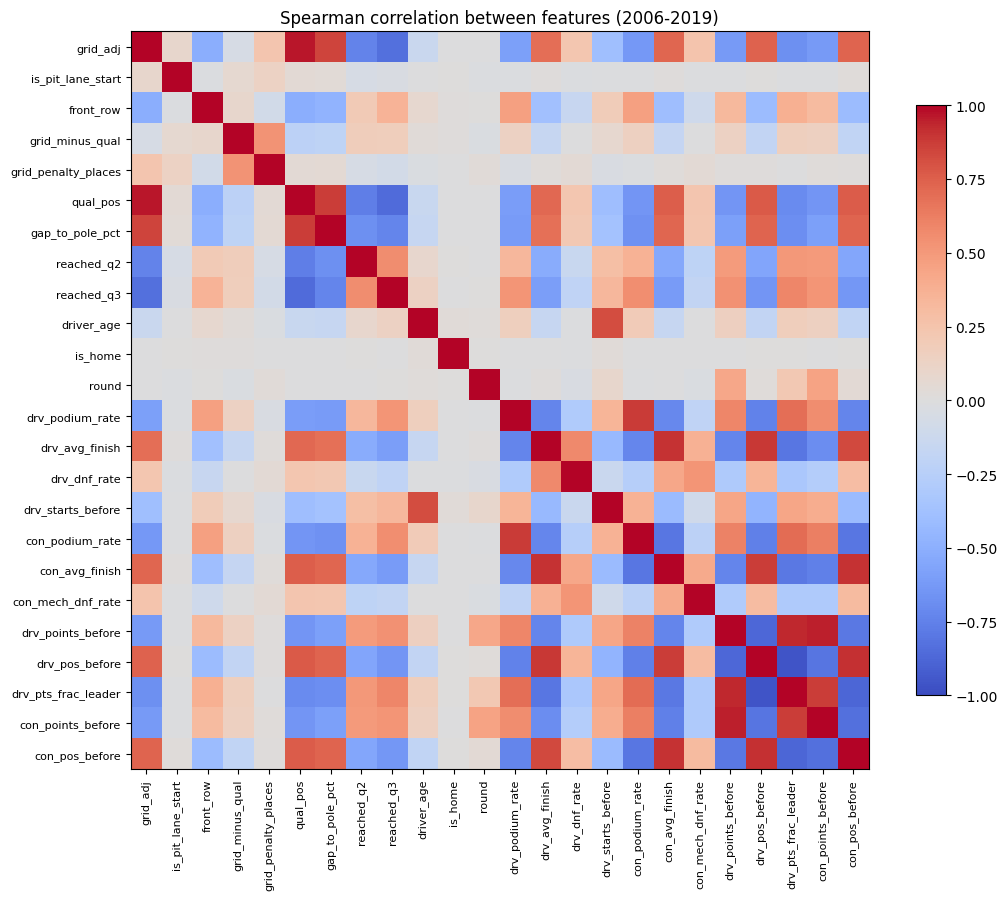

,feature_a,feature_b,rho
4,grid_adj,qual_pos,0.97
270,drv_pos_before,drv_pts_frac_leader,-0.96
268,drv_points_before,con_points_before,0.95
267,drv_points_before,drv_pts_frac_leader,0.93
272,drv_pos_before,con_pos_before,0.91
224,drv_avg_finish,con_avg_finish,0.90
260,con_avg_finish,con_pos_before,0.90
227,drv_avg_finish,drv_pos_before,0.88
213,drv_podium_rate,con_podium_rate,0.88
274,drv_pts_frac_leader,con_pos_before,-0.88


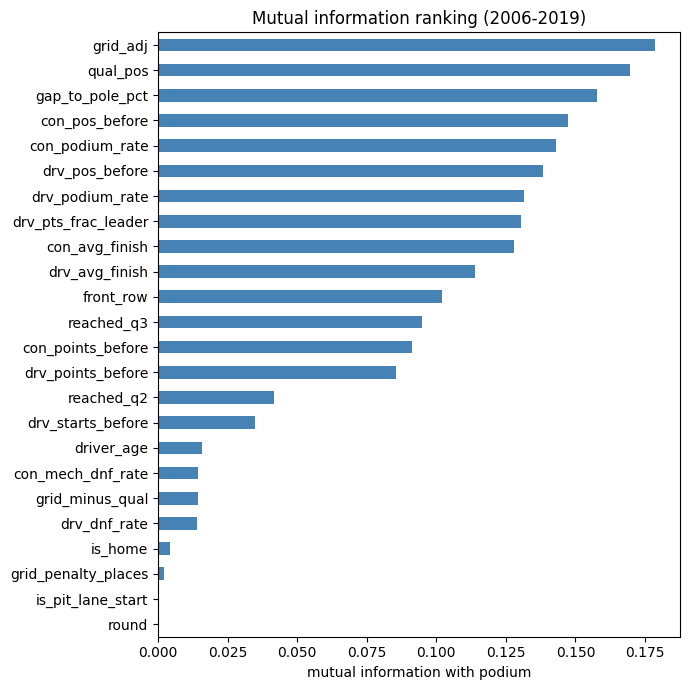

,mutual_info
grid_adj,0.179
qual_pos,0.170
gap_to_pole_pct,0.158
con_pos_before,0.147
con_podium_rate,0.143
drv_pos_before,0.138
drv_podium_rate,0.132
drv_pts_frac_leader,0.130
con_avg_finish,0.128
drv_avg_finish,0.114


In [60]:
from sklearn.feature_selection import mutual_info_classif

cand = sum(FEATURE_GROUPS.values(), [])
X = EV[cand].copy()

# 1) Collinearity: Spearman correlation between features (NaN ignored pairwise)
corr = X.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cand))); ax.set_xticklabels(cand, rotation=90, fontsize=8)
ax.set_yticks(range(len(cand))); ax.set_yticklabels(cand, fontsize=8)
plt.colorbar(im, shrink=0.8)
plt.title("Spearman correlation between features (2006-2019)")
plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index())
pairs.columns = ["feature_a", "feature_b", "rho"]
display(pairs[pairs["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False).round(2))

# 2) Mutual information with the target.
# Diagnostic only: NaN filled with the median HERE, not the modeling imputation (Section E).
Xf = X.fillna(X.median())
mi = pd.Series(mutual_info_classif(Xf, EV[TARGET], random_state=0), index=cand).sort_values(ascending=False)
mi.plot(kind="barh", figsize=(7, 7), color="steelblue"); plt.gca().invert_yaxis()
plt.xlabel("mutual information with podium"); plt.title("Mutual information ranking (2006-2019)")
plt.tight_layout(); plt.show()
display(mi.round(3).to_frame("mutual_info"))

**Collinearity and mutual information**. Several features duplicate each other: grid_adj and qual_pos (ρ = 0.97), the three driver standings features (drv_pos_before, drv_points_before, drv_pts_frac_leader, |ρ| 0.87-0.96), driver and constructor points (ρ = 0.95), and driver and constructor average finish (ρ = 0.90). Mutual information ranks grid, qualifying gap, form and standings features highest; round, is_home, is_pit_lane_start and grid_penalty_places are near zero and are candidates to drop. The constructor rank was recomputed from points before this analysis (see the fix after B4), and con_pos_before ranks fourth by mutual information (about 0.147); it is derived from con_points_before and is not an independent signal. Redundant features are tested in a controlled comparison rather than dropped by inspection.

# Section D: Split and feature-set / training-window experiments
**Split (chronological).** Train ≤ 2019, validation 2020-2021, test ≥ 2022. Random splits would train on future seasons to predict past ones; a season split mimics real forecasting and makes the test set an era-shift check (2022 ground-effect rules). Form and standings features may use earlier seasons' history: that is past information at prediction time. All preprocessing is fitted on the training rows only. Experiments below are scored on validation only; the test set is not used until the final model is chosen.

In [61]:
# Row counts and base rates per split (no model touches the test rows here)
split_tbl = []
for name, lo, hi in [("train (2006-2019)", 2006, 2019), ("train (all years, <=2019)", 1950, 2019),
                     ("validation (2020-21)", 2020, 2021), ("test (>=2022)", 2022, 2100)]:
    s = feat[feat["year"].between(lo, hi)]
    split_tbl.append({"split": name, "rows": len(s), "races": s["raceId"].nunique(),
                      "podium_rate_%": round(s[TARGET].mean() * 100, 1)})
display(pd.DataFrame(split_tbl))

def get_train_val(start_year):
    """Returns train and validation ONLY (the test set is deliberately unreachable here)."""
    tr = feat[(feat["year"] >= start_year) & (feat["year"] <= 2019)]
    va = feat[feat["year"].between(2020, 2021)]
    return tr, va

# Candidate feature sets (from the Section C evidence)
ALL = sum(FEATURE_GROUPS.values(), [])
WEAK = ["round", "is_home", "is_pit_lane_start", "grid_penalty_places"]       # flat plots, MI ~ 0
REDUNDANT = ["qual_pos", "drv_points_before", "drv_pts_frac_leader", "con_points_before"]  # near-copies
LOW_MI = ["driver_age", "con_mech_dnf_rate", "grid_minus_qual", "drv_dnf_rate"]            # MI < 0.02

SETS = {
    "baseline (grid_adj only)": ["grid_adj"],
    "full (24)": ALL,
    "pruned (no weak)": [f for f in ALL if f not in WEAK],
    "dedup (pruned, no near-copies)": [f for f in ALL if f not in WEAK + REDUNDANT],
    "core (dedup, no low-MI)": [f for f in ALL if f not in WEAK + REDUNDANT + LOW_MI],
}
assert all(f in feat.columns for s in SETS.values() for f in s)
print({k: len(v) for k, v in SETS.items()})

,split,rows,races,podium_rate_%
0,train (2006-2019),5760,268,14.0
1,"train (all years, <=2019)",22544,1007,13.5
2,validation (2020-21),779,39,15.0
3,test (>=2022),1354,68,15.1


{'baseline (grid_adj only)': 1, 'full (24)': 24, 'pruned (no weak)': 20, 'dedup (pruned, no near-copies)': 16, 'core (dedup, no low-MI)': 12}


,feature set,model,n_features,train_PR,val_PR,val_PR_lo,val_PR_hi,val_ROC
0,baseline (grid_adj only),LR,1,0.645,0.639,0.529,0.755,0.909
1,baseline (grid_adj only),GB,1,0.645,0.639,0.530,0.755,0.911
2,full (24),LR,24,0.714,0.735,0.621,0.840,0.935
3,full (24),GB,24,0.809,0.726,0.625,0.833,0.932
4,pruned (no weak),LR,20,0.714,0.745,0.637,0.844,0.934
5,pruned (no weak),GB,20,0.806,0.726,0.624,0.827,0.931
6,"dedup (pruned, no near-copies)",LR,16,0.715,0.739,0.622,0.837,0.935
7,"dedup (pruned, no near-copies)",GB,16,0.800,0.706,0.594,0.826,0.934
8,"core (dedup, no low-MI)",LR,12,0.712,0.730,0.613,0.835,0.929
9,"core (dedup, no low-MI)",GB,12,0.797,0.706,0.592,0.836,0.933


Train 5760 rows | validation 779 rows | validation podium rate 0.150 (a random model scores about this PR-AUC)


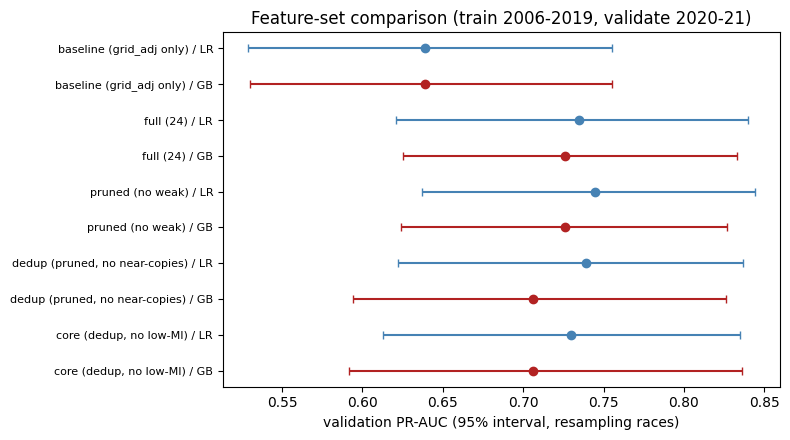

In [62]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

def make_model(kind):
    if kind == "LR":   # imputer + scaler are fitted on the training rows only (inside the pipeline)
        return make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                             StandardScaler(), LogisticRegression(max_iter=2000))
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0)

def boot_ci(va, p, n=300, seed=0):
    """95% interval for PR-AUC, resampling whole races (rows in a race are not independent)."""
    rng = np.random.default_rng(seed)
    y = va[TARGET].values
    idx = [np.where(va["raceId"].values == r)[0] for r in va["raceId"].unique()]
    vals = []
    for _ in range(n):
        take = np.concatenate([idx[i] for i in rng.integers(0, len(idx), len(idx))])
        if y[take].sum() > 0:
            vals.append(average_precision_score(y[take], p[take]))
    return np.percentile(vals, [2.5, 97.5])

def run(features, kind, start_year=2006):
    tr, va = get_train_val(start_year)
    m = make_model(kind).fit(tr[features], tr[TARGET])
    p_tr, p_va = m.predict_proba(tr[features])[:, 1], m.predict_proba(va[features])[:, 1]
    lo, hi = boot_ci(va, p_va)
    return {"train_PR": average_precision_score(tr[TARGET], p_tr),
            "val_PR": average_precision_score(va[TARGET], p_va), "val_PR_lo": lo, "val_PR_hi": hi,
            "val_ROC": roc_auc_score(va[TARGET], p_va)}

rows = []
for set_name, feats in SETS.items():
    for kind in ["LR", "GB"]:
        rows.append({"feature set": set_name, "model": kind, "n_features": len(feats), **run(feats, kind)})
res_sets = pd.DataFrame(rows).round(3)
display(res_sets)

tr_, va_ = get_train_val(2006)
print(f"Train {len(tr_)} rows | validation {len(va_)} rows | validation podium rate {va_[TARGET].mean():.3f} (a random model scores about this PR-AUC)")

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, r in res_sets.iterrows():
    ax.errorbar(r["val_PR"], i, xerr=[[r["val_PR"] - r["val_PR_lo"]], [r["val_PR_hi"] - r["val_PR"]]],
                fmt="o", color="firebrick" if r["model"] == "GB" else "steelblue", capsize=3)
ax.set_yticks(range(len(res_sets)))
ax.set_yticklabels(res_sets["feature set"] + " / " + res_sets["model"], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("validation PR-AUC (95% interval, resampling races)")
ax.set_title("Feature-set comparison (train 2006-2019, validate 2020-21)")
plt.tight_layout(); plt.show()

**Feature-set comparison (validation 2020-21, train 2006-2019).** All richer feature sets outperform the grid-only baseline (PR-AUC 0.71-0.75 vs 0.64; ROC-AUC 0.93-0.94 vs 0.91). Differences among the richer sets (0.706-0.745) are far smaller than the bootstrap intervals (about ±0.1, from only 39 validation races), so validation cannot rank them. Logistic regression matches or exceeds gradient boosting in every set, and gradient boosting overfits more (train PR-AUC about 0.80 vs about 0.71-0.73 on validation). We carry the 16-feature “dedup” set forward: it is within noise of the best set, removes near-duplicate features that would split credit in the explanation plots, and keeps all six feature groups for the ablation experiment.

In [63]:
def paired_diff(feats_a, feats_b, kind="LR", start_year=2006, n=500, seed=0):
    """PR-AUC(a) - PR-AUC(b) on validation, resampling the same races for both."""
    tr, va = get_train_val(start_year)
    pa = make_model(kind).fit(tr[feats_a], tr[TARGET]).predict_proba(va[feats_a])[:, 1]
    pb = make_model(kind).fit(tr[feats_b], tr[TARGET]).predict_proba(va[feats_b])[:, 1]
    y = va[TARGET].values
    idx = [np.where(va["raceId"].values == r)[0] for r in va["raceId"].unique()]
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n):
        take = np.concatenate([idx[i] for i in rng.integers(0, len(idx), len(idx))])
        if y[take].sum() > 0:
            d.append(average_precision_score(y[take], pa[take]) - average_precision_score(y[take], pb[take]))
    d = np.array(d)
    return {"diff": average_precision_score(y, pa) - average_precision_score(y, pb),
            "ci_lo": np.percentile(d, 2.5), "ci_hi": np.percentile(d, 97.5)}

pairs = [("full (24)", "baseline (grid_adj only)"),
         ("pruned (no weak)", "baseline (grid_adj only)"),
         ("dedup (pruned, no near-copies)", "baseline (grid_adj only)"),
         ("pruned (no weak)", "full (24)"),
         ("dedup (pruned, no near-copies)", "pruned (no weak)"),
         ("core (dedup, no low-MI)", "dedup (pruned, no near-copies)")]
rows = []
for a, b in pairs:
    for kind in ["LR", "GB"]:
        rows.append({"A": a, "B": b, "model": kind, **paired_diff(SETS[a], SETS[b], kind)})
display(pd.DataFrame(rows).round(3))

,A,B,model,diff,ci_lo,ci_hi
0,full (24),baseline (grid_adj only),LR,0.097,0.045,0.152
1,full (24),baseline (grid_adj only),GB,0.087,0.038,0.131
2,pruned (no weak),baseline (grid_adj only),LR,0.106,0.056,0.154
3,pruned (no weak),baseline (grid_adj only),GB,0.087,0.044,0.128
4,"dedup (pruned, no near-copies)",baseline (grid_adj only),LR,0.100,0.049,0.145
5,"dedup (pruned, no near-copies)",baseline (grid_adj only),GB,0.067,0.019,0.123
6,pruned (no weak),full (24),LR,0.009,-0.002,0.024
7,pruned (no weak),full (24),GB,0.000,-0.012,0.013
8,"dedup (pruned, no near-copies)",pruned (no weak),LR,-0.006,-0.021,0.008
9,"dedup (pruned, no near-copies)",pruned (no weak),GB,-0.020,-0.046,0.011


**Paired comparison (same validation races resampled for both models).** Every richer feature set beats grid-only reliably: PR-AUC gains of +0.07 to +0.11, with all six 95% intervals above zero (e.g. full vs baseline, logistic regression: +0.097, interval 0.045-0.152). Pruning has no detectable cost: pruned vs full, dedup vs pruned and core vs dedup all have intervals containing zero (|difference| ≤ 0.02 for logistic regression). Gradient boosting shows a small, non-significant drop when the near-copies are removed (-0.020, interval -0.046 to +0.011). Because validation has only 39 races, these intervals cannot rule out losses of 0.02-0.04, so we describe the pruned sets as “no detectable loss”. We continue with the 16-feature dedup set.

In [64]:
FEATS = SETS["dedup (pruned, no near-copies)"]     # change after reading D1

rows = []
for start in [1950, 1994, 2003, 2006]:
    tr, va = get_train_val(start)
    for kind in ["LR", "GB"]:
        rows.append({"window": f"{start}-2019", "model": kind, "train_rows": len(tr),
                     "train_podium_%": round(tr[TARGET].mean() * 100, 1), **run(FEATS, kind, start_year=start)})
res_win = pd.DataFrame(rows).round(3)
display(res_win)

,window,model,train_rows,train_podium_%,train_PR,val_PR,val_PR_lo,val_PR_hi,val_ROC
0,1950-2019,LR,22544,13.5,0.576,0.723,0.606,0.835,0.933
1,1950-2019,GB,22544,13.5,0.600,0.700,0.591,0.832,0.929
2,1994-2019,LR,10137,13.9,0.661,0.724,0.606,0.841,0.934
3,1994-2019,GB,10137,13.9,0.720,0.708,0.589,0.837,0.931
4,2003-2019,LR,6802,14.2,0.701,0.735,0.621,0.836,0.934
5,2003-2019,GB,6802,14.2,0.779,0.693,0.572,0.809,0.929
6,2006-2019,LR,5760,14.0,0.715,0.739,0.622,0.837,0.935
7,2006-2019,GB,5760,14.0,0.800,0.706,0.594,0.826,0.934


**Training-window comparison (dedup features, validation 2020-21).** Validation PR-AUC is essentially flat across windows: logistic regression 0.723 (1950+), 0.724 (1994+), 0.735 (2003+), 0.739 (2006+); gradient boosting 0.693-0.708. The differences (≤ 0.04) are far inside the bootstrap intervals (about ±0.11), so four times more training data (1950+) brings no measurable gain, while training PR-AUC drops for the older windows (LR 0.576 for 1950+ vs 0.715 for 2006+), consistent with qualifying features being absent and grid-to-podium conversion being weaker in earlier eras. We train on 2006-2019: it has complete, consistently defined qualifying data, matches the modern era of the validation and test years, and is the window on which the features were selected.

**Sprint results.** Sprint races exist only from 2021 onward. Because the training window ends in 2019, a sprint-based feature would be missing for all training rows and cannot be learned. Sprint results are technically pre-race for the Sunday race (a valid cutoff), but they are excluded as a feature for this reason; for 2021-22 weekends the sprint result already influences the Sunday grid (grid_adj), so the effect is partly captured.

# Section E: Preprocessing
All preprocessing is fitted on the training rows (2006-2019) only and then applied to validation (and, at the very end, to test). Features: the 16-feature "dedup" set chosen in Section D.

16 features | train (5760, 16) | validation (779, 16)


,train_%,val_%
drv_pos_before,6.6,5.6
con_pos_before,5.1,5.1
gap_to_pole_pct,1.3,1.2
drv_podium_rate,1.0,0.8
drv_dnf_rate,1.0,0.8
drv_avg_finish,1.0,0.8
con_mech_dnf_rate,0.6,0.5
con_podium_rate,0.6,0.5
con_avg_finish,0.6,0.5
reached_q3,0.4,0.1


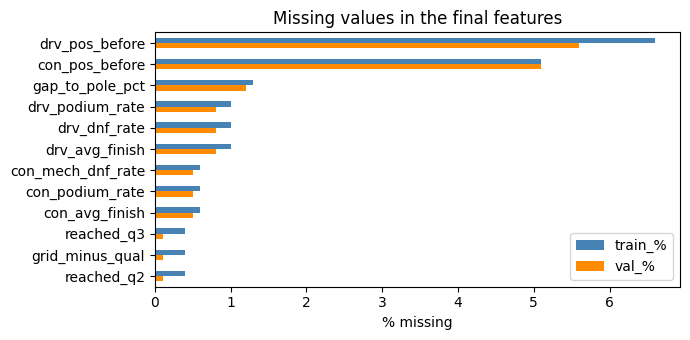

,min,25%,50%,75%,max,std
grid_adj,1.00,6.00,11.00,17.00,24.00,6.31
front_row,0.00,0.00,0.00,0.00,1.00,0.29
grid_minus_qual,-7.00,0.00,0.00,0.00,23.00,1.62
gap_to_pole_pct,0.00,0.86,1.83,3.06,37.80,2.60
reached_q2,0.00,0.00,1.00,1.00,1.00,0.45
reached_q3,0.00,0.00,0.00,1.00,1.00,0.50
driver_age,17.45,24.17,27.46,31.19,43.89,5.00
drv_podium_rate,0.00,0.00,0.00,0.20,1.00,0.25
drv_avg_finish,1.00,7.80,11.60,14.80,24.00,4.62
drv_dnf_rate,0.00,0.00,0.20,0.40,1.00,0.21


In [65]:
FEATS = SETS["dedup (pruned, no near-copies)"]          # 16 features
tr, va = get_train_val(2006)
Xtr, ytr, Xva, yva = tr[FEATS], tr[TARGET], va[FEATS], va[TARGET]
print(len(FEATS), "features | train", Xtr.shape, "| validation", Xva.shape)

miss = pd.DataFrame({"train_%": Xtr.isna().mean() * 100, "val_%": Xva.isna().mean() * 100}).round(1)
miss = miss[(miss > 0).any(axis=1)].sort_values("train_%", ascending=False)
display(miss)
ax = miss.plot(kind="barh", figsize=(7, 3.5), color=["steelblue", "darkorange"])
ax.invert_yaxis(); ax.set_xlabel("% missing"); ax.set_title("Missing values in the final features")
plt.tight_layout(); plt.show()

display(Xtr.describe().T[["min", "25%", "50%", "75%", "max", "std"]].round(2))

**Missing values.** Missingness is structural: standings ranks are missing in round 1 (con_pos_before 5.1% of rows, drv_pos_before 6.6%), form features for a driver’s or team’s first race (about 1%), and gap_to_pole_pct where a qualifying position has no lap time (1.3%). Missing values are filled with the training median and a “was missing” indicator is added so the model can tell filled values from real ones. Gradient boosting receives the unfilled features and handles NaN natively.

In [66]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

class Winsor(BaseEstimator, TransformerMixin):
    """Clip each column to [lo, hi] quantiles learned on the data passed to fit (NaN-safe)."""
    def __init__(self, lo=0.005, hi=0.995):
        self.lo, self.hi = lo, hi
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_, self.hi_ = np.nanquantile(X, self.lo, axis=0), np.nanquantile(X, self.hi, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)

def P(order):
    """W = winsorize, I = median-impute (+indicator), S = standardize. Letters give the order."""
    make = {"W": lambda: Winsor(),
            "I": lambda: SimpleImputer(strategy="median", add_indicator=True),
            "S": lambda: StandardScaler()}
    return Pipeline([(c, make[c]()) for c in order])

def val_probs(order, fit_on="train"):
    pre = P(order)
    pre.fit(Xtr if fit_on == "train" else pd.concat([Xtr, Xva]))
    clf = LogisticRegression(max_iter=2000).fit(pre.transform(Xtr), ytr)
    return clf.predict_proba(pre.transform(Xva))[:, 1]

def pr_diff(pa, pb, n=500, seed=0):
    """PR-AUC(a) - PR-AUC(b) on validation, resampling the same races for both."""
    y, races = yva.values, va["raceId"].values
    idx = [np.where(races == r)[0] for r in np.unique(races)]
    rng, d = np.random.default_rng(seed), []
    for _ in range(n):
        take = np.concatenate([idx[i] for i in rng.integers(0, len(idx), len(idx))])
        if y[take].sum() > 0:
            d.append(average_precision_score(y[take], pa[take]) - average_precision_score(y[take], pb[take]))
    return average_precision_score(y, pa) - average_precision_score(y, pb), *np.percentile(d, [2.5, 97.5])

ORDERS = {"P1 winsor → impute → scale": "WIS",
          "P2 winsor → scale → impute": "WSI",
          "P3 scale → winsor → impute": "SWI"}
probs = {name: val_probs(o) for name, o in ORDERS.items()}
leaky = val_probs("WIS", fit_on="train+val")        # preprocessing statistics also see validation rows

rows = []
for name, p in probs.items():
    d, lo, hi = pr_diff(p, probs["P1 winsor → impute → scale"])
    rows.append({"pipeline": name, "val_PR": average_precision_score(yva, p),
                 "val_ROC": roc_auc_score(yva, p), "diff_vs_P1": d, "ci_lo": lo, "ci_hi": hi})
d, lo, hi = pr_diff(leaky, probs["P1 winsor → impute → scale"])
rows.append({"pipeline": "P1 but fitted on train + validation (leaky)", "val_PR": average_precision_score(yva, leaky),
             "val_ROC": roc_auc_score(yva, leaky), "diff_vs_P1": d, "ci_lo": lo, "ci_hi": hi})
display(pd.DataFrame(rows).round(4))

,pipeline,val_PR,val_ROC,diff_vs_P1,ci_lo,ci_hi
0,P1 winsor → impute → scale,0.7370,0.9332,0.0000,0.0000,0.0000
1,P2 winsor → scale → impute,0.7363,0.9329,-0.0007,-0.0020,0.0009
2,P3 scale → winsor → impute,0.7370,0.9330,-0.0001,-0.0014,0.0014
3,P1 but fitted on train + validation (leaky),0.7374,0.9333,0.0004,-0.0004,0.0016


In [67]:
  p0 = val_probs("IS")     # impute → scale, no clipping
  d, lo, hi = pr_diff(p0, probs["P1 winsor → impute → scale"])
  print("no clipping minus P1:", round(d, 4), "| interval", round(lo, 4), "to", round(hi, 4))

no clipping minus P1: 0.002 | interval -0.0031 to 0.0082


**Preprocessing-order experiments (validation PR-AUC, logistic regression, paired bootstrap over races)**.Pipeline P1 (clip, impute, scale) scores 0.7370. (A) Imputing last instead of between clipping and scaling (P2): -0.0007 (95% interval -0.0020 to 0.0009). (B) Scaling before clipping (P3): -0.0001 (-0.0014 to 0.0014). (C) Fitting the preprocessing on train + validation instead of train only: +0.0004 (-0.0004 to 0.0016). None of the differences is distinguishable from zero. Clipping, median imputation and standardization are monotone or affine, so their order changes statistics only slightly, and the leaky fit shares only feature-level summary statistics (never labels) over 779 additional rows. We keep P1 fitted on training rows only, as a leakage-prevention rule: the same mistake with label-dependent steps such as target encoding would be costly.

Winsor bounds for gap_to_pole_pct: 0.0 to 17.64
Train mean after scaling (should be ~0): 0.0 | validation mean after scaling (not exactly 0, uses train statistics): 0.335


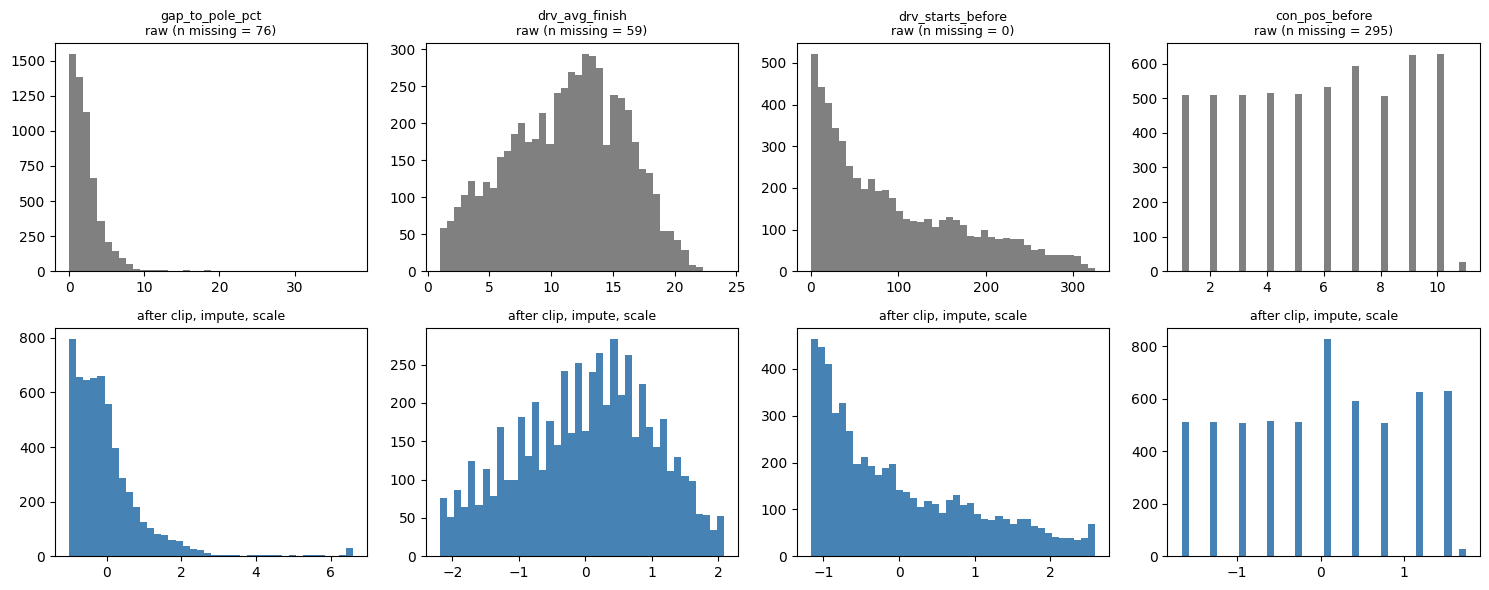

,raw_min,raw_max,scaled_min,scaled_max
gap_to_pole_pct,0.0,37.8,-1.01,6.60
drv_avg_finish,1.0,24.0,-2.19,2.08
drv_starts_before,0.0,325.0,-1.17,2.59
con_pos_before,1.0,11.0,-1.67,1.74


In [68]:
pre = P("WIS").fit(Xtr)
Z = pre.transform(Xtr)[:, :len(FEATS)]          # the first 16 columns are the features; indicators follow
Zdf = pd.DataFrame(Z, columns=FEATS, index=Xtr.index)
Zva = pd.DataFrame(pre.transform(Xva)[:, :len(FEATS)], columns=FEATS, index=Xva.index)
assert not np.isnan(pre.transform(Xva)).any()

gi = FEATS.index("gap_to_pole_pct")
print("Winsor bounds for gap_to_pole_pct:",
      round(float(pre.named_steps["W"].lo_[gi]), 2), "to", round(float(pre.named_steps["W"].hi_[gi]), 2))
print("Train mean after scaling (should be ~0):", round(float(Zdf.mean().abs().max()), 3),
      "| validation mean after scaling (not exactly 0, uses train statistics):",
      round(float(Zva.mean().abs().max()), 3))

show = ["gap_to_pole_pct", "drv_avg_finish", "drv_starts_before", "con_pos_before"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, f in enumerate(show):
    axes[0, j].hist(Xtr[f].dropna(), bins=40, color="gray")
    axes[0, j].set_title(f"{f}\nraw (n missing = {int(Xtr[f].isna().sum())})", fontsize=9)
    axes[1, j].hist(Zdf[f], bins=40, color="steelblue")
    axes[1, j].set_title("after clip, impute, scale", fontsize=9)
plt.tight_layout(); plt.show()

cmp_ = pd.DataFrame({"raw_min": Xtr[show].min(), "raw_max": Xtr[show].max(),
                     "scaled_min": Zdf[show].min(), "scaled_max": Zdf[show].max()}).round(2)
display(cmp_)

In [69]:
  display(Zva.mean().round(2).sort_values().to_frame("val_mean_in_train_std_units"))

,val_mean_in_train_std_units
drv_dnf_rate,-0.34
con_mech_dnf_rate,-0.31
con_avg_finish,-0.17
drv_avg_finish,-0.16
gap_to_pole_pct,-0.15
grid_adj,-0.12
drv_pos_before,-0.11
con_pos_before,-0.10
driver_age,-0.04
front_row,0.02


**Effect on the data.** Clipping at the 0.5/99.5 training percentiles trims gap_to_pole_pct from a maximum of 37.8 to 17.64; after standardizing, its range is -1.01 to 6.60 and it remains right-skewed. Standardizing puts every feature on a comparable scale (training mean 0, std 1); validation, transformed with training statistics, has a mean up to 0.34 standard deviations away from zero. Median imputation creates a visible spike in con_pos_before (295 filled rows).

**Categorical features.** Circuit and constructor identity are not encoded. Circuits number about 25 with few rows each, so one-hot columns would be sparse, and target encoding adds leakage risk; new circuits appear in the test years (unseen categories); and the constructor’s competitiveness is already captured by constructor form and standings. Driver identity is excluded for the same reason (form and standings capture it, and driver and team move between seasons).

# Handoff: final modeling inputs
Defines the final feature set, the chronological split, and the preprocessing pipeline fitted on training rows only. Whoever builds the models uses `X_train / X_val / X_test` (preprocessed, for logistic regression and the neural network) or `R_train / R_val / R_test` (raw, NaN kept, for gradient boosting). The test rows are only transformed here, never scored. `GROUP_COLS` maps each feature group to its processed columns, for the ablation.

In [70]:
# ---- Final feature set and groups ----
FINAL_FEATS = SETS["dedup (pruned, no near-copies)"]
FINAL_GROUPS = {g: [f for f in cols if f in FINAL_FEATS] for g, cols in FEATURE_GROUPS.items()}
FINAL_GROUPS = {g: c for g, c in FINAL_GROUPS.items() if c}
assert sorted(sum(FINAL_GROUPS.values(), [])) == sorted(FINAL_FEATS)

# ---- Chronological split ----
SPLITS = {"train": (2006, 2019), "validation": (2020, 2021), "test": (2022, 2100)}
feat["split"] = "pre_2006_history"          # used only as history for form/standings features
for name, (lo, hi) in SPLITS.items():
    feat.loc[feat["year"].between(lo, hi), "split"] = name

tr, va, te = (feat[feat["split"] == s] for s in ["train", "validation", "test"])
assert tr["year"].max() < va["year"].min() and va["year"].max() < te["year"].min()
assert not (set(tr["raceId"]) & set(va["raceId"])) and not (set(va["raceId"]) & set(te["raceId"]))
assert not feat.duplicated(["raceId", "driverId"]).any()

# ---- Preprocessing: fitted on TRAIN rows only (clip -> median-impute + indicator -> standardize) ----
prep = P("WIS").fit(tr[FINAL_FEATS])
ind = [f"{FINAL_FEATS[i]}_was_missing" for i in prep.named_steps["I"].indicator_.features_]
COLS = FINAL_FEATS + ind

def transform(frame):
    return pd.DataFrame(prep.transform(frame[FINAL_FEATS]), columns=COLS, index=frame.index)

X_train, X_val, X_test = transform(tr), transform(va), transform(te)     # test is only transformed
y_train, y_val, y_test = tr[TARGET], va[TARGET], te[TARGET]
R_train, R_val, R_test = tr[FINAL_FEATS], va[FINAL_FEATS], te[FINAL_FEATS]  # raw, NaN kept (for gradient boosting)
META = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date"]
meta_train, meta_val, meta_test = tr[META], va[META], te[META]

# ---- Group -> processed columns (features + their missing indicators), for the ablation ----
GROUP_COLS = {g: [c for c in COLS if c in cols or c.replace("_was_missing", "") in cols]
              for g, cols in FINAL_GROUPS.items()}

# ---- Checks ----
for name, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    assert list(X.columns) == COLS and not X.isna().any().any(), f"problem in {name}"
FORBIDDEN = {"points", "position", "positionText", "positionOrder", "statusId", "status", "category",
             "laps", "time", "milliseconds", "fastestLap", "fastestLapTime", "fastestLapSpeed", "rank"}
assert not (set(FINAL_FEATS) & FORBIDDEN) and TARGET not in FINAL_FEATS

summary = pd.DataFrame([{"split": s, "years": f"{f['year'].min()}-{f['year'].max()}", "rows": len(f),
                         "races": f["raceId"].nunique(), "podium_rate_%": round(f[TARGET].mean() * 100, 1)}
                        for s, f in [("train", tr), ("validation", va), ("test", te)]])
display(summary)
print("final features:", len(FINAL_FEATS), "| processed columns (with missing indicators):", len(COLS))
print({g: len(c) for g, c in GROUP_COLS.items()})
print("train mean/std after scaling:", round(float(X_train[FINAL_FEATS].mean().abs().max()), 3),
      "/", round(float(X_train[FINAL_FEATS].std().mean()), 3))

,split,years,rows,races,podium_rate_%
0,train,2006-2019,5760,268,14.0
1,validation,2020-2021,779,39,15.0
2,test,2022-2024,1354,68,15.1


final features: 16 | processed columns (with missing indicators): 28
{'grid': 4, 'qualifying': 6, 'context': 1, 'driver_form': 7, 'constructor_form': 6, 'standings': 4}
train mean/std after scaling: 0.0 / 1.0


In [71]:
import json, joblib, os

OUT = "/kaggle/working"
os.makedirs(OUT, exist_ok=True)

ALL_CANDIDATES = sum(FEATURE_GROUPS.values(), [])
table = feat[META + [TARGET, "split"] + ALL_CANDIDATES]
table.to_csv(f"{OUT}/modeling_table.csv", index=False)

with open(f"{OUT}/feature_config.json", "w") as f:
    json.dump({"target": TARGET, "splits": SPLITS,
               "final_features": FINAL_FEATS, "final_groups": FINAL_GROUPS,
               "all_candidate_groups": FEATURE_GROUPS,
               "preprocessing": "clip at train 0.5/99.5 percentiles -> median impute + missing indicator -> standardize; fitted on train 2006-2019 only"},
              f, indent=2)
joblib.dump(prep, f"{OUT}/preprocessing_pipeline.joblib")

# Verify the saved table
chk = pd.read_csv(f"{OUT}/modeling_table.csv", parse_dates=["date"])
assert len(chk) == len(feat) and not chk.duplicated(["raceId", "driverId"]).any()
print("modeling_table.csv:", chk.shape, "| splits:", chk["split"].value_counts().to_dict())
for fn in sorted(os.listdir(OUT)):
    print(f"{fn:32s} {os.path.getsize(os.path.join(OUT, fn)) / 1024:8.0f} KB")

modeling_table.csv: (24677, 33) | splits: {'pre_2006_history': 16784, 'train': 5760, 'test': 1354, 'validation': 779}
.virtual_documents                      4 KB
feature_config.json                     2 KB
modeling_table.csv                   3813 KB
preprocessing_pipeline.joblib           2 KB


**About pre_2006_history.** Rows before 2006 stay in the table because form and standings features for 2006+ rows are computed from earlier races (windows span seasons). They are labelled pre_2006_history and are never used for training, validation or testing.

# Requirement 4: Predictive Modeling
All models use the same rows (train 2006-2019, validation 2020-21, test 2022-24) and the same 16 features from the handoff cell.
Hyperparameters and thresholds are chosen on validation only; the test set is scored once at the end.
Primary metric: PR-AUC (podiums are rare, ~15% of rows). Secondary: ROC-AUC. Also reported: F1, precision, recall.

In [72]:
# =====  imports and reproducibility =====
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             f1_score, precision_score, recall_score)

SEED = 42
np.random.seed(SEED)

In [73]:
def evaluate(model_name, split, y_true, p, threshold):
    """Compute the 5 metrics for ONE model on ONE split.
    y_true    : the real answers (0/1)
    p         : the model's predicted probabilities of podium (0..1)
    threshold : probability cut-off to turn p into yes/no (needed for F1, precision, recall)"""
    y_pred = (p >= threshold).astype(int)        # probability -> 0/1 decision
    return {"model": model_name,
            "split": split,
            "threshold": round(float(threshold), 2),
            "ROC_AUC":  roc_auc_score(y_true, p),             # ranking quality, no threshold
            "PR_AUC":   average_precision_score(y_true, p),   # rare-class ranking, no threshold
            "F1":       f1_score(y_true, y_pred, zero_division=0),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall":   recall_score(y_true, y_pred, zero_division=0)}

In [74]:
def pick_threshold(y_true, p):
    """Try thresholds 0.05, 0.06, ..., 0.95 and return the one with the highest F1.
    RULE: only ever call this with VALIDATION data (never test)."""
    candidates = np.round(np.arange(0.05, 0.96, 0.01), 2)
    f1s = [f1_score(y_true, (p >= t).astype(int), zero_division=0) for t in candidates]
    return float(candidates[int(np.argmax(f1s))])

In [75]:
RESULTS = []    # one dict per (model, split); becomes the comparison table in Step 5

def add_results(model_name, p_train, p_val):
    """1) choose the threshold on VALIDATION, 2) score train + validation with that SAME threshold,
    3) store both rows in RESULTS (replacing old rows of the same model if the cell is re-run)."""
    RESULTS[:] = [r for r in RESULTS if r["model"] != model_name]   # remove old rows of this model
    thr = pick_threshold(y_val, p_val)
    RESULTS.append(evaluate(model_name, "train", y_train, p_train, thr))
    RESULTS.append(evaluate(model_name, "validation", y_val, p_val, thr))
    return thr

FINAL_MODELS = {}   # name -> what we need to score it on TEST later (Step 6)

In [76]:
# Sanity check: test the tools on two "fake" models where we already know the answer
rng = np.random.default_rng(SEED)
p_random  = rng.random(len(y_val))          # random probabilities: knows nothing
p_perfect = y_val.values.astype(float)       # copies the answer: perfect (cheating, just for testing)

check = pd.DataFrame([evaluate("random guessing", "validation", y_val, p_random, 0.5),
                      evaluate("perfect (cheating)", "validation", y_val, p_perfect, 0.5)]).round(3)
display(check)
print("Validation podium rate:", round(y_val.mean(), 3), "→ a random model's PR-AUC should be close to this")

,model,split,threshold,ROC_AUC,PR_AUC,F1,precision,recall
0,random guessing,validation,0.5,0.566,0.178,0.254,0.166,0.547
1,perfect (cheating),validation,0.5,1.000,1.000,1.000,1.000,1.000


Validation podium rate: 0.15 → a random model's PR-AUC should be close to this


## Step 1 – Baseline: logistic regression on grid position only
The simplest reasonable model: the starting slot alone. Every later model must beat it on validation PR-AUC to justify its extra features and complexity.

In [77]:
# ===== Step 1: Baseline =====
BASE_COLS = ["grid_adj"]                                   # the ONLY feature

baseline = LogisticRegression(max_iter=2000, random_state=SEED)
baseline.fit(X_train[BASE_COLS], y_train)                  # learn from TRAIN only

p_tr_base = baseline.predict_proba(X_train[BASE_COLS])[:, 1]   # probabilities on train
p_va_base = baseline.predict_proba(X_val[BASE_COLS])[:, 1]     # probabilities on validation

thr_base = add_results("Baseline: LR (grid only)", p_tr_base, p_va_base)
FINAL_MODELS["Baseline: LR (grid only)"] = {"model": baseline, "cols": BASE_COLS,
                                            "data": "X", "thr": thr_base}

print("Weight (coefficient) for grid_adj:", round(baseline.coef_[0][0], 3),
      "| intercept:", round(baseline.intercept_[0], 3))
print("Threshold chosen on validation:", thr_base)
display(pd.DataFrame(RESULTS).round(3))

Weight (coefficient) for grid_adj: -2.91 | intercept: -3.891
Threshold chosen on validation: 0.38


,model,split,threshold,ROC_AUC,PR_AUC,F1,precision,recall
0,Baseline: LR (grid only),train,0.38,0.918,0.645,0.662,0.663,0.662
1,Baseline: LR (grid only),validation,0.38,0.909,0.639,0.692,0.692,0.692


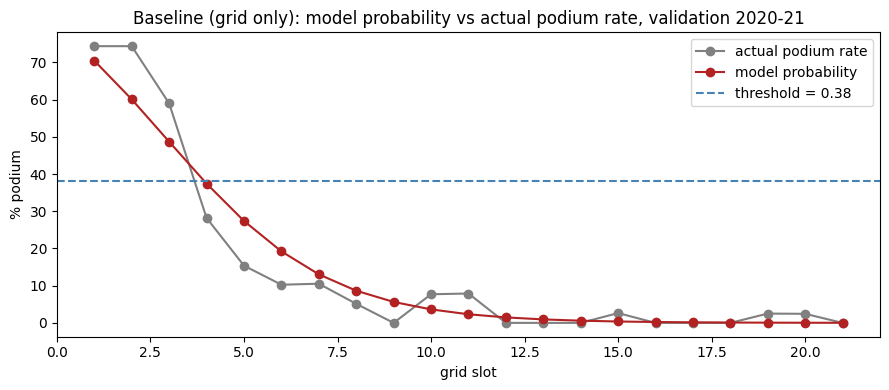

In [78]:
# Does the model's probability match reality, per grid slot? (validation)
chk = pd.DataFrame({"grid": R_val["grid_adj"].values,          # raw slot (1, 2, 3...), easier to read
                    "actual podium rate": y_val.values,
                    "model probability": p_va_base})
by_grid = chk.groupby("grid")[["actual podium rate", "model probability"]].mean() * 100

ax = by_grid.plot(marker="o", figsize=(9, 4), color=["gray", "firebrick"])
ax.axhline(thr_base * 100, linestyle="--", color="steelblue", label=f"threshold = {thr_base}")
ax.set_xlabel("grid slot"); ax.set_ylabel("% podium")
ax.set_title("Baseline (grid only): model probability vs actual podium rate, validation 2020-21")
ax.legend(); plt.tight_layout(); plt.show()

## Step 2 – Logistic regression on all features (+ tuning C)
Same model type as the baseline, but with all 16 selected features (+ their 12 "was missing" flags = 28 columns).
C controls regularization (small C = strong penalty on large weights = simpler model). We try 6 values of C and keep the one with the best validation PR-AUC.

,C,train_PR_AUC,val_PR_AUC,val_ROC_AUC
0,0.001,0.679,0.688,0.919
1,0.010,0.697,0.703,0.927
2,0.100,0.711,0.731,0.933
3,1.000,0.715,0.737,0.933
4,10.000,0.715,0.736,0.933
5,100.000,0.715,0.736,0.933


Best C (chosen on validation): 1.0


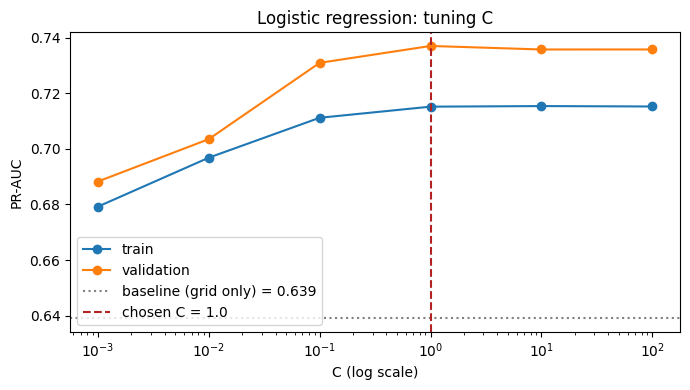

In [79]:
# ===== Step 2a: tune C on validation =====
C_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]
tuning = []
for C in C_VALUES:
    m = LogisticRegression(C=C, max_iter=5000, random_state=SEED).fit(X_train[COLS], y_train)
    tuning.append({"C": C,
                   "train_PR_AUC": average_precision_score(y_train, m.predict_proba(X_train[COLS])[:, 1]),
                   "val_PR_AUC":   average_precision_score(y_val,   m.predict_proba(X_val[COLS])[:, 1]),
                   "val_ROC_AUC":  roc_auc_score(y_val,             m.predict_proba(X_val[COLS])[:, 1])})
tuning_lr = pd.DataFrame(tuning)
display(tuning_lr.round(3))

BEST_C = tuning_lr.loc[tuning_lr["val_PR_AUC"].idxmax(), "C"]
print("Best C (chosen on validation):", BEST_C)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tuning_lr["C"], tuning_lr["train_PR_AUC"], marker="o", label="train")
ax.plot(tuning_lr["C"], tuning_lr["val_PR_AUC"], marker="o", label="validation")
ax.axhline(0.639, linestyle=":", color="gray", label="baseline (grid only) = 0.639")
ax.axvline(BEST_C, linestyle="--", color="firebrick", label=f"chosen C = {BEST_C}")
ax.set_xscale("log"); ax.set_xlabel("C (log scale)"); ax.set_ylabel("PR-AUC")
ax.set_title("Logistic regression: tuning C"); ax.legend(); plt.tight_layout(); plt.show()

In [80]:
# ===== Step 2b: final logistic regression with the chosen C =====
lr_full = LogisticRegression(C=BEST_C, max_iter=5000, random_state=SEED).fit(X_train[COLS], y_train)

p_tr_lr = lr_full.predict_proba(X_train[COLS])[:, 1]
p_va_lr = lr_full.predict_proba(X_val[COLS])[:, 1]

name = f"LR (all features, C={BEST_C})"
thr_lr = add_results(name, p_tr_lr, p_va_lr)
FINAL_MODELS[name] = {"model": lr_full, "cols": COLS, "data": "X", "thr": thr_lr}

print("Threshold chosen on validation:", thr_lr)
display(pd.DataFrame(RESULTS).round(3))

Threshold chosen on validation: 0.22


,model,split,threshold,ROC_AUC,PR_AUC,F1,precision,recall
0,Baseline: LR (grid only),train,0.38,0.918,0.645,0.662,0.663,0.662
1,Baseline: LR (grid only),validation,0.38,0.909,0.639,0.692,0.692,0.692
2,"LR (all features, C=1.0)",train,0.22,0.939,0.715,0.672,0.556,0.850
3,"LR (all features, C=1.0)",validation,0.22,0.933,0.737,0.720,0.646,0.812


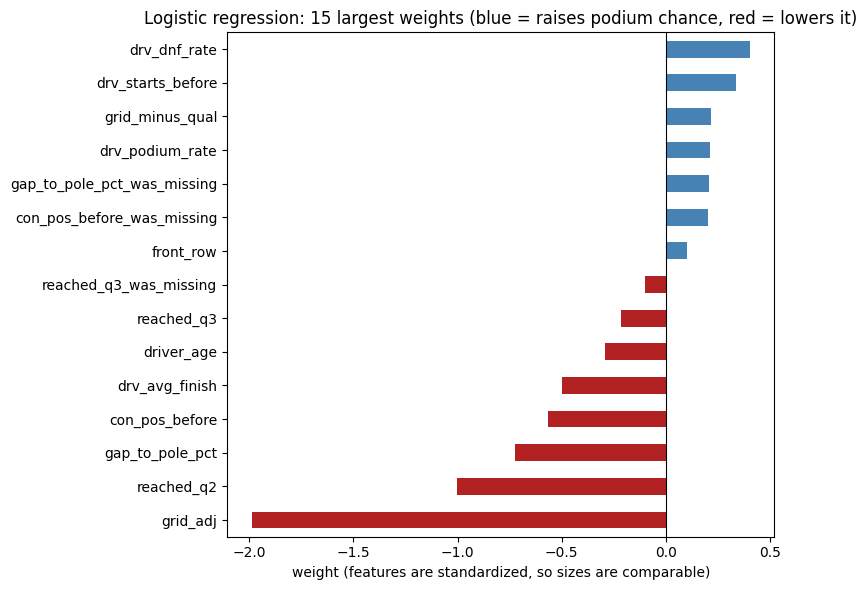

In [81]:
# ===== Step 2c: the learned weights (coefficients) =====
coef = pd.Series(lr_full.coef_[0], index=COLS)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15).sort_values()

top.plot(kind="barh", figsize=(8, 6),
         color=["firebrick" if v < 0 else "steelblue" for v in top])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("weight (features are standardized, so sizes are comparable)")
plt.title("Logistic regression: 15 largest weights (blue = raises podium chance, red = lowers it)")
plt.tight_layout(); plt.show()

## Step 3 – Gradient boosting (+ tuning depth and learning rate)
Many small decision trees built one after another, each correcting the previous ones' mistakes. Trees can learn interactions between features, do not need scaling, and handle missing values natively, so this model uses the raw features (R_*, NaN kept).
We try 4 tree depths (1–4) × 3 learning rates (0.01, 0.03, 0.1), 200 trees each, and choose by validation PR-AUC, watching the train–validation gap for overfitting. Depth 2 is an interior optimum; smaller learning rates were not tried because training PR-AUC was already falling (underfitting).

,max_depth,learning_rate,train_PR_AUC,val_PR_AUC,val_ROC_AUC,gap (train - val)
0,1,0.01,0.678,0.700,0.928,-0.022
1,1,0.03,0.715,0.729,0.934,-0.014
2,1,0.10,0.725,0.713,0.933,0.012
3,2,0.01,0.714,0.733,0.934,-0.019
4,2,0.03,0.738,0.727,0.935,0.011
5,2,0.10,0.780,0.691,0.931,0.089
6,3,0.01,0.738,0.718,0.934,0.020
7,3,0.03,0.769,0.715,0.935,0.055
8,3,0.10,0.846,0.703,0.930,0.143
9,4,0.01,0.765,0.713,0.931,0.052


Best (chosen on validation): max_depth = 2 | learning_rate = 0.01


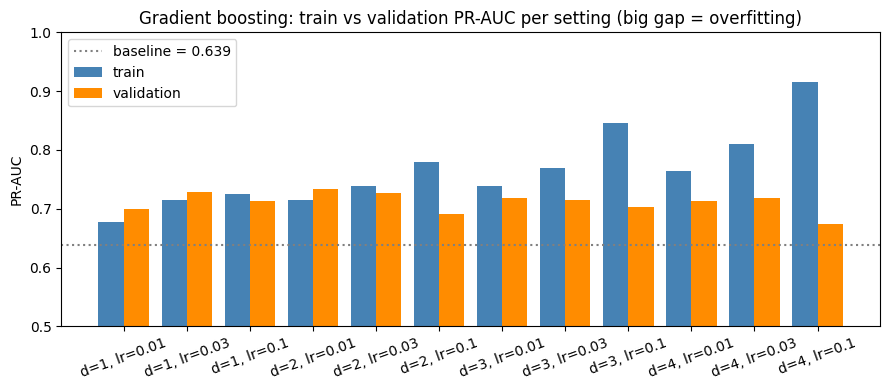

In [82]:
# ===== Step 3a: tune gradient boosting on validation =====
from sklearn.ensemble import HistGradientBoostingClassifier

GRID = [(depth, lr) for depth in [1, 2, 3, 4] for lr in [0.01, 0.03, 0.1]]
tuning = []
for depth, lr in GRID:
    m = HistGradientBoostingClassifier(max_depth=depth, learning_rate=lr, max_iter=200,
                                       random_state=SEED).fit(R_train[FINAL_FEATS], y_train)
    tr_pr = average_precision_score(y_train, m.predict_proba(R_train[FINAL_FEATS])[:, 1])
    va_p  = m.predict_proba(R_val[FINAL_FEATS])[:, 1]
    tuning.append({"max_depth": depth, "learning_rate": lr,
                   "train_PR_AUC": tr_pr,
                   "val_PR_AUC": average_precision_score(y_val, va_p),
                   "val_ROC_AUC": roc_auc_score(y_val, va_p),
                   "gap (train - val)": tr_pr - average_precision_score(y_val, va_p)})
tuning_gb = pd.DataFrame(tuning)
display(tuning_gb.round(3))

best = tuning_gb.loc[tuning_gb["val_PR_AUC"].idxmax()]
BEST_DEPTH, BEST_LR = int(best["max_depth"]), float(best["learning_rate"])
print("Best (chosen on validation): max_depth =", BEST_DEPTH, "| learning_rate =", BEST_LR)

labels = [f"d={d}, lr={l}" for d, l in zip(tuning_gb["max_depth"], tuning_gb["learning_rate"])]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, tuning_gb["train_PR_AUC"], width=0.4, label="train", color="steelblue")
ax.bar(x + 0.2, tuning_gb["val_PR_AUC"], width=0.4, label="validation", color="darkorange")
ax.axhline(0.639, linestyle=":", color="gray", label="baseline = 0.639")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=20)
ax.set_ylim(0.5, 1.0); ax.set_ylabel("PR-AUC")
ax.set_title("Gradient boosting: train vs validation PR-AUC per setting (big gap = overfitting)")
ax.legend(); plt.tight_layout(); plt.show()

In [83]:
# remove any earlier gradient-boosting result (its name may change if a new setting wins)
RESULTS[:] = [r for r in RESULTS if not r["model"].startswith("Gradient boosting")]
for k in [k for k in FINAL_MODELS if k.startswith("Gradient boosting")]: del FINAL_MODELS[k]
# ===== Step 3b: final gradient boosting with the chosen settings =====
gb = HistGradientBoostingClassifier(max_depth=BEST_DEPTH, learning_rate=BEST_LR, max_iter=200,
                                    random_state=SEED).fit(R_train[FINAL_FEATS], y_train)

p_tr_gb = gb.predict_proba(R_train[FINAL_FEATS])[:, 1]
p_va_gb = gb.predict_proba(R_val[FINAL_FEATS])[:, 1]

name = f"Gradient boosting (depth={BEST_DEPTH}, lr={BEST_LR})"
thr_gb = add_results(name, p_tr_gb, p_va_gb)
FINAL_MODELS[name] = {"model": gb, "cols": FINAL_FEATS, "data": "R", "thr": thr_gb}

print("Threshold chosen on validation:", thr_gb)
display(pd.DataFrame(RESULTS).round(3))

Threshold chosen on validation: 0.35


,model,split,threshold,ROC_AUC,PR_AUC,F1,precision,recall
0,Baseline: LR (grid only),train,0.38,0.918,0.645,0.662,0.663,0.662
1,Baseline: LR (grid only),validation,0.38,0.909,0.639,0.692,0.692,0.692
2,"LR (all features, C=1.0)",train,0.22,0.939,0.715,0.672,0.556,0.850
3,"LR (all features, C=1.0)",validation,0.22,0.933,0.737,0.720,0.646,0.812
4,"Gradient boosting (depth=2, lr=0.01)",train,0.35,0.942,0.714,0.689,0.658,0.724
5,"Gradient boosting (depth=2, lr=0.01)",validation,0.35,0.934,0.733,0.703,0.697,0.709


## Step 4 – Shallow neural network (feedforward, 1–2 hidden layers)
sklearn MLPClassifier with ReLU hidden units, trained on the same 28 preprocessed columns as logistic regression (neural networks need scaled inputs).
Overfitting control: L2 penalty `alpha` and early stopping (10% of the TRAINING rows held out internally; stop after 10 epochs without improvement).
We try 3 architectures × 2 alpha values and choose by validation PR-AUC. Because the starting weights are random, we also check stability across 5 seeds.

In [84]:
# ===== Step 4a: tune the neural network on validation =====
from sklearn.neural_network import MLPClassifier

NN_GRID = [(layers, alpha) for layers in [(16,), (32,), (32, 16)] for alpha in [0.0001, 0.01]]
tuning = []
for layers, alpha in NN_GRID:
    m = MLPClassifier(hidden_layer_sizes=layers, alpha=alpha, early_stopping=True,
                      max_iter=500, random_state=SEED).fit(X_train[COLS], y_train)
    tr_pr = average_precision_score(y_train, m.predict_proba(X_train[COLS])[:, 1])
    va_p  = m.predict_proba(X_val[COLS])[:, 1]
    va_pr = average_precision_score(y_val, va_p)
    tuning.append({"hidden_layers": str(layers), "alpha": alpha, "epochs_run": m.n_iter_,
                   "train_PR_AUC": tr_pr, "val_PR_AUC": va_pr,
                   "val_ROC_AUC": roc_auc_score(y_val, va_p), "gap (train - val)": tr_pr - va_pr})
tuning_nn = pd.DataFrame(tuning)
display(tuning_nn.round(4))

best_i = tuning_nn["val_PR_AUC"].idxmax()
BEST_LAYERS, BEST_ALPHA = NN_GRID[best_i]
print("Best (chosen on validation): hidden layers =", BEST_LAYERS, "| alpha =", BEST_ALPHA)

,hidden_layers,alpha,epochs_run,train_PR_AUC,val_PR_AUC,val_ROC_AUC,gap (train - val)
0,"(16,)",0.0001,47,0.6917,0.6957,0.9146,-0.0040
1,"(16,)",0.0100,47,0.6917,0.6957,0.9146,-0.0040
2,"(32,)",0.0001,37,0.7176,0.6963,0.9250,0.0212
3,"(32,)",0.0100,34,0.7134,0.6930,0.9242,0.0204
4,"(32, 16)",0.0001,15,0.6401,0.6498,0.8940,-0.0098
5,"(32, 16)",0.0100,15,0.6399,0.6498,0.8940,-0.0099


Best (chosen on validation): hidden layers = (32,) | alpha = 0.0001


Epochs run: 37 | threshold chosen on validation: 0.3


,model,split,threshold,ROC_AUC,PR_AUC,F1,precision,recall
0,Baseline: LR (grid only),train,0.38,0.918,0.645,0.662,0.663,0.662
1,Baseline: LR (grid only),validation,0.38,0.909,0.639,0.692,0.692,0.692
2,"LR (all features, C=1.0)",train,0.22,0.939,0.715,0.672,0.556,0.850
3,"LR (all features, C=1.0)",validation,0.22,0.933,0.737,0.720,0.646,0.812
4,"Gradient boosting (depth=2, lr=0.01)",train,0.35,0.942,0.714,0.689,0.658,0.724
5,"Gradient boosting (depth=2, lr=0.01)",validation,0.35,0.934,0.733,0.703,0.697,0.709
6,"Neural network (32,), alpha=0.0001",train,0.30,0.940,0.718,0.685,0.596,0.803
7,"Neural network (32,), alpha=0.0001",validation,0.30,0.925,0.696,0.697,0.669,0.726


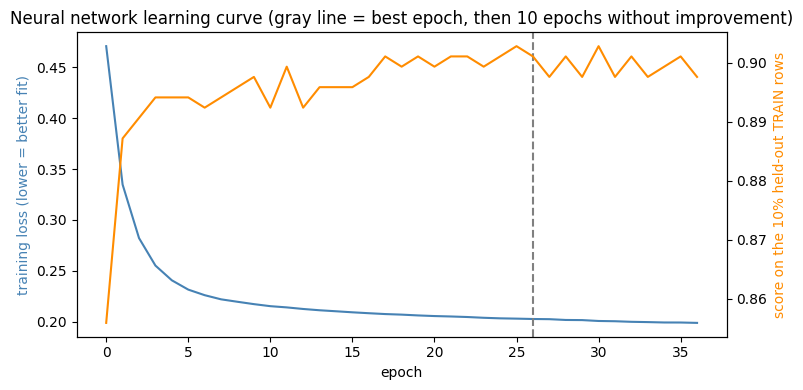

In [85]:
# ===== Step 4b: final neural network with the chosen settings =====
nn = MLPClassifier(hidden_layer_sizes=BEST_LAYERS, alpha=BEST_ALPHA, early_stopping=True,
                   max_iter=500, random_state=SEED).fit(X_train[COLS], y_train)

p_tr_nn = nn.predict_proba(X_train[COLS])[:, 1]
p_va_nn = nn.predict_proba(X_val[COLS])[:, 1]

name = f"Neural network {BEST_LAYERS}, alpha={BEST_ALPHA}"
thr_nn = add_results(name, p_tr_nn, p_va_nn)
FINAL_MODELS[name] = {"model": nn, "cols": COLS, "data": "X", "thr": thr_nn}

print("Epochs run:", nn.n_iter_, "| threshold chosen on validation:", thr_nn)
display(pd.DataFrame(RESULTS).round(3))

# Learning curve: how the loss fell during training, and when early stopping kicked in
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(nn.loss_curve_, color="steelblue")
ax1.set_xlabel("epoch"); ax1.set_ylabel("training loss (lower = better fit)", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(nn.validation_scores_, color="darkorange")
ax2.set_ylabel("score on the 10% held-out TRAIN rows", color="darkorange")
ax1.axvline(nn.n_iter_ - 1 - nn.n_iter_no_change, linestyle="--", color="gray")
ax1.set_title("Neural network learning curve (gray line = best epoch, then 10 epochs without improvement)")
plt.tight_layout(); plt.show()

In [86]:
# ===== Step 4c: does the result depend on the random starting weights? =====
rows = []
for s in [0, 1, 2, 3, 4]:
    m = MLPClassifier(hidden_layer_sizes=BEST_LAYERS, alpha=BEST_ALPHA, early_stopping=True,
                      max_iter=500, random_state=s).fit(X_train[COLS], y_train)
    rows.append({"seed": s, "val_PR_AUC": average_precision_score(y_val, m.predict_proba(X_val[COLS])[:, 1])})
seeds_nn = pd.DataFrame(rows)
display(seeds_nn.round(3))
print("Validation PR-AUC across seeds: mean =", round(seeds_nn["val_PR_AUC"].mean(), 3),
      "| std =", round(seeds_nn["val_PR_AUC"].std(), 3))

,seed,val_PR_AUC
0,0,0.666
1,1,0.650
2,2,0.691
3,3,0.666
4,4,0.657


Validation PR-AUC across seeds: mean = 0.666 | std = 0.015


## Step 5 – Model comparison (validation 2020-21)
All saved models side by side: the five metrics, the train–validation gap (overfitting check), and a 95% race-bootstrap interval for PR-AUC (re-sampling the 39 validation races, function from Requirement 3).
The final model choice uses validation only; the test set is still untouched.

In [87]:
# ===== Step 5a: one comparison table (validation) =====
DATA = {"X": {"train": X_train, "validation": X_val, "test": X_test},
        "R": {"train": R_train, "validation": R_val, "test": R_test}}

def predict(name, split):
    """Probabilities of a saved model on a split, using the right data type (X or R) and columns."""
    e = FINAL_MODELS[name]
    return e["model"].predict_proba(DATA[e["data"]][split][e["cols"]])[:, 1]

res = pd.DataFrame(RESULTS)
res = res[res["model"].isin(FINAL_MODELS)]                       # only the final, saved models
pr = res.pivot(index="model", columns="split", values="PR_AUC")  # PR-AUC: one column per split

comp = (res[res["split"] == "validation"].set_index("model")
          [["PR_AUC", "ROC_AUC", "F1", "precision", "recall", "threshold"]])
comp["train_PR_AUC"] = pr["train"]
comp["gap (train - val)"] = pr["train"] - pr["validation"]

ci = {name: boot_ci(va, predict(name, "validation")) for name in comp.index}
comp["PR_AUC 95% CI"] = [f"{ci[n][0]:.2f} – {ci[n][1]:.2f}" for n in comp.index]

comp = comp.sort_values("PR_AUC", ascending=False)
display(comp.round(3))
print("Best on validation PR-AUC (primary metric):", comp.index[0])

,PR_AUC,ROC_AUC,F1,precision,recall,threshold,train_PR_AUC,gap (train - val),PR_AUC 95% CI
model,,,,,,,,,
"LR (all features, C=1.0)",0.737,0.933,0.720,0.646,0.812,0.22,0.715,-0.022,0.62 – 0.84
"Gradient boosting (depth=2, lr=0.01)",0.733,0.934,0.703,0.697,0.709,0.35,0.714,-0.019,0.62 – 0.84
"Neural network (32,), alpha=0.0001",0.696,0.925,0.697,0.669,0.726,0.30,0.718,0.021,0.57 – 0.82
Baseline: LR (grid only),0.639,0.909,0.692,0.692,0.692,0.38,0.645,0.006,0.53 – 0.75


Best on validation PR-AUC (primary metric): LR (all features, C=1.0)


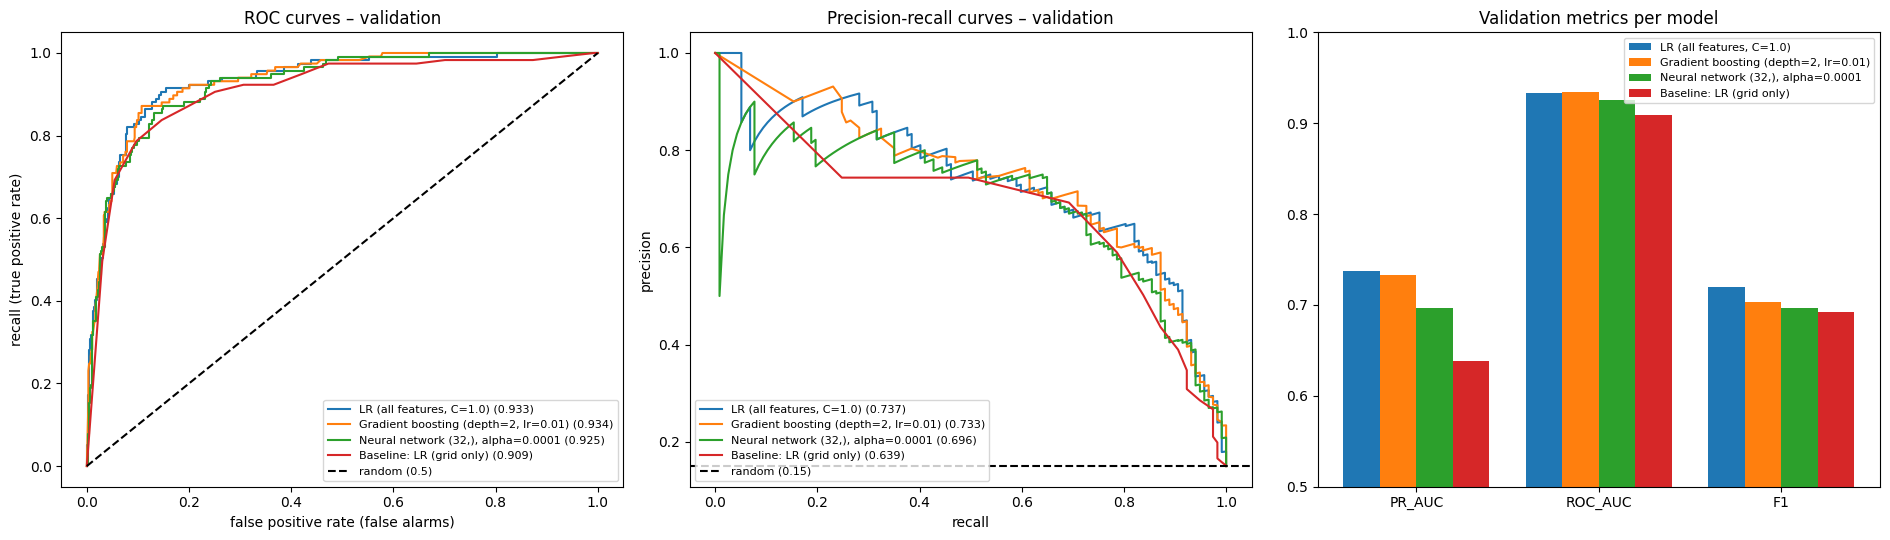

In [88]:
# ===== Step 5b: ROC curves, PR curves and a metric bar chart (validation) =====
from sklearn.metrics import roc_curve, precision_recall_curve

names = list(comp.index)
colors = plt.cm.tab10(np.arange(len(names)))
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

for name, col in zip(names, colors):
    p = predict(name, "validation")
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[0].plot(fpr, tpr, color=col, label=f"{name} ({roc_auc_score(y_val, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[1].plot(rec, prec, color=col, label=f"{name} ({average_precision_score(y_val, p):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="random (0.5)")
axes[0].set_xlabel("false positive rate (false alarms)"); axes[0].set_ylabel("recall (true positive rate)")
axes[0].set_title("ROC curves – validation"); axes[0].legend(fontsize=8, loc="lower right")

axes[1].axhline(y_val.mean(), color="k", linestyle="--", label=f"random ({y_val.mean():.2f})")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curves – validation"); axes[1].legend(fontsize=8, loc="lower left")

m = ["PR_AUC", "ROC_AUC", "F1"]
x = np.arange(len(m)); w = 0.8 / len(names)
for i, (name, col) in enumerate(zip(names, colors)):
    axes[2].bar(x + i * w - 0.4 + w / 2, comp.loc[name, m].astype(float), width=w, color=col, label=name)
axes[2].set_xticks(x); axes[2].set_xticklabels(m); axes[2].set_ylim(0.5, 1.0)
axes[2].set_title("Validation metrics per model"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

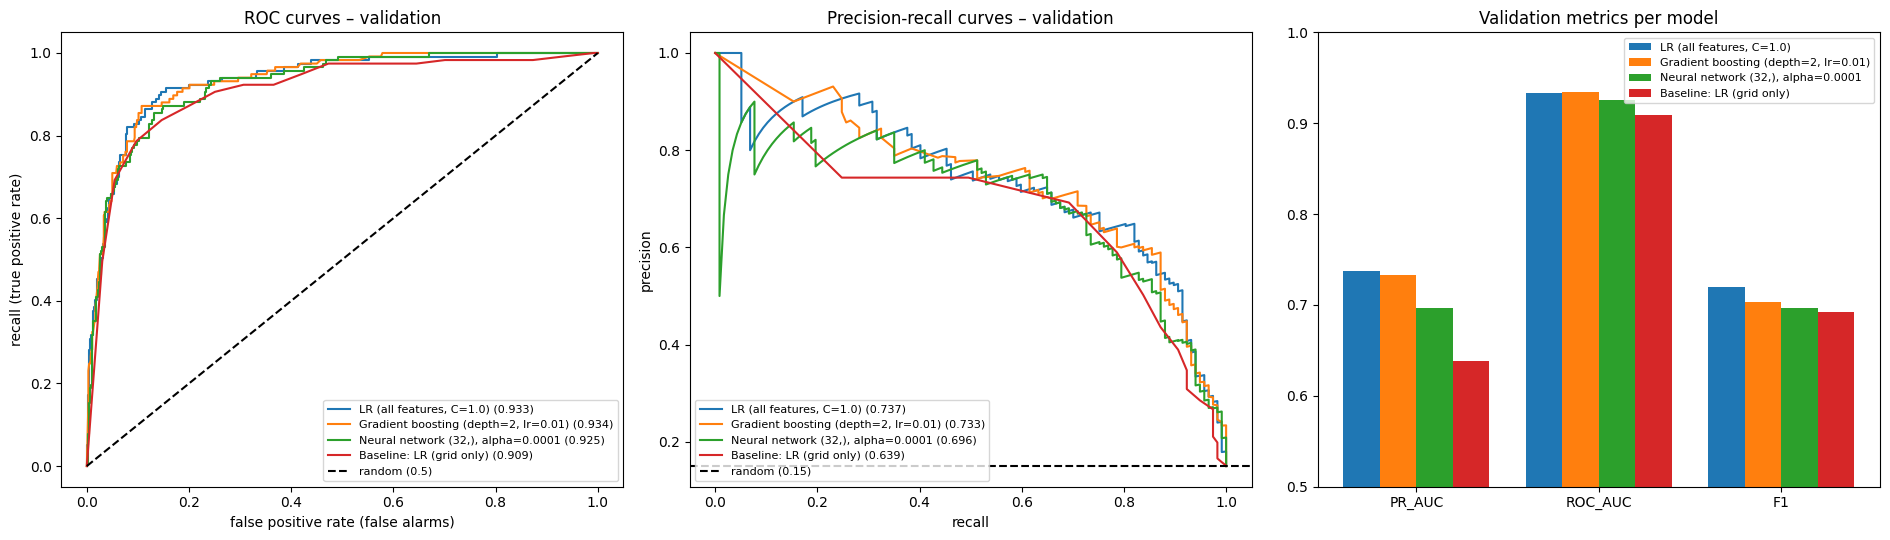

In [89]:
# ===== Step 5b: ROC curves, PR curves and a metric bar chart (validation) =====
from sklearn.metrics import roc_curve, precision_recall_curve

names = list(comp.index)
colors = plt.cm.tab10(np.arange(len(names)))
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

for name, col in zip(names, colors):
    p = predict(name, "validation")
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[0].plot(fpr, tpr, color=col, label=f"{name} ({roc_auc_score(y_val, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[1].plot(rec, prec, color=col, label=f"{name} ({average_precision_score(y_val, p):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="random (0.5)")
axes[0].set_xlabel("false positive rate (false alarms)"); axes[0].set_ylabel("recall (true positive rate)")
axes[0].set_title("ROC curves – validation"); axes[0].legend(fontsize=8, loc="lower right")

axes[1].axhline(y_val.mean(), color="k", linestyle="--", label=f"random ({y_val.mean():.2f})")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curves – validation"); axes[1].legend(fontsize=8, loc="lower left")

m = ["PR_AUC", "ROC_AUC", "F1"]
x = np.arange(len(m)); w = 0.8 / len(names)
for i, (name, col) in enumerate(zip(names, colors)):
    axes[2].bar(x + i * w - 0.4 + w / 2, comp.loc[name, m].astype(float), width=w, color=col, label=name)
axes[2].set_xticks(x); axes[2].set_xticklabels(m); axes[2].set_ylim(0.5, 1.0)
axes[2].set_title("Validation metrics per model"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Step 6 – Final evaluation on the unseen test set (2022-24)
Each saved model is scored once on the test seasons, using the threshold chosen on validation (no re-tuning). Nothing was changed after seeing these results.
The test set also checks robustness to the 2022 regulation change (ground-effect cars), which is outside the training era.

In [90]:
# ===== Step 6a: score every saved model on TEST (once) =====
FINAL_CHOICE = comp.index[0]          # best on validation PR-AUC, chosen in Step 5
print("Final model (chosen on validation):", FINAL_CHOICE)

test_rows = []
for name, e in FINAL_MODELS.items():
    p = predict(name, "test")
    row = evaluate(name, "test", y_test, p, e["thr"])      # threshold from VALIDATION
    lo, hi = boot_ci(te, p)                                 # 95% interval over the 68 test races
    row["PR_AUC 95% CI"] = f"{lo:.2f} – {hi:.2f}"
    test_rows.append(row)

test_tbl = pd.DataFrame(test_rows).set_index("model").drop(columns="split").loc[comp.index]
print("TEST results (2022-24):")
display(test_tbl.round(3))

side = pd.DataFrame({"val_PR_AUC": comp["PR_AUC"],   "test_PR_AUC": test_tbl["PR_AUC"],
                     "val_ROC_AUC": comp["ROC_AUC"], "test_ROC_AUC": test_tbl["ROC_AUC"],
                     "val_F1": comp["F1"],           "test_F1": test_tbl["F1"]})
side["PR_AUC change (test - val)"] = side["test_PR_AUC"] - side["val_PR_AUC"]
print("Validation vs test:")
display(side.round(3))
print("Test podium rate:", round(y_test.mean(), 3), "(a random model's PR-AUC is about this)")

Final model (chosen on validation): LR (all features, C=1.0)
TEST results (2022-24):


,threshold,ROC_AUC,PR_AUC,F1,precision,recall,PR_AUC 95% CI
model,,,,,,,
"LR (all features, C=1.0)",0.22,0.932,0.710,0.672,0.540,0.887,0.65 – 0.77
"Gradient boosting (depth=2, lr=0.01)",0.35,0.937,0.695,0.673,0.647,0.701,0.64 – 0.75
"Neural network (32,), alpha=0.0001",0.30,0.925,0.689,0.654,0.577,0.755,0.63 – 0.75
Baseline: LR (grid only),0.38,0.914,0.647,0.649,0.650,0.647,0.59 – 0.70


Validation vs test:


,val_PR_AUC,test_PR_AUC,val_ROC_AUC,test_ROC_AUC,val_F1,test_F1,PR_AUC change (test - val)
model,,,,,,,
"LR (all features, C=1.0)",0.737,0.710,0.933,0.932,0.720,0.672,-0.027
"Gradient boosting (depth=2, lr=0.01)",0.733,0.695,0.934,0.937,0.703,0.673,-0.038
"Neural network (32,), alpha=0.0001",0.696,0.689,0.925,0.925,0.697,0.654,-0.008
Baseline: LR (grid only),0.639,0.647,0.909,0.914,0.692,0.649,0.009


Test podium rate: 0.151 (a random model's PR-AUC is about this)


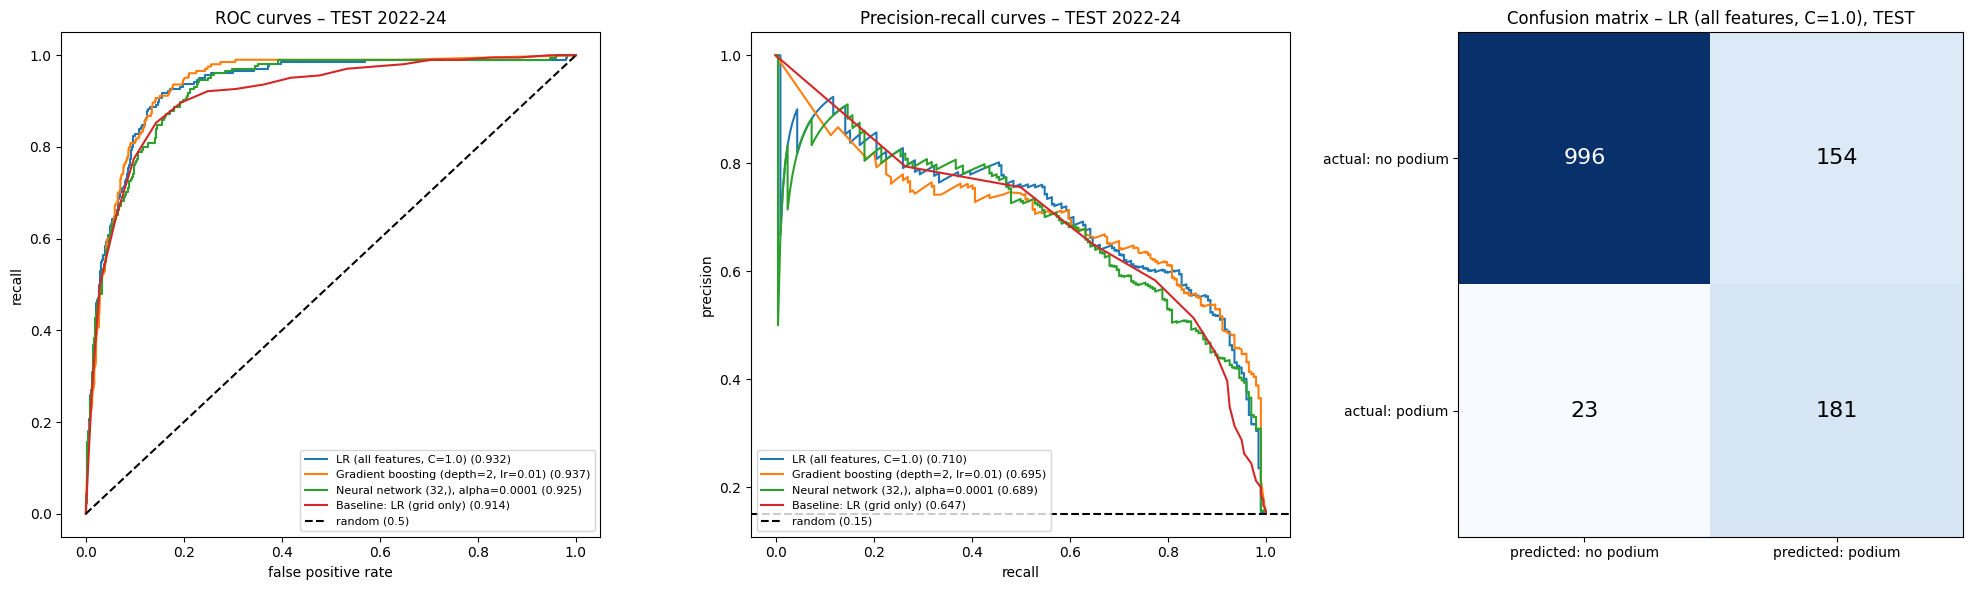

Caught 181 of 204 real podiums (recall 0.89); 154 false alarms; precision 0.54


In [91]:
# ===== Step 6b: test ROC / PR curves + confusion matrix of the final model =====
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for name, col in zip(names, colors):
    p = predict(name, "test")
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=col, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=col, label=f"{name} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="random (0.5)")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("recall")
axes[0].set_title("ROC curves – TEST 2022-24"); axes[0].legend(fontsize=8, loc="lower right")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label=f"random ({y_test.mean():.2f})")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curves – TEST 2022-24"); axes[1].legend(fontsize=8, loc="lower left")

# Confusion matrix: the final model's yes/no decisions on test
p = predict(FINAL_CHOICE, "test")
cm = confusion_matrix(y_test, (p >= FINAL_MODELS[FINAL_CHOICE]["thr"]).astype(int))
axes[2].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[2].text(j, i, v, ha="center", va="center", fontsize=16,
                 color="white" if v > cm.max() / 2 else "black")
axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["predicted: no podium", "predicted: podium"])
axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["actual: no podium", "actual: podium"])
axes[2].set_title(f"Confusion matrix – {FINAL_CHOICE}, TEST")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp} of {tp + fn} real podiums (recall {tp/(tp+fn):.2f}); "
      f"{fp} false alarms; precision {tp/(tp+fp):.2f}")

### Metric choice
**Primary metric: PR-AUC.** Podiums are rare (~15% of rows: 15.0% validation, 15.1% test), so a model that only ranks easy non-podium drivers (e.g. P18 starters) low can still score a high ROC-AUC. PR-AUC focuses on how well the model ranks the actual podium finishers at the top, and a random model scores about the podium rate (~0.15), so the scale is easy to read. It also needs no threshold.
**Secondary metric: ROC-AUC**, for overall ranking quality. In our results it barely separates the models (0.91–0.94 for all), which confirms why it is secondary.
**F1, precision and recall** are reported at a threshold chosen on validation (best F1). They depend on that threshold, which is why they are not used to choose the model.

### Models: how they work and their limitations
| Model | How it works | Limitations |
|---|---|---|
| **Baseline: logistic regression on grid only** | One weight for the starting slot, turned into a probability by the sigmoid function. Learned weight is negative: further back = lower podium chance. | Can only predict podiums for P1–P3 starters; ignores form, team strength and qualifying pace. |
| **Logistic regression (all 16 features + 12 missing-value flags)** | A weighted sum of all features through a sigmoid. C (regularization) tuned on validation: performance plateaus from C≈0.1, C=1 chosen. | Only learns straight-line (monotonic) effects, no interactions. Correlated features split credit, so some weights have counter-intuitive signs (e.g. drv_dnf_rate, reached_q3); weights are not causal effects. |
| **Gradient boosting (HistGradientBoosting, 200 trees)** | Many small decision trees built one after another, each correcting the previous ones. Learns interactions, needs no scaling, handles missing values natively (raw features used). Depth 1–4 × learning rate 0.01–0.1 tuned on validation; depth 2, lr 0.01 chosen. | Overfits easily: deeper/faster settings reached train PR-AUC 0.915 vs validation 0.674 (gap 0.24). Harder to explain than logistic regression. |
| **Shallow neural network (MLP, 1 hidden layer of 32 ReLU units)** | Layers of neurons trained over epochs to reduce the loss; early stopping (10% of training rows held out) and an L2 penalty against overfitting. 3 architectures × 2 alpha values tuned on validation. | Depends on random starting weights (validation PR-AUC 0.666 ± 0.015 over 5 seeds; the chosen seed scored 0.696). Needs scaled inputs. The 2-layer network stopped after 15 epochs and underfit. Black box (no readable weights). |

### Results and conclusion
| Model | val PR-AUC | test PR-AUC | test 95% CI | test ROC-AUC | test F1 |
|---|---|---|---|---|---|
| Logistic regression (all features) | **0.737** | **0.710** | 0.65–0.77 | 0.932 | 0.672 |
| Gradient boosting | 0.733 | 0.695 | 0.64–0.75 | 0.937 | 0.673 |
| Neural network | 0.696 | 0.689 | 0.63–0.75 | 0.925 | 0.654 |
| Baseline (grid only) | 0.639 | 0.647 | 0.59–0.70 | 0.914 | 0.649 |

- **All three richer models beat the grid-only baseline** on validation and test, so form, standings and qualifying features add real information beyond the starting slot.
- **Logistic regression was chosen as the final model** on validation PR-AUC (before the test set was used). It is statistically tied with gradient boosting (identical validation intervals 0.62–0.84), so the simplest, most stable and most explainable model was preferred.
- **More complex models did not help**: gradient boosting's extra flexibility mainly increased overfitting, and the neural network was less stable. This suggests the relationships are largely monotonic (better grid / form / team → more podiums) and the training set (5,760 rows) is small.
- **The models generalise to unseen seasons**: test PR-AUC dropped by less than 0.04 despite the 2022 regulation change, and the model ranking was unchanged.
- **On test, the final model caught 181 of 204 podiums (recall 0.89) with 154 false alarms (precision 0.54).** The validation threshold (0.22) produces about 5 "podium" predictions per race in 2022–24, so threshold-dependent metrics are less stable across eras than PR-AUC.
- No model, hyperparameter or threshold was changed after seeing the test results.

### Limitations
- **Small evaluation sets**: 39 validation races and 68 test races, so differences below ~0.05 PR-AUC are within noise (bootstrap intervals ±0.06–0.11).
- **Era sensitivity**: the advantage over the baseline is smaller on test (+0.06) than on validation (+0.10), and the threshold chosen on 2020–21 over-predicts podiums in 2022–24.
- **Threshold transfer**: F1, precision and recall depend on a threshold chosen in one era; a deployed model would need re-calibration each season.
- **Training window**: 2006–2019 only (consistent qualifying format); older eras are used only as history for form and standings features.
- **Not causal**: model weights and later importance scores (Requirement 6) show what the model relies on, not what causes podiums.
- **No retraining on train + validation** before testing: we kept the exact models and thresholds selected on validation, at the cost of not using the 2020–21 data for fitting.

In [92]:
# ===== Requirement 5: feature-group ablation (final model = logistic regression, validation) =====
def fit_eval_lr(cols):
    m = LogisticRegression(C=BEST_C, max_iter=5000, random_state=SEED).fit(X_train[cols], y_train)
    p_va = m.predict_proba(X_val[cols])[:, 1]
    thr = pick_threshold(y_val, p_va)                    # threshold from VALIDATION only
    return p_va, evaluate("ablation", "validation", y_val, p_va, thr)

def paired_delta_ci(p_ref, p_new, n=300, seed=0):
    """95% interval for PR-AUC(new) - PR-AUC(ref), resampling whole races."""
    rng = np.random.default_rng(seed)
    y, races = va[TARGET].values, va["raceId"].values
    idx = [np.where(races == r)[0] for r in np.unique(races)]
    d = []
    for _ in range(n):
        take = np.concatenate([idx[i] for i in rng.integers(0, len(idx), len(idx))])
        if y[take].sum() > 0:
            d.append(average_precision_score(y[take], p_new[take]) - average_precision_score(y[take], p_ref[take]))
    return np.percentile(d, [2.5, 97.5])

p_full, r_full = fit_eval_lr(COLS)
rows = [{"setting": "Full model", "n_cols": len(COLS), "PR_AUC": r_full["PR_AUC"], "ROC_AUC": r_full["ROC_AUC"],
         "F1": r_full["F1"], "ΔPR_AUC": 0.0, "Δ 95% CI": "-"}]

for g, gcols in GROUP_COLS.items():
    # (a) leave this group OUT
    keep = [c for c in COLS if c not in gcols]
    p, r = fit_eval_lr(keep)
    lo, hi = paired_delta_ci(p_full, p)
    rows.append({"setting": f"without {g}", "n_cols": len(keep), "PR_AUC": r["PR_AUC"], "ROC_AUC": r["ROC_AUC"],
                 "F1": r["F1"], "ΔPR_AUC": r["PR_AUC"] - r_full["PR_AUC"], "Δ 95% CI": f"{lo:+.3f} to {hi:+.3f}"})
    # (b) keep ONLY this group
    p, r = fit_eval_lr(gcols)
    lo, hi = paired_delta_ci(p_full, p)
    rows.append({"setting": f"only {g}", "n_cols": len(gcols), "PR_AUC": r["PR_AUC"], "ROC_AUC": r["ROC_AUC"],
                 "F1": r["F1"], "ΔPR_AUC": r["PR_AUC"] - r_full["PR_AUC"], "Δ 95% CI": f"{lo:+.3f} to {hi:+.3f}"})

ablation = pd.DataFrame(rows)
display(ablation.round(3))

,setting,n_cols,PR_AUC,ROC_AUC,F1,ΔPR_AUC,Δ 95% CI
0,Full model,28,0.737,0.933,0.720,0.000,-
1,without grid,24,0.686,0.920,0.680,-0.051,-0.080 to -0.018
2,only grid,4,0.661,0.917,0.699,-0.076,-0.130 to -0.023
3,without qualifying,22,0.720,0.928,0.705,-0.017,-0.032 to -0.001
4,only qualifying,6,0.628,0.901,0.656,-0.109,-0.177 to -0.047
5,without context,27,0.732,0.932,0.715,-0.005,-0.021 to +0.012
6,only context,1,0.193,0.597,0.340,-0.544,-0.626 to -0.449
7,without driver_form,21,0.705,0.930,0.702,-0.032,-0.064 to +0.007
8,only driver_form,7,0.630,0.885,0.659,-0.107,-0.152 to -0.046
9,without constructor_form,22,0.728,0.933,0.725,-0.009,-0.025 to +0.003


# Requirement 5: Experiments (feature-group ablation)
The preprocessing-order experiments required alongside the ablation are in Section E (Requirement 3): three orders of clip / impute / scale, fitting the preprocessing on train+validation (leaky), and no clipping, all compared with a paired race bootstrap. None changed validation PR-AUC by more than 0.002.


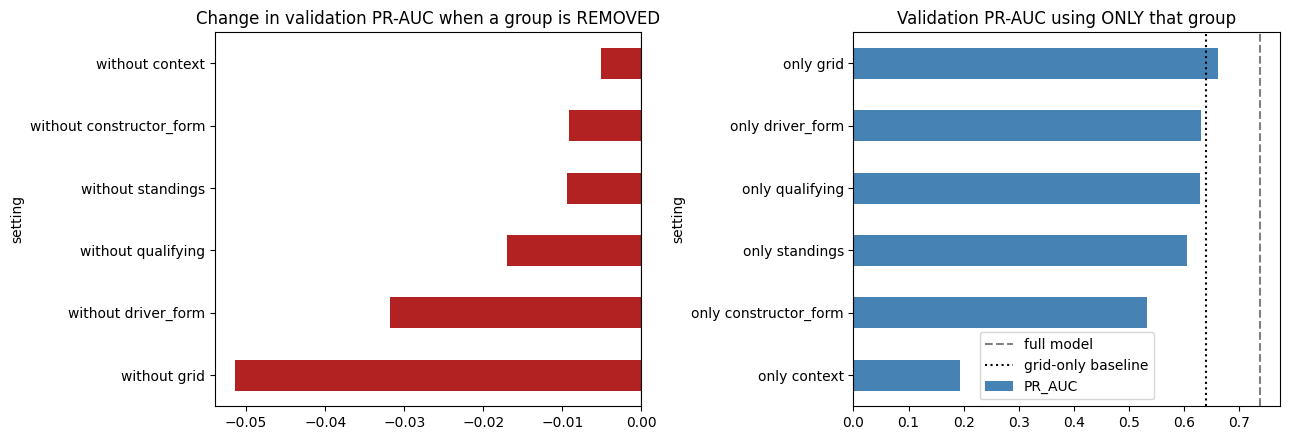

In [93]:
# Plot: how much does PR-AUC drop without each group, and how good is each group alone?
wo = ablation[ablation["setting"].str.startswith("without")].set_index("setting")["ΔPR_AUC"]
on = ablation[ablation["setting"].str.startswith("only")].set_index("setting")["PR_AUC"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
wo.sort_values().plot(kind="barh", ax=ax[0], color="firebrick")
ax[0].axvline(0, color="black", linewidth=0.8)
ax[0].set_title("Change in validation PR-AUC when a group is REMOVED")
on.sort_values().plot(kind="barh", ax=ax[1], color="steelblue")
ax[1].axvline(r_full["PR_AUC"], linestyle="--", color="gray", label="full model")
ax[1].axvline(0.639, linestyle=":", color="black", label="grid-only baseline")
ax[1].set_title("Validation PR-AUC using ONLY that group"); ax[1].legend()
plt.tight_layout(); plt.show()

Feature-group ablation (logistic regression, validation 2020-21). We retrained the final model with each feature group removed, and with only that group, keeping C fixed and re-choosing the F1 threshold on validation. The full model scores PR-AUC 0.737.

Grid is the most important group: removing it lowers PR-AUC by 0.051 (95% interval -0.080 to -0.018), and it is also the strongest group alone (0.661). This agrees with Section C, where podium rate fell steeply with grid slot. Removing qualifying (-0.017, interval barely below zero) or driver form (-0.032, interval includes zero) costs less. Constructor form, standings and context each cost under 0.01 and their intervals include zero, so we cannot show they contribute once the other groups are present. Constructor form and standings are informative on their own (0.532 and 0.605), so their small drops reflect redundancy with grid, qualifying and driver form, not uselessness. Context (driver age) has almost no signal alone (0.193, near the podium rate).

Caveats: only 39 validation races, so differences below about 0.05 are within noise; F1 depends on a threshold and is not used to compare groups; groups are correlated, so removal drops understate importance. Ablation measures what the model relies on, not what causes podiums.

# Requirement 6: Model Explainability (XAI)
We explain the final model (logistic regression) on the **validation** rows (2020-21). The test set was already used once and is not touched here. Nothing in this section changes a model, feature or threshold.



,feature,mean_drop,std
0,grid_adj,0.4345,0.0282
4,reached_q2,0.0787,0.0191
8,drv_avg_finish,0.0571,0.0197
10,drv_starts_before,0.0510,0.0140
15,con_pos_before,0.0468,0.0165
3,gap_to_pole_pct,0.0261,0.0196
7,drv_podium_rate,0.0223,0.0129
2,grid_minus_qual,0.0188,0.0167
27,con_pos_before_was_missing,0.0163,0.0136
9,drv_dnf_rate,0.0129,0.0145


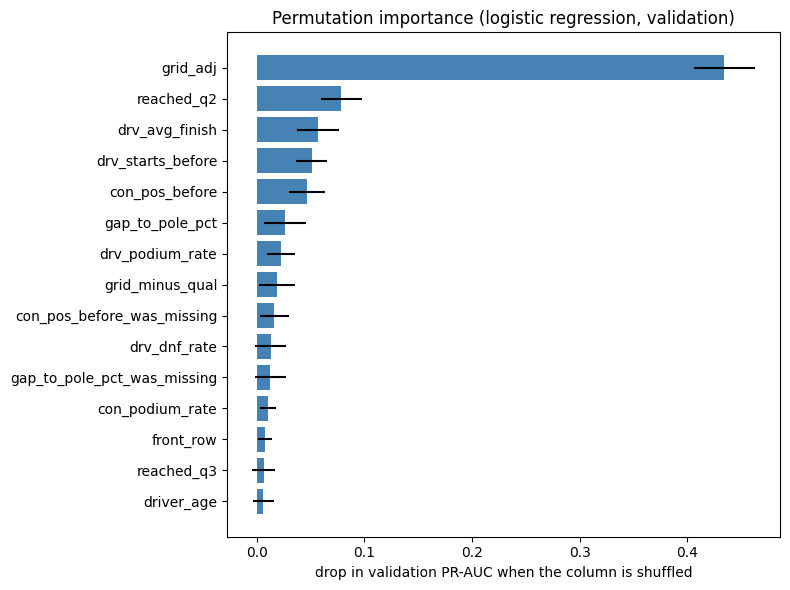

,mean_drop,std
grid,0.4524,0.0216
driver_form,0.1325,0.0279
qualifying,0.0940,0.0293
standings,0.0522,0.0199
context,0.0068,0.0106
constructor_form,0.0066,0.0071


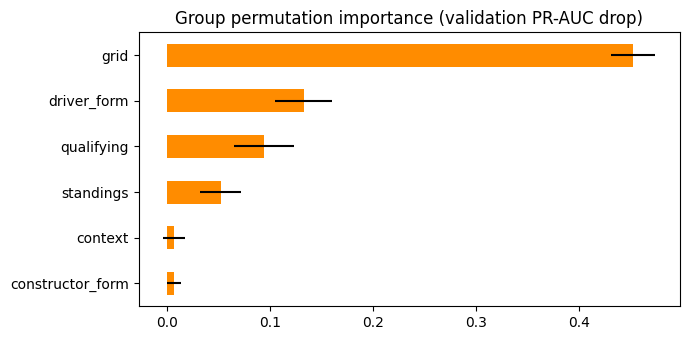

In [94]:
from sklearn.inspection import permutation_importance

# (a) per column: score drop when one column is shuffled (30 repeats)
pi = permutation_importance(lr_full, X_val[COLS], y_val, scoring="average_precision",
                            n_repeats=30, random_state=SEED)
pi_df = (pd.DataFrame({"feature": COLS, "mean_drop": pi.importances_mean, "std": pi.importances_std})
         .sort_values("mean_drop", ascending=False))
display(pi_df.head(15).round(4))

top = pi_df.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["mean_drop"], xerr=top["std"], color="steelblue")
plt.xlabel("drop in validation PR-AUC when the column is shuffled")
plt.title("Permutation importance (logistic regression, validation)")
plt.tight_layout(); plt.show()

# (b) per GROUP: shuffle a whole group's columns together (comparable to the ablation)
rng = np.random.default_rng(SEED)
base = average_precision_score(y_val, lr_full.predict_proba(X_val[COLS])[:, 1])
grp = {}
for g, gc in GROUP_COLS.items():
    drops = []
    for _ in range(30):
        Xp = X_val[COLS].copy()
        Xp[gc] = Xp[gc].values[rng.permutation(len(Xp))]
        drops.append(base - average_precision_score(y_val, lr_full.predict_proba(Xp)[:, 1]))
    grp[g] = {"mean_drop": np.mean(drops), "std": np.std(drops)}
grp_df = pd.DataFrame(grp).T.sort_values("mean_drop", ascending=False)
display(grp_df.round(4))
grp_df["mean_drop"].iloc[::-1].plot(kind="barh", xerr=grp_df["std"].iloc[::-1], figsize=(7, 3.5), color="darkorange")
plt.title("Group permutation importance (validation PR-AUC drop)"); plt.tight_layout(); plt.show()

**Permutation importance.** Shuffling one column at a time and measuring the drop in validation PR-AUC, `grid_adj` dominates (drop 0.43), followed by `reached_q2` (0.08), `drv_avg_finish` (0.06), `drv_starts_before` (0.05) and `con_pos_before` (0.05). Most other columns are close to zero relative to their spread. Shuffling a whole group at once gives the same order: grid (0.45), driver form (0.13), qualifying (0.09), standings (0.05), then context (0.007) and constructor form (0.007), which cannot be separated from zero.

This ranking agrees with the ablation table: grid is the group the model leans on most, and constructor form and context matter least. The sizes differ a lot, though: shuffling grid costs 0.45 PR-AUC but removing it and retraining costs only 0.051. Permutation breaks the grid information while the trained model still expects it. In ablation the model is retrained and qualifying, form and standings partly take over. Both measures are valid, they answer different questions, and the standard deviations (about 0.01-0.03) show these drops are well above noise only for grid, driver form, qualifying and standings.

Background dataset has 5760 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5760 when initializing the masker.


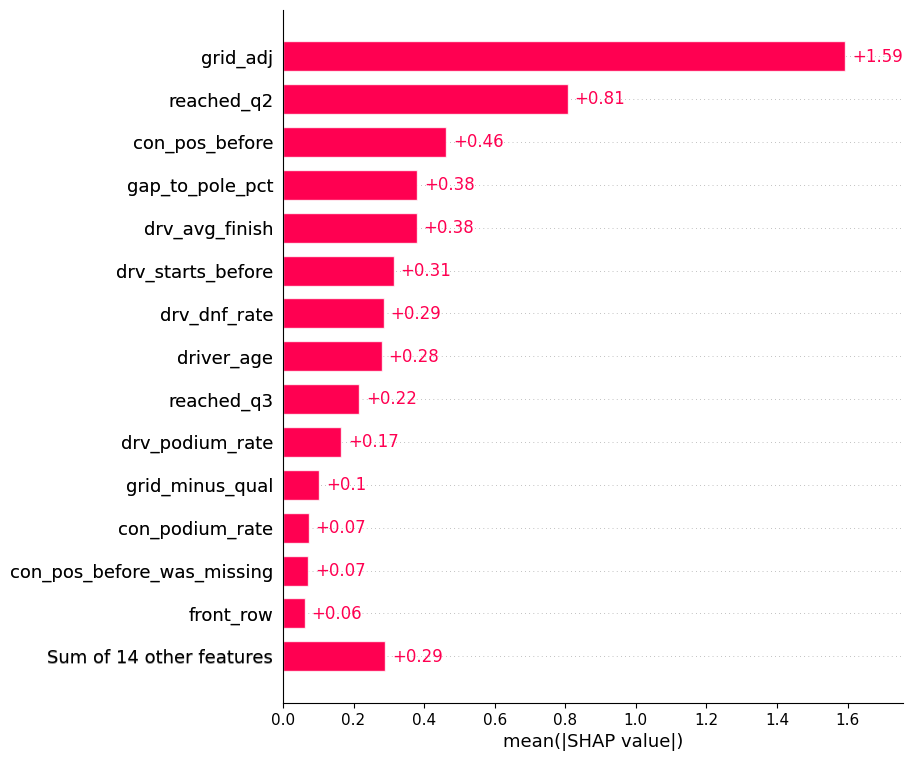

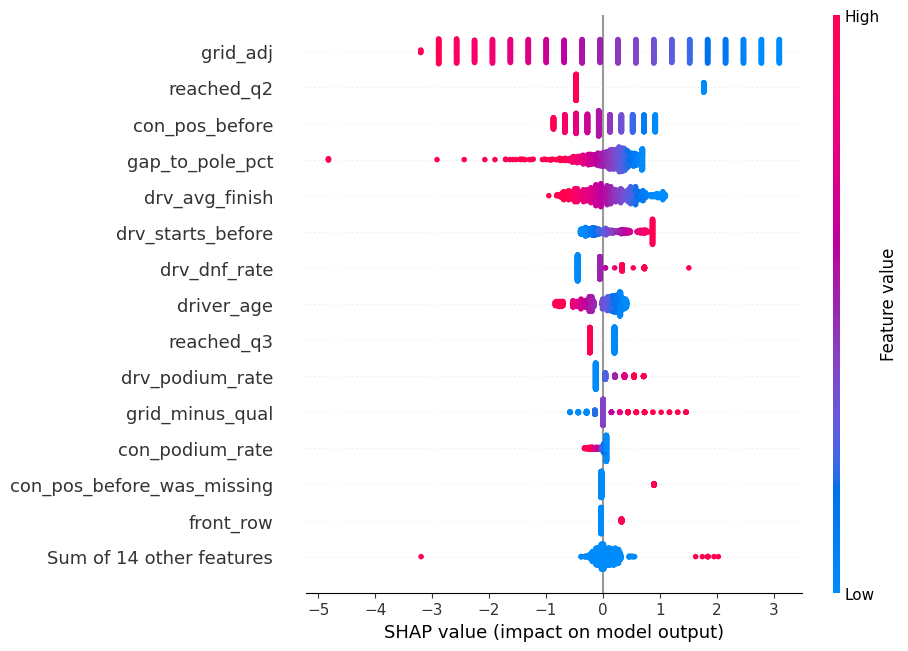

In [95]:
import shap

explainer = shap.LinearExplainer(lr_full, X_train[COLS])   # background = training data
sv = explainer(X_val[COLS])                                 # values are in log-odds units

shap.plots.bar(sv, max_display=15)        # mean |SHAP| per feature
shap.plots.beeswarm(sv, max_display=15)   # direction and spread per feature

**SHAP (global).** SHAP values are in log-odds of a podium. The mean absolute SHAP value is largest for `grid_adj` (1.59), then `reached_q2` (0.81), `con_pos_before` (0.46), `gap_to_pole_pct` (0.38) and `drv_avg_finish` (0.38), matching the permutation ranking.

The beeswarm shows direction. A worse starting slot (high `grid_adj`), a larger gap to pole, a worse constructor rank and a worse average finish all push the prediction down, as expected. More career starts and older/less experienced drivers behave in the way the linear model learned: `drv_starts_before` pushes up as it grows, and `driver_age` pushes down for the oldest drivers (a straight-line fit, even though Section C showed a peak at 31-34).

Some signs look backwards: reaching Q2 or Q3 pushes the prediction down, the few drivers who did not reach Q2 get a push up, and a higher DNF rate can push up. This is not a real effect of those variables. They are strongly correlated with grid position and gap to pole, so the linear model splits credit and uses them as small corrections (the same reason these weights have counter-intuitive signs in Step 2c). It is a clear example of why the sign of a feature's importance must not be read as a cause.

Max Verstappen - 2021 French Grand Prix (P(podium)=0.91, actual=1)


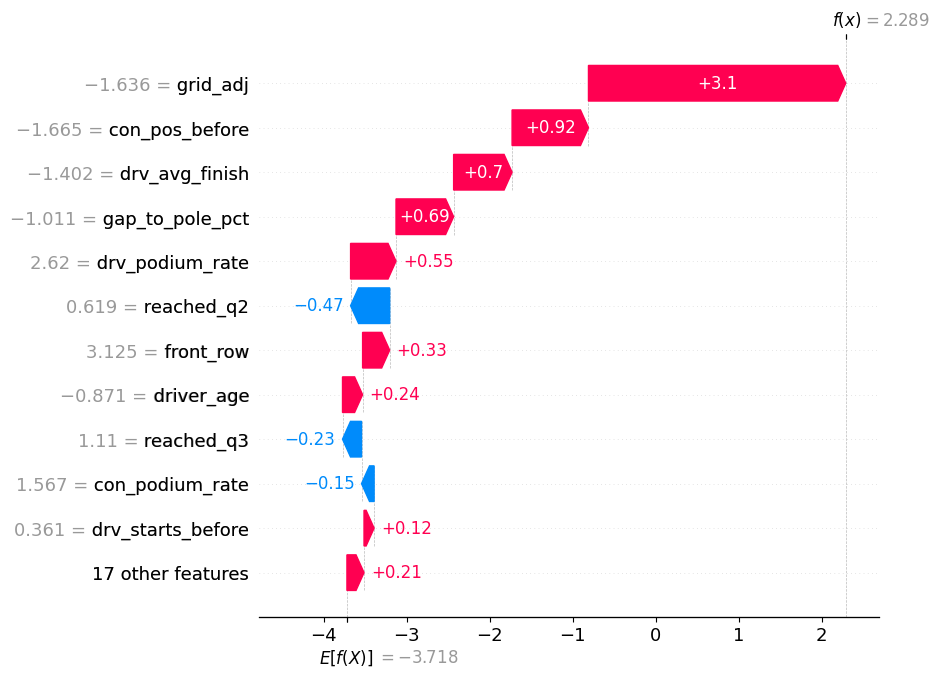

Lewis Hamilton - 2020 Italian Grand Prix (P(podium)=0.90, actual=0)


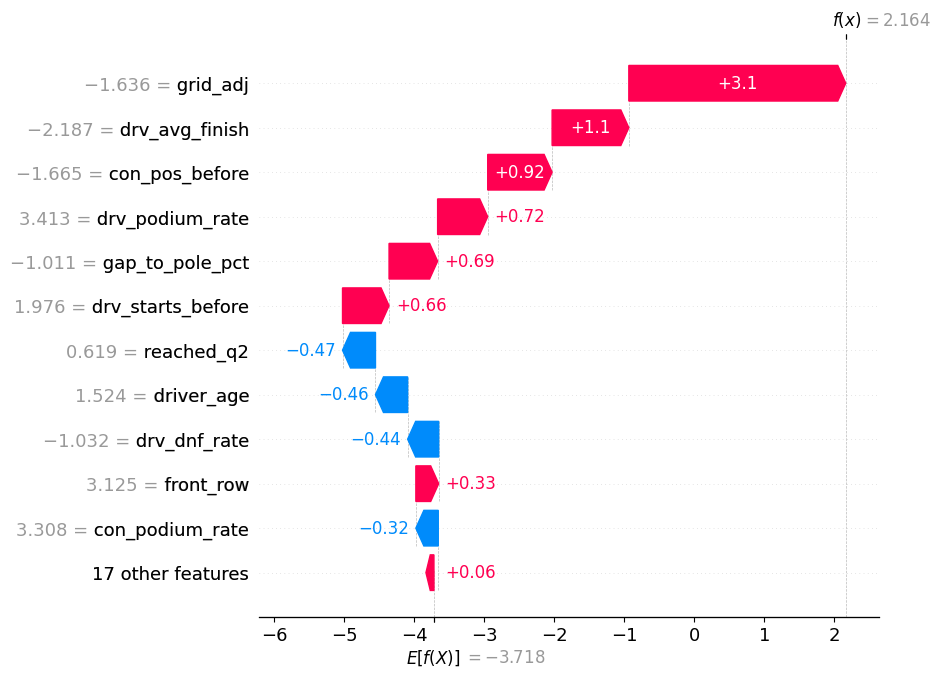

Sebastian Vettel - 2020 Turkish Grand Prix (P(podium)=0.00, actual=1)


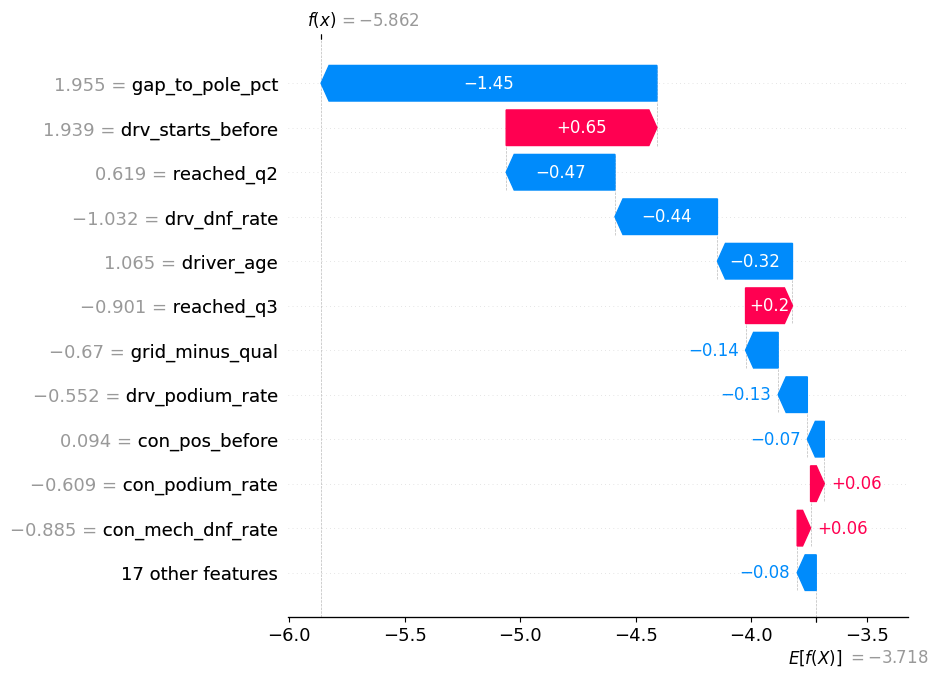

In [96]:
p_val = lr_full.predict_proba(X_val[COLS])[:, 1]
yv = y_val.values
pos = np.arange(len(p_val))
i_tp = pos[yv == 1][np.argmax(p_val[yv == 1])]    # most confident correct podium
i_fp = pos[yv == 0][np.argmax(p_val[yv == 0])]    # worst false alarm
i_fn = pos[yv == 1][np.argmin(p_val[yv == 1])]    # real podium the model missed

def describe(i):
    r = meta_val.iloc[i]
    d = df["drivers"].set_index("driverId").loc[r["driverId"]]
    rc = df["races"].set_index("raceId").loc[r["raceId"]]
    return f'{d["forename"]} {d["surname"]} - {int(rc["year"])} {rc["name"]} (P(podium)={p_val[i]:.2f}, actual={int(yv[i])})'

for i in [i_tp, i_fp, i_fn]:
    print(describe(i))
    shap.plots.waterfall(sv[i], max_display=12)

**SHAP (local).** Each waterfall starts from the average model output (about -3.72 log-odds, a very low podium probability) and adds each feature's push to reach the final prediction.

*Correct podium (Verstappen, 2021 French GP, predicted 0.91):* a front-row start (`grid_adj`, +3.1) is the main reason, helped by his team's championship position (+0.92), a strong recent average finish (+0.70), a small gap to pole (+0.69) and a high recent podium rate (+0.55). `reached_q2` pushes the other way (-0.47), the correlation artefact described above.

*False alarm (Hamilton, 2020 Italian GP, predicted 0.90, did not podium):* the explanation is almost the same as Verstappen's: a front-row start, a top team, and a very strong recent record. Everything the model can see before the race says "podium". In the race, Hamilton received a 10-second stop-and-go penalty for entering the pit lane while it was closed, dropped to last, and recovered to 7th. Such events are not pre-race information, so no pre-race model can avoid this error.

*Missed podium (Vettel, 2020 Turkish GP, predicted 0.00, did podium):* the strongest push is a very large gap to pole (`gap_to_pole_pct`, -1.45), followed by `reached_q2` (-0.47), his DNF rate (-0.44) and age (-0.32). The race and qualifying were run in wet, very slippery conditions that changed between sessions, which inflated his gap to pole; he started 11th and climbed to 3rd as the track dried. The model had no way to know the race would be that different from his qualifying form. This also exposes a feature limitation: `gap_to_pole_pct` compares laps set in different qualifying sessions, so changing weather makes it misleading.

Max Verstappen - 2021 French Grand Prix (P(podium)=0.91, actual=1)


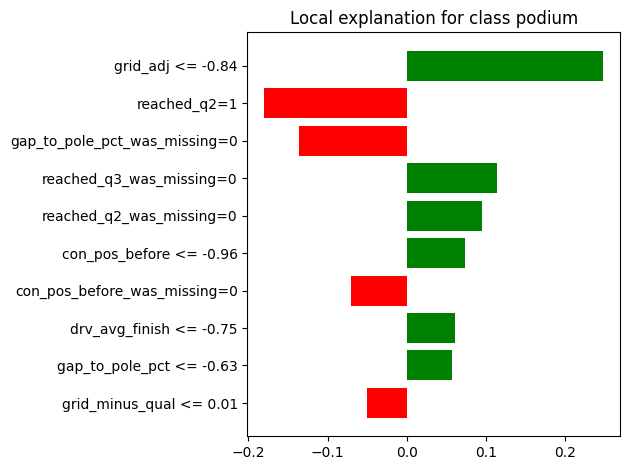

Lewis Hamilton - 2020 Italian Grand Prix (P(podium)=0.90, actual=0)


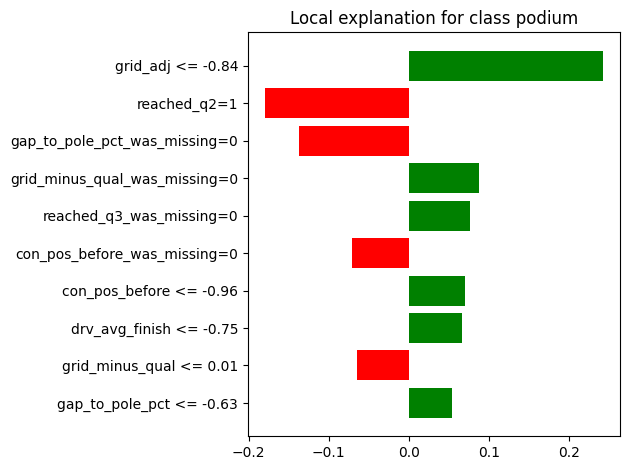

Sebastian Vettel - 2020 Turkish Grand Prix (P(podium)=0.00, actual=1)


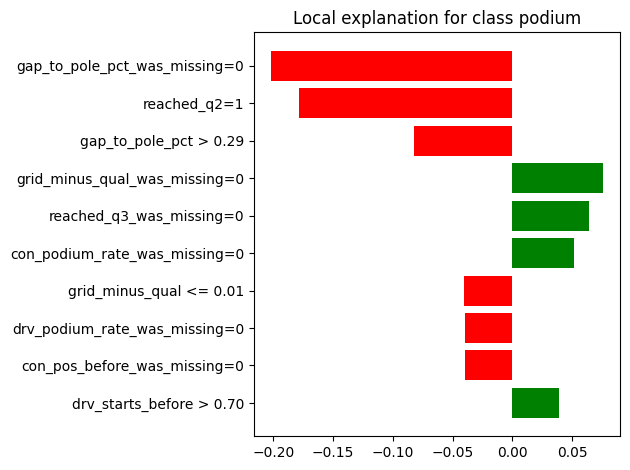

In [97]:
from lime.lime_tabular import LimeTabularExplainer

# Binary columns (missing-flags, reached_q2/q3, front_row...) must be treated as categorical by LIME.
# They are standardized in X, so map their two values to 0/1 for LIME and back for the model.
bin_cols = [c for c in COLS if X_train[c].nunique() == 2]
cat_idx = [COLS.index(c) for c in bin_cols]
lo = {c: X_train[c].min() for c in bin_cols}
hi = {c: X_train[c].max() for c in bin_cols}

def to_lime(frame):
    a = frame[COLS].copy()
    for c in bin_cols:
        a[c] = (a[c] > (lo[c] + hi[c]) / 2).astype(int)
    return a.values

def predict_fn(arr):
    d = pd.DataFrame(arr, columns=COLS)
    for c in bin_cols:
        d[c] = np.where(d[c] >= 0.5, hi[c], lo[c])
    return lr_full.predict_proba(d)

lime_exp = LimeTabularExplainer(to_lime(X_train), feature_names=COLS,
                                categorical_features=cat_idx,
                                class_names=["no podium", "podium"],
                                mode="classification", random_state=SEED)

for i in [i_tp, i_fp, i_fn]:
    print(describe(i))
    exp = lime_exp.explain_instance(to_lime(X_val.iloc[[i]])[0], predict_fn,
                                    num_features=10, num_samples=5000)
    exp.as_pyplot_figure(); plt.tight_layout(); plt.show()

**LIME (local).** LIME fits a simple local model around one prediction by perturbing the row, so it shows which feature values mattered for that case. Features are standardized, so ranges like `grid_adj <= -0.84` mean "more than 0.84 standard deviations better than the typical training starting slot", not raw grid positions.

For Verstappen (2021 French GP), the strongest supporting feature is `grid_adj <= -0.84` (a front-row start, about +0.25), followed by a good constructor rank, average finish and gap to pole (each about +0.06 to +0.07); `reached_q2 = 1` pushes against (about -0.18). This agrees with SHAP: starting position is the main reason, and `reached_q2` again appears with a counter-intuitive sign. Hamilton's false alarm (2020 Italian GP) gets an almost identical LIME explanation, confirming the SHAP finding that nothing in his pre-race data separated him from a real podium. For Vettel's missed podium (2020 Turkish GP), LIME, like SHAP, puts a large gap to pole (`gap_to_pole_pct > 0.29`) and `reached_q2` among the main negative factors.

One difference: LIME gives sizeable weight to several "was missing = 0" flags, which SHAP treats as almost irrelevant. LIME builds its explanation from random perturbed rows, and when it switches a flag to "missing", the standardized flag takes an extreme value the model rarely sees, so LIME over-credits "value present". This is an artefact of LIME's sampling, not something the model relies on for these drivers, and is a reason to trust SHAP more for this linear model.

LIME and SHAP use different methods (a local linear fit vs exact additive contributions for a linear model), so small differences in the ranking are expected. Neither shows causes.

**Summary of Requirement 6.** Permutation importance, SHAP and LIME agree that the model relies mostly on starting position, then on driver form, qualifying pace and championship standings, and barely on constructor form or driver age, which matches the ablation order. Several counter-intuitive signs (reached_q2, reached_q3, DNF rate) come from correlated features sharing credit in a linear model. These are explanations of the model's behaviour, not causal effects, and the false-alarm and missed-podium cases show that pre-race information cannot capture in-race events.

# Inference function
`predict_podium(record)` takes one driver's **pre-race** information (a dictionary of the 16 final features), applies the same preprocessing fitted on 2006-2019 (clip → median-impute + missing flag → scale) and the final logistic regression, and returns the podium probability and the yes/no decision at the threshold chosen on validation (0.22). Missing fields are allowed: they are filled with the training median and flagged, exactly as in training. Any field that is not a model input (e.g. post-race `points`) is rejected, so the function cannot leak race results.

In [98]:
# ===== Inference function =====
def predict_podium(record, model=lr_full, threshold=thr_lr):
    """record: dict {feature: value} with pre-race values for (some of) the 16 FINAL_FEATS.
    Missing / None values are imputed by the training pipeline. Returns probability + decision."""
    unknown = sorted(set(record) - set(FINAL_FEATS))
    if unknown:
        raise ValueError(f"Not a model input (post-race or unknown field): {unknown}")
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FINAL_FEATS}], dtype=float)
    filled = [f for f in FINAL_FEATS if pd.isna(row.at[0, f])]
    p = float(model.predict_proba(transform(row))[:, 1][0])     # same preprocessing as training
    return {"podium_probability": round(p, 3), "predicted_podium": bool(p >= threshold),
            "threshold": threshold, "features_filled_by_imputation": filled}

# Demo 1: a COMPLETE record (first test row with no missing feature that ended on the podium)
complete = te[FINAL_FEATS].notna().all(axis=1).values & (te[TARGET].values == 1)
pos = int(np.flatnonzero(complete)[0])
r = meta_test.iloc[pos]
who = df["drivers"].set_index("driverId").loc[r["driverId"]]
race = df["races"].set_index("raceId").loc[r["raceId"]]
print(f"Example: {who['forename']} {who['surname']} – {int(race['year'])} {race['name']} (actual podium = {int(y_test.iloc[pos])})")

full_record = te[FINAL_FEATS].iloc[pos].to_dict()
out_full = predict_podium(full_record)
print("Complete record:        ", out_full)
assert abs(out_full["podium_probability"] - predict(FINAL_CHOICE, "test")[pos]) < 1e-3   # same as the pipeline

# Demo 2: PARTIALLY MISSING record (e.g. no qualifying lap time, first race of the season = no standings yet)
partial = {k: v for k, v in full_record.items() if k not in ["gap_to_pole_pct", "drv_pos_before", "con_pos_before"]}
print("Partially missing record:", predict_podium(partial))

# Demo 3: the leakage guard – a post-race field is refused
try:
    predict_podium({**full_record, "points": 25})
except ValueError as e:
    print("Rejected:", e)

print("Real values that Demo 2 removed:", {k: full_record[k] for k in ["gap_to_pole_pct", "drv_pos_before", "con_pos_before"]})

Example: Max Verstappen – 2022 Saudi Arabian Grand Prix (actual podium = 1)
Complete record:         {'podium_probability': 0.331, 'predicted_podium': True, 'threshold': 0.22, 'features_filled_by_imputation': []}
Partially missing record: {'podium_probability': 0.848, 'predicted_podium': True, 'threshold': 0.22, 'features_filled_by_imputation': ['gap_to_pole_pct', 'drv_pos_before', 'con_pos_before']}
Rejected: Not a model input (post-race or unknown field): ['points']
Real values that Demo 2 removed: {'gap_to_pole_pct': 0.2959183673469339, 'drv_pos_before': 19.0, 'con_pos_before': 7.0}
